In [7]:
# ============================================================
# CELL 1: IMPORT REQUIRED LIBRARIES
# RiskWeave - Daily Weather Forecasting
# ============================================================

# Data manipulation
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Date and time
from datetime import timedelta

# Machine learning
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.preprocessing import LabelEncoder

# Model saving
import joblib

# File and directory management
from pathlib import Path

# Memory management
import gc

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

# Plot settings
sns.set_theme(style="whitegrid")

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [8]:
# ============================================================
# CELL 2: CONFIGURE PROJECT PATHS
# ============================================================

from pathlib import Path

# Identify project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Historical weather dataset
RAW_WEATHER_DIR = (
    PROJECT_ROOT / "data" / "raw" / "weather_era5_2006_2025"
)

WEATHER_FILE = (
    RAW_WEATHER_DIR /
    "weather_daily_era5_2006-12-23_to_2025-12-19.csv"
)

# Output directories
FORECAST_OUTPUT_DIR = (
    PROJECT_ROOT / "outputs" / "weather_forecasting"
)

REPORTS_DIR = (
    PROJECT_ROOT / "reports" / "weather_forecasting"
)

# Create directories
FORECAST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Display paths
print("Project root:", PROJECT_ROOT)
print("Weather dataset:", WEATHER_FILE)
print("Weather file exists:", WEATHER_FILE.exists())

print("\nForecast output directory:", FORECAST_OUTPUT_DIR)
print("Reports directory:", REPORTS_DIR)

Project root: c:\Users\Nethmi\Documents\GitHub\RiskWeave
Weather dataset: c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\raw\weather_era5_2006_2025\weather_daily_era5_2006-12-23_to_2025-12-19.csv
Weather file exists: True

Forecast output directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting
Reports directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave\reports\weather_forecasting


In [9]:
# ============================================================
# CELL 3: LOAD HISTORICAL WEATHER DATA
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# Load CSV dataset
weather = pd.read_csv(WEATHER_FILE)

# Convert date column to datetime
weather["date"] = pd.to_datetime(
    weather["date"],
    errors="coerce"
)

# Display dataset information
print("Historical weather dataset loaded successfully.")

print("\nDataset shape:")
print(weather.shape)

print("\nDataset columns:")
print(weather.columns.tolist())

print("\nFirst five records:")
display(weather.head())

print("\nLast five records:")
display(weather.tail())

Historical weather dataset loaded successfully.

Dataset shape:
(173425, 25)

Dataset columns:
['district', 'date', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'cloud_cover_mean', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'requested_latitude', 'requested_longitude', 'era5_grid_latitude', 'era5_grid_longitude', 'era5_grid_elevation_m', 'model', 'timezone']

First five records:


,district,date,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,wind_direction_10m_dominant,cloud_cover_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone
0,Ampara,2006-12-23,6.8,6.8,22.0,25.3,27.1,24.2,89,94,81,23.2,14.9,18.1,13,99,13.74,2.80,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
1,Ampara,2006-12-24,3.4,3.4,19.0,25.6,27.3,23.8,87,94,81,23.2,17.0,22.1,16,97,11.36,2.60,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
2,Ampara,2006-12-25,3.8,3.8,11.0,25.2,26.4,24.0,83,87,79,22.1,17.0,20.8,1,100,6.42,2.08,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
3,Ampara,2006-12-26,1.3,1.3,8.0,25.5,27.4,23.6,81,89,73,21.9,16.7,22.6,9,98,12.89,3.19,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
4,Ampara,2006-12-27,0.0,0.0,0.0,25.4,28.0,23.5,77,84,67,21.0,14.6,21.3,9,93,14.11,3.48,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo



Last five records:


,district,date,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,wind_direction_10m_dominant,cloud_cover_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone
173420,Vavuniya,2025-12-15,0.9,0.9,7.0,24.9,28.4,21.6,85,97,72,22.1,12.9,19.8,14,62,12.82,2.80,8.836117,80.486152,8.75,80.5,78.0,era5,Asia/Colombo
173421,Vavuniya,2025-12-16,2.7,2.7,10.0,25.9,28.9,23.6,90,99,74,24.0,10.8,16.7,66,92,13.70,2.78,8.836117,80.486152,8.75,80.5,78.0,era5,Asia/Colombo
173422,Vavuniya,2025-12-17,7.5,7.5,21.0,25.4,27.7,24.0,93,98,85,24.1,12.9,18.2,58,94,12.59,2.39,8.836117,80.486152,8.75,80.5,78.0,era5,Asia/Colombo
173423,Vavuniya,2025-12-18,6.1,6.1,17.0,25.0,26.7,23.7,93,100,87,23.7,13.1,17.0,37,93,11.03,2.10,8.836117,80.486152,8.75,80.5,78.0,era5,Asia/Colombo
173424,Vavuniya,2025-12-19,0.4,0.4,4.0,25.4,28.2,22.3,82,91,72,22.0,12.3,18.4,27,67,13.49,3.04,8.836117,80.486152,8.75,80.5,78.0,era5,Asia/Colombo


In [10]:
# ============================================================
# CELL 4: DATA STRUCTURE AND MISSING VALUE INSPECTION
# ============================================================

# Display column data types
print("DATA TYPES")
print("=" * 60)

display(weather.dtypes.to_frame(name="Data Type"))

# Check missing values
print("\nMISSING VALUE ANALYSIS")
print("=" * 60)

missing_summary = pd.DataFrame({
    "Missing_Count": weather.isnull().sum(),
    "Missing_Percentage": (
        weather.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

# Check duplicate records
print("\nDUPLICATE ANALYSIS")
print("=" * 60)

print(
    "Duplicate rows:",
    weather.duplicated().sum()
)

print(
    "Duplicate district-date combinations:",
    weather.duplicated(
        subset=["district", "date"]
    ).sum()
)

# Check dataset dimensions
print("\nDATASET DIMENSIONS")
print("=" * 60)

print("Rows:", weather.shape[0])
print("Columns:", weather.shape[1])

DATA TYPES


,Data Type
district,object
date,datetime64[ns]
precipitation_sum,float64
rain_sum,float64
precipitation_hours,float64
temperature_2m_mean,float64
temperature_2m_max,float64
temperature_2m_min,float64
relative_humidity_2m_mean,int64
relative_humidity_2m_max,int64



MISSING VALUE ANALYSIS


,Missing_Count,Missing_Percentage
district,0,0.0
date,0,0.0
precipitation_sum,0,0.0
rain_sum,0,0.0
precipitation_hours,0,0.0
temperature_2m_mean,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
relative_humidity_2m_mean,0,0.0
relative_humidity_2m_max,0,0.0



DUPLICATE ANALYSIS
Duplicate rows: 0
Duplicate district-date combinations: 0

DATASET DIMENSIONS
Rows: 173425
Columns: 25


In [11]:
# ============================================================
# CELL 5: CREATE WORKING COPY AND STANDARDISE DATA
# ============================================================

# Create a separate working copy
weather_clean = weather.copy()

# Standardise district names
weather_clean["district"] = (
    weather_clean["district"]
    .astype(str)
    .str.strip()
    .str.title()
)

# Ensure date is datetime
weather_clean["date"] = pd.to_datetime(
    weather_clean["date"],
    errors="coerce"
)

# Sort by district and date
weather_clean = weather_clean.sort_values(
    by=["district", "date"]
).reset_index(drop=True)

# Display results
print("Working dataset created successfully.")

print("\nDataset shape:", weather_clean.shape)

print("\nDistrict count:", weather_clean["district"].nunique())

print("\nDistrict names:")
print(sorted(weather_clean["district"].unique()))

print("\nDate range:")
print(weather_clean["date"].min(), "to", weather_clean["date"].max())

print("\nFirst five cleaned records:")
display(weather_clean.head())

Working dataset created successfully.

Dataset shape: (173425, 25)

District count: 25

District names:
['Ampara', 'Anuradhapura', 'Badulla', 'Batticaloa', 'Colombo', 'Galle', 'Gampaha', 'Hambantota', 'Jaffna', 'Kalutara', 'Kandy', 'Kegalle', 'Kilinochchi', 'Kurunegala', 'Mannar', 'Matale', 'Matara', 'Moneragala', 'Mullaitivu', 'Nuwara Eliya', 'Polonnaruwa', 'Puttalam', 'Ratnapura', 'Trincomalee', 'Vavuniya']

Date range:
2006-12-23 00:00:00 to 2025-12-19 00:00:00

First five cleaned records:


,district,date,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,wind_direction_10m_dominant,cloud_cover_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone
0,Ampara,2006-12-23,6.8,6.8,22.0,25.3,27.1,24.2,89,94,81,23.2,14.9,18.1,13,99,13.74,2.80,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
1,Ampara,2006-12-24,3.4,3.4,19.0,25.6,27.3,23.8,87,94,81,23.2,17.0,22.1,16,97,11.36,2.60,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
2,Ampara,2006-12-25,3.8,3.8,11.0,25.2,26.4,24.0,83,87,79,22.1,17.0,20.8,1,100,6.42,2.08,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
3,Ampara,2006-12-26,1.3,1.3,8.0,25.5,27.4,23.6,81,89,73,21.9,16.7,22.6,9,98,12.89,3.19,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
4,Ampara,2006-12-27,0.0,0.0,0.0,25.4,28.0,23.5,77,84,67,21.0,14.6,21.3,9,93,14.11,3.48,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo


In [12]:
# ============================================================
# CELL 6: CHECK DAILY DATE CONTINUITY
# ============================================================

continuity_results = []

for district, group in weather_clean.groupby("district"):

    district_dates = group["date"].sort_values()

    expected_dates = pd.date_range(
        start=district_dates.min(),
        end=district_dates.max(),
        freq="D"
    )

    missing_dates = expected_dates.difference(
        pd.DatetimeIndex(district_dates)
    )

    continuity_results.append({
        "district": district,
        "first_date": district_dates.min(),
        "last_date": district_dates.max(),
        "actual_records": len(district_dates),
        "expected_records": len(expected_dates),
        "missing_dates": len(missing_dates),
        "continuous": len(missing_dates) == 0
    })

continuity_df = pd.DataFrame(continuity_results)

# Display district-level continuity
display(continuity_df)

# Overall summary
print("\nDAILY CONTINUITY SUMMARY")
print("=" * 60)

print("Total districts:", len(continuity_df))

print(
    "Districts with continuous daily data:",
    continuity_df["continuous"].sum()
)

print(
    "Districts with missing dates:",
    (~continuity_df["continuous"]).sum()
)

print(
    "Total missing district-days:",
    continuity_df["missing_dates"].sum()
)

,district,first_date,last_date,actual_records,expected_records,missing_dates,continuous
0,Ampara,2006-12-23,2025-12-19,6937,6937,0,True
1,Anuradhapura,2006-12-23,2025-12-19,6937,6937,0,True
2,Badulla,2006-12-23,2025-12-19,6937,6937,0,True
3,Batticaloa,2006-12-23,2025-12-19,6937,6937,0,True
4,Colombo,2006-12-23,2025-12-19,6937,6937,0,True
5,Galle,2006-12-23,2025-12-19,6937,6937,0,True
6,Gampaha,2006-12-23,2025-12-19,6937,6937,0,True
7,Hambantota,2006-12-23,2025-12-19,6937,6937,0,True
8,Jaffna,2006-12-23,2025-12-19,6937,6937,0,True
9,Kalutara,2006-12-23,2025-12-19,6937,6937,0,True



DAILY CONTINUITY SUMMARY
Total districts: 25
Districts with continuous daily data: 25
Districts with missing dates: 0
Total missing district-days: 0


In [13]:
# ============================================================
# CELL 7: WEATHER VARIABLE STATISTICAL SUMMARY
# ============================================================

# Select important weather variables
WEATHER_VARIABLES = [
    "precipitation_sum",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "wind_speed_10m_mean",
    "cloud_cover_mean",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration"
]

# Generate descriptive statistics
weather_summary = weather_clean[
    WEATHER_VARIABLES
].describe().T

# Add median values
weather_summary["median"] = (
    weather_clean[WEATHER_VARIABLES].median()
)

# Display summary
print("WEATHER VARIABLE STATISTICAL SUMMARY")
print("=" * 65)

display(weather_summary.round(2))

# Check rainfall distribution
print("\nRAINFALL SUMMARY")
print("=" * 65)

print(
    "Days with zero rainfall:",
    (weather_clean["precipitation_sum"] == 0).sum()
)

print(
    "Days with rainfall:",
    (weather_clean["precipitation_sum"] > 0).sum()
)

print(
    "Maximum daily rainfall:",
    weather_clean["precipitation_sum"].max()
)

WEATHER VARIABLE STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max,median
precipitation_sum,173425.0,5.37,10.41,0.00,0.10,1.60,6.40,310.40,1.60
temperature_2m_mean,173425.0,26.18,3.31,8.50,25.40,26.60,28.10,32.90,26.60
temperature_2m_max,173425.0,30.00,3.65,10.30,28.60,30.30,32.10,41.10,30.30
temperature_2m_min,173425.0,23.37,3.45,4.00,22.30,24.00,25.50,30.60,24.00
relative_humidity_2m_mean,173425.0,80.82,8.28,36.00,75.00,82.00,87.00,99.00,82.00
wind_speed_10m_mean,173425.0,10.89,6.42,1.00,5.80,9.30,14.70,47.00,9.30
cloud_cover_mean,173425.0,73.54,24.58,0.00,57.00,81.00,95.00,100.00,81.00
shortwave_radiation_sum,173425.0,18.78,4.48,1.06,16.44,19.62,22.02,28.99,19.62
et0_fao_evapotranspiration,173425.0,4.16,1.22,0.36,3.37,4.15,4.98,8.49,4.15



RAINFALL SUMMARY
Days with zero rainfall: 39657
Days with rainfall: 133768
Maximum daily rainfall: 310.4


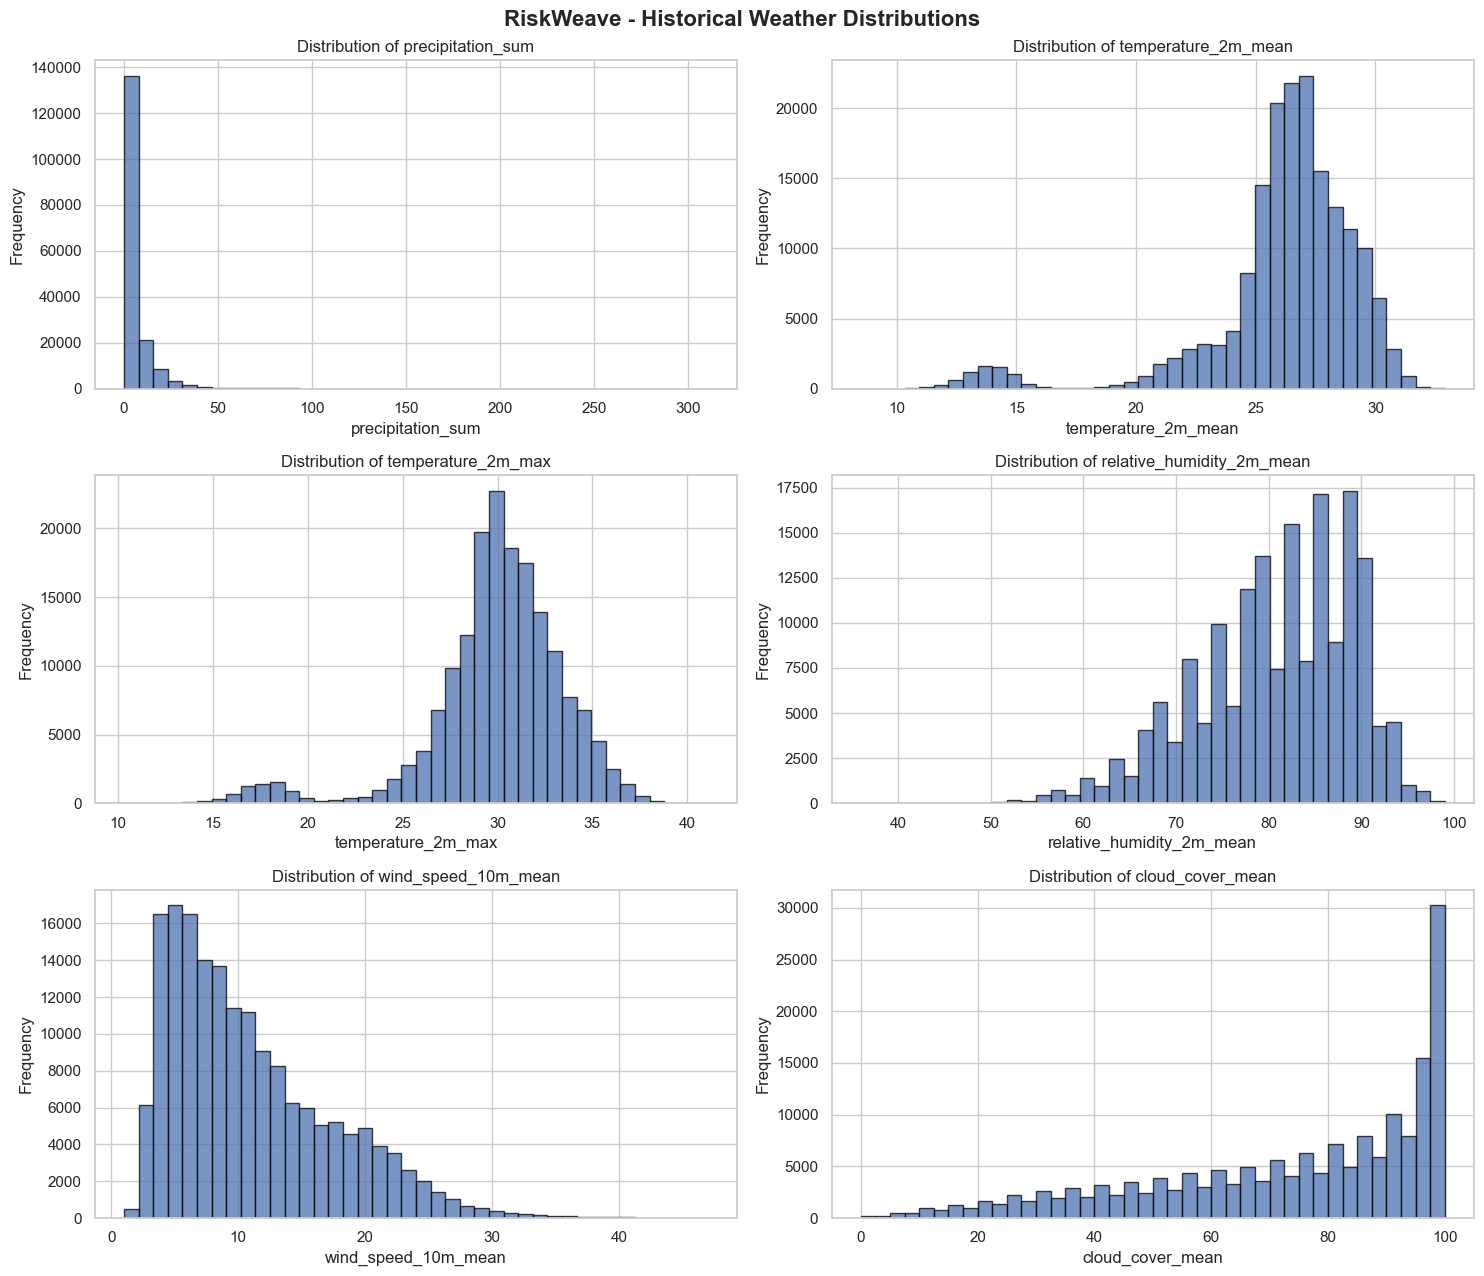

In [14]:
# ============================================================
# CELL 8: HISTORICAL WEATHER DISTRIBUTION VISUALISATION
# ============================================================

import matplotlib.pyplot as plt

# Variables to visualise
PLOT_VARIABLES = [
    "precipitation_sum",
    "temperature_2m_mean",
    "temperature_2m_max",
    "relative_humidity_2m_mean",
    "wind_speed_10m_mean",
    "cloud_cover_mean"
]

# Create histogram plots
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(15, 13)
)

axes = axes.flatten()

for i, variable in enumerate(PLOT_VARIABLES):

    axes[i].hist(
        weather_clean[variable],
        bins=40,
        edgecolor="black",
        alpha=0.75
    )

    axes[i].set_title(
        f"Distribution of {variable}"
    )

    axes[i].set_xlabel(variable)
    axes[i].set_ylabel("Frequency")

plt.suptitle(
    "RiskWeave - Historical Weather Distributions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

MONTHLY WEATHER SUMMARY


,month,mean_rainfall,mean_temperature,mean_humidity,month_name
0,1,4.20,24.44,81.95,January
1,2,2.94,25.16,79.52,February
2,3,3.20,26.29,78.81,March
3,4,5.21,27.00,81.31,April
4,5,5.58,27.40,81.27,May
5,6,3.51,27.37,78.22,June
6,7,3.25,27.18,76.82,July
7,8,3.87,26.91,77.57,August
8,9,4.47,26.72,78.68,September
9,10,9.18,25.95,83.15,October


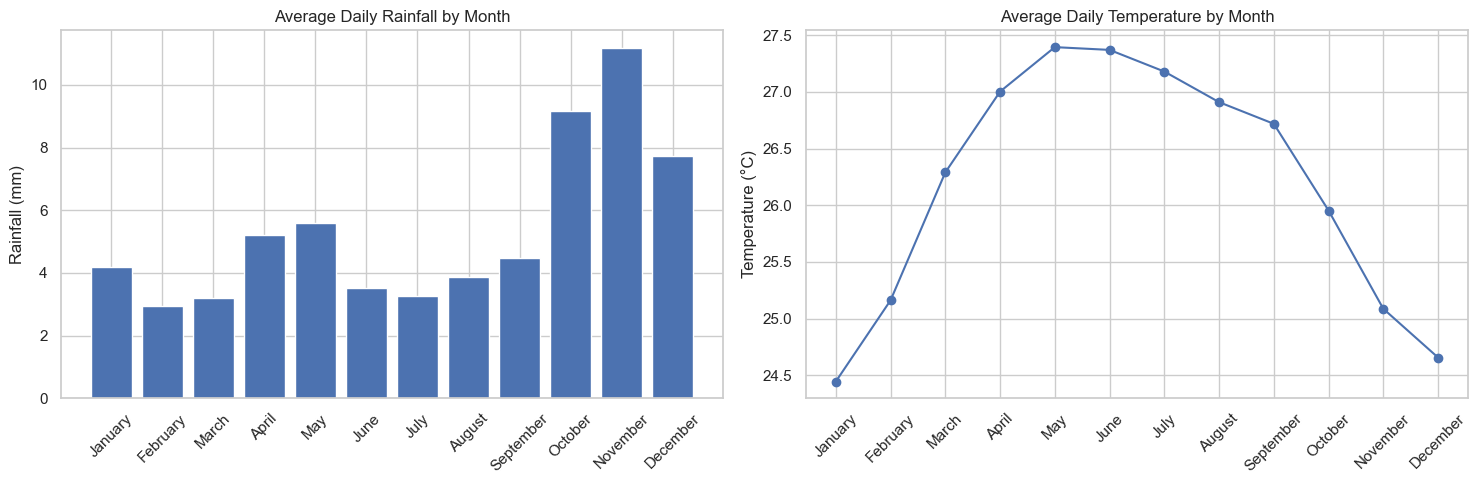

In [15]:
# ============================================================
# CELL 9: MONTHLY WEATHER PATTERN ANALYSIS
# ============================================================

# Extract calendar information
weather_clean["month"] = weather_clean["date"].dt.month

weather_clean["month_name"] = (
    weather_clean["date"].dt.month_name()
)

# Calculate monthly averages across all districts and years
monthly_weather = (
    weather_clean
    .groupby("month")
    .agg(
        mean_rainfall=("precipitation_sum", "mean"),
        mean_temperature=("temperature_2m_mean", "mean"),
        mean_humidity=("relative_humidity_2m_mean", "mean")
    )
    .reset_index()
)

# Add month names
monthly_weather["month_name"] = (
    pd.to_datetime(
        monthly_weather["month"],
        format="%m"
    ).dt.month_name()
)

print("MONTHLY WEATHER SUMMARY")
print("=" * 60)

display(monthly_weather.round(2))

# Plot monthly rainfall
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    monthly_weather["month_name"],
    monthly_weather["mean_rainfall"]
)

axes[0].set_title("Average Daily Rainfall by Month")
axes[0].set_ylabel("Rainfall (mm)")
axes[0].tick_params(axis="x", rotation=45)

# Plot monthly temperature
axes[1].plot(
    monthly_weather["month_name"],
    monthly_weather["mean_temperature"],
    marker="o"
)

axes[1].set_title("Average Daily Temperature by Month")
axes[1].set_ylabel("Temperature (°C)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

ANNUAL WEATHER SUMMARY


,year,annual_mean_rainfall,annual_mean_temperature,annual_mean_humidity
0,2006,1.59,23.98,79.56
1,2007,4.72,25.94,80.24
2,2008,5.84,25.86,81.08
3,2009,4.90,26.21,79.37
4,2010,6.21,26.17,81.09
5,2011,6.19,25.94,81.16
6,2012,4.83,26.14,79.39
7,2013,4.75,26.00,80.81
8,2014,6.20,26.08,80.59
9,2015,6.11,26.17,81.95


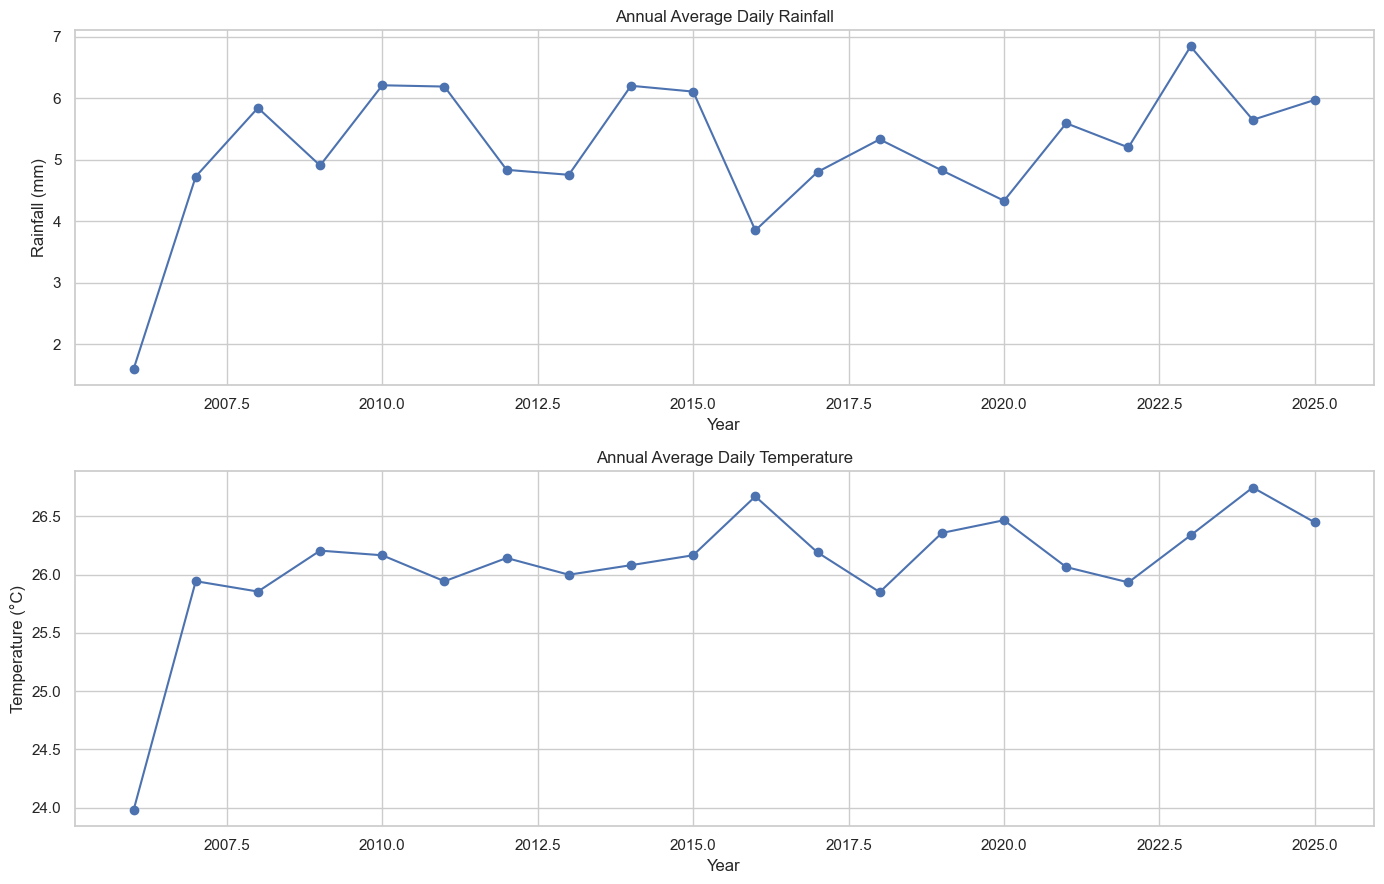

In [16]:
# ============================================================
# CELL 10: ANNUAL WEATHER TREND ANALYSIS
# ============================================================

# Extract year
weather_clean["year"] = weather_clean["date"].dt.year

# Calculate annual averages across all districts
annual_weather = (
    weather_clean
    .groupby("year")
    .agg(
        annual_mean_rainfall=("precipitation_sum", "mean"),
        annual_mean_temperature=("temperature_2m_mean", "mean"),
        annual_mean_humidity=("relative_humidity_2m_mean", "mean")
    )
    .reset_index()
)

print("ANNUAL WEATHER SUMMARY")
print("=" * 60)

display(annual_weather.round(2))

# Create annual trend charts
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Annual rainfall
axes[0].plot(
    annual_weather["year"],
    annual_weather["annual_mean_rainfall"],
    marker="o"
)

axes[0].set_title("Annual Average Daily Rainfall")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Rainfall (mm)")
axes[0].grid(True)

# Annual temperature
axes[1].plot(
    annual_weather["year"],
    annual_weather["annual_mean_temperature"],
    marker="o"
)

axes[1].set_title("Annual Average Daily Temperature")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Temperature (°C)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# CELL 11: VALIDATE ANNUAL SUMMARY
# ============================================================

# Check annual summary values and record counts
annual_validation = (
    weather_clean
    .groupby("year")
    .agg(
        record_count=("date", "count"),
        rainfall_count=("precipitation_sum", "count"),
        temperature_count=("temperature_2m_mean", "count"),
        humidity_count=("relative_humidity_2m_mean", "count"),
        rainfall_mean=("precipitation_sum", "mean"),
        temperature_mean=("temperature_2m_mean", "mean"),
        humidity_mean=("relative_humidity_2m_mean", "mean")
    )
    .reset_index()
)

print("ANNUAL DATA COMPLETENESS")
print("=" * 70)

display(annual_validation.tail(5).round(3))

# Inspect the final year separately
print("\n2025 VALIDATION")
print("=" * 70)

display(
    annual_validation[
        annual_validation["year"] == 2025
    ]
)

# Check missing values in annual summary
print("\nMissing annual summary values:")
print(annual_validation.isna().sum())

ANNUAL DATA COMPLETENESS


,year,record_count,rainfall_count,temperature_count,humidity_count,rainfall_mean,temperature_mean,humidity_mean
15,2021,9125,9125,9125,9125,5.591,26.065,82.178
16,2022,9125,9125,9125,9125,5.197,25.934,82.329
17,2023,9125,9125,9125,9125,6.839,26.337,82.388
18,2024,9150,9150,9150,9150,5.646,26.748,81.687
19,2025,8825,8825,8825,8825,5.971,26.448,81.227



2025 VALIDATION


,year,record_count,rainfall_count,temperature_count,humidity_count,rainfall_mean,temperature_mean,humidity_mean
19,2025,8825,8825,8825,8825,5.970958,26.447955,81.227195



Missing annual summary values:
year                 0
record_count         0
rainfall_count       0
temperature_count    0
humidity_count       0
rainfall_mean        0
temperature_mean     0
humidity_mean        0
dtype: int64


DISTRICT-LEVEL WEATHER SUMMARY


,district,mean_rainfall,mean_temperature,mean_max_temperature,mean_humidity,mean_wind_speed
11,Kegalle,10.49,25.33,29.21,84.94,5.91
22,Ratnapura,9.20,26.00,29.87,88.11,6.89
9,Kalutara,8.07,25.85,29.70,87.08,6.35
16,Matara,7.69,26.13,29.98,87.46,8.65
5,Galle,7.61,26.83,29.71,86.44,9.74
4,Colombo,7.56,27.14,30.53,83.97,8.23
19,Nuwara Eliya,7.29,13.78,17.69,85.30,6.64
6,Gampaha,7.17,27.50,31.15,81.99,8.72
2,Badulla,5.38,23.79,28.22,78.89,5.47
10,Kandy,5.24,21.76,25.73,82.94,7.39


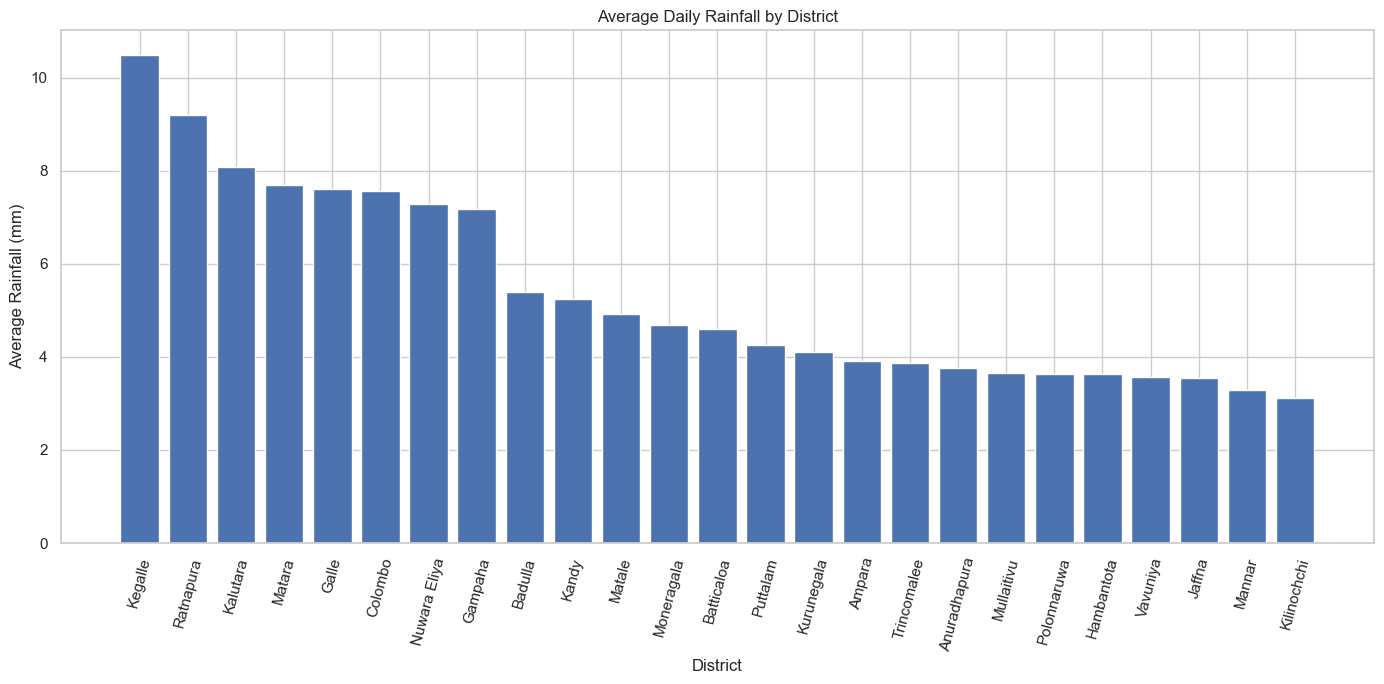

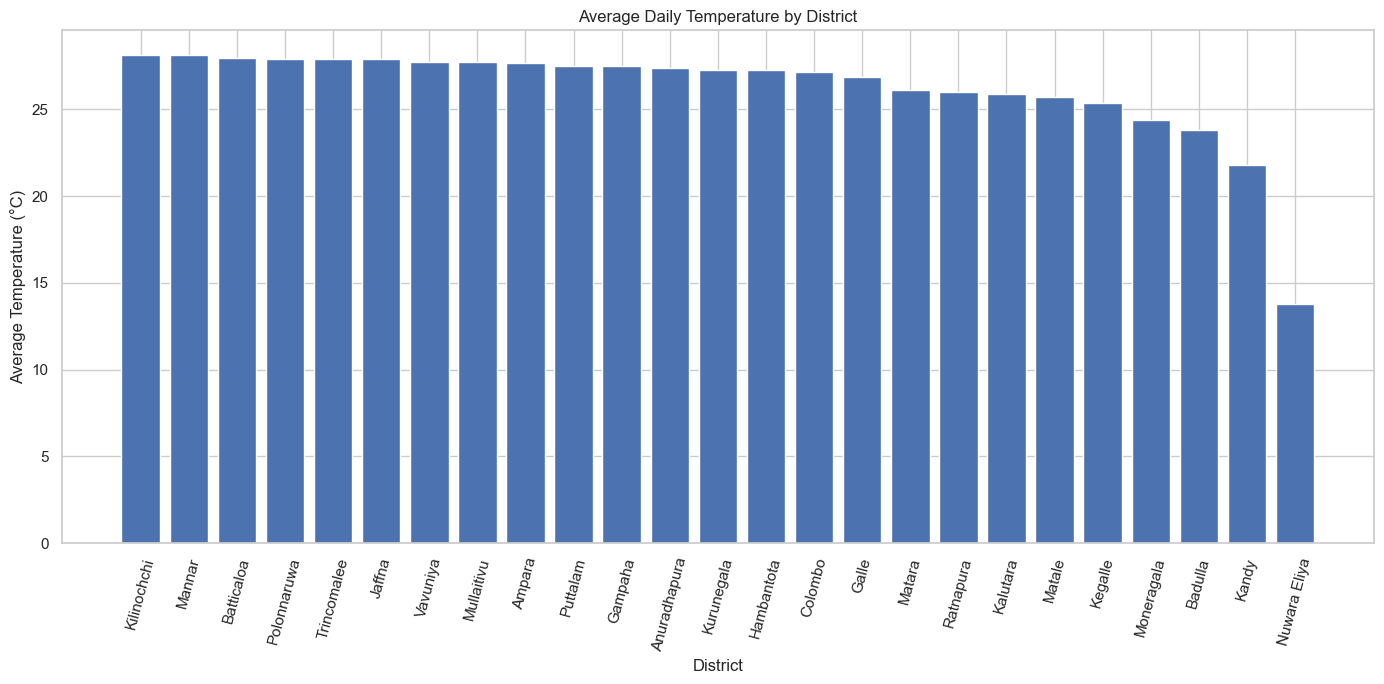

In [18]:
# ============================================================
# CELL 12: DISTRICT-LEVEL WEATHER ANALYSIS
# ============================================================

# Calculate average weather conditions for each district
district_weather_summary = (
    weather_clean
    .groupby("district")
    .agg(
        mean_rainfall=("precipitation_sum", "mean"),
        mean_temperature=("temperature_2m_mean", "mean"),
        mean_max_temperature=("temperature_2m_max", "mean"),
        mean_humidity=("relative_humidity_2m_mean", "mean"),
        mean_wind_speed=("wind_speed_10m_mean", "mean")
    )
    .reset_index()
)

# Sort districts by average rainfall
district_weather_summary = district_weather_summary.sort_values(
    "mean_rainfall",
    ascending=False
)

print("DISTRICT-LEVEL WEATHER SUMMARY")
print("=" * 70)

display(district_weather_summary.round(2))

# Plot average rainfall by district
plt.figure(figsize=(14, 7))

plt.bar(
    district_weather_summary["district"],
    district_weather_summary["mean_rainfall"]
)

plt.title("Average Daily Rainfall by District")
plt.xlabel("District")
plt.ylabel("Average Rainfall (mm)")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

# Plot average temperature by district
temperature_sorted = district_weather_summary.sort_values(
    "mean_temperature",
    ascending=False
)

plt.figure(figsize=(14, 7))

plt.bar(
    temperature_sorted["district"],
    temperature_sorted["mean_temperature"]
)

plt.title("Average Daily Temperature by District")
plt.xlabel("District")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

DISTRICT-LEVEL MONTHLY RAINFALL TABLE


month,1,2,3,4,5,6,7,8,9,10,11,12
district,,,,,,,,,,,,
Ampara,5.64,3.13,2.83,3.10,2.29,1.27,1.22,1.51,1.72,5.95,9.18,9.11
Anuradhapura,3.18,2.12,1.93,3.73,3.58,1.27,1.53,2.20,2.45,7.29,9.36,6.30
Badulla,5.14,3.40,3.44,6.30,5.95,2.15,2.31,2.93,4.28,9.88,10.82,7.93
Batticaloa,6.42,3.74,2.39,2.65,2.98,1.26,1.31,2.37,3.35,7.33,10.66,10.56
Colombo,3.30,2.93,4.25,7.21,10.22,9.20,6.98,7.24,8.43,11.71,11.81,7.20
Galle,4.15,3.50,4.35,7.55,10.40,8.32,6.79,7.47,8.74,10.71,11.92,7.25
Gampaha,2.59,2.19,3.80,6.47,9.50,8.90,6.99,7.26,8.14,12.24,11.52,6.19
Hambantota,3.47,2.10,3.07,4.76,3.33,0.83,0.68,1.12,1.97,5.63,9.58,6.89
Jaffna,2.50,1.10,1.01,1.74,2.44,1.08,1.35,2.12,2.28,7.49,12.14,7.22


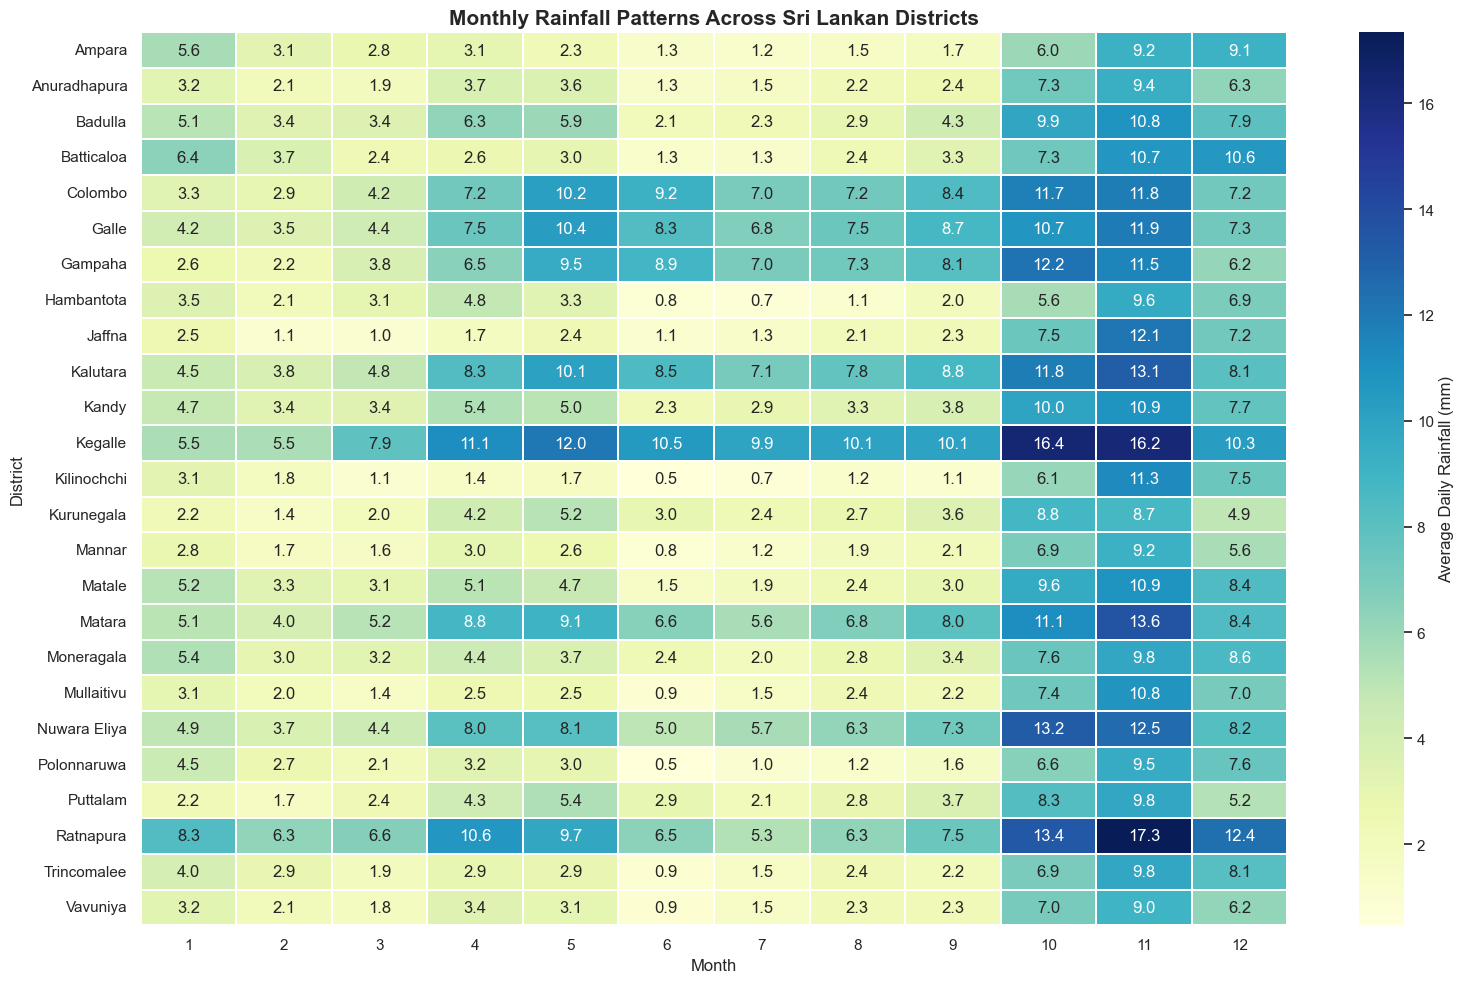

In [19]:
# ============================================================
# CELL 13: DISTRICT-LEVEL MONTHLY RAINFALL ANALYSIS
# ============================================================
import seaborn as sns
import matplotlib.pyplot as plt
# Calculate average rainfall for each district and month
district_monthly_rainfall = (
    weather_clean
    .groupby(["district", "month"])["precipitation_sum"]
    .mean()
    .reset_index()
)

# Create pivot table for visualisation
rainfall_pivot = district_monthly_rainfall.pivot(
    index="district",
    columns="month",
    values="precipitation_sum"
)

# Arrange districts alphabetically
rainfall_pivot = rainfall_pivot.sort_index()

print("DISTRICT-LEVEL MONTHLY RAINFALL TABLE")
print("=" * 70)

display(rainfall_pivot.round(2))

# Plot heatmap
plt.figure(figsize=(16, 10))

sns.heatmap(
    rainfall_pivot,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    cbar_kws={
        "label": "Average Daily Rainfall (mm)"
    }
)

plt.title(
    "Monthly Rainfall Patterns Across Sri Lankan Districts",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("District")

plt.tight_layout()
plt.show()

DISTRICT-LEVEL MONTHLY TEMPERATURE TABLE


month,1,2,3,4,5,6,7,8,9,10,11,12
district,,,,,,,,,,,,
Ampara,25.40,25.99,27.01,27.98,29.09,29.58,29.44,29.08,28.86,27.60,26.29,25.66
Anuradhapura,25.13,25.97,27.71,28.65,28.61,28.54,28.56,28.30,28.01,27.20,26.11,25.52
Badulla,21.28,21.80,22.99,24.01,25.21,25.65,25.76,25.51,25.02,23.76,22.54,21.86
Batticaloa,25.32,25.85,26.95,28.37,29.60,30.40,30.29,29.77,29.28,27.80,26.33,25.67
Colombo,26.69,27.42,27.89,27.84,27.86,27.49,27.20,27.01,26.92,26.66,26.41,26.35
Galle,26.18,26.80,27.40,27.49,27.58,27.20,26.93,26.74,26.67,26.49,26.31,26.22
Gampaha,27.09,28.13,28.65,28.32,28.16,27.71,27.46,27.27,27.15,26.87,26.65,26.61
Hambantota,25.79,26.50,27.18,27.60,28.09,28.23,28.25,28.02,27.74,27.16,26.30,25.90
Jaffna,25.94,26.48,27.86,29.20,29.43,29.13,28.81,28.41,28.29,27.74,26.83,26.23


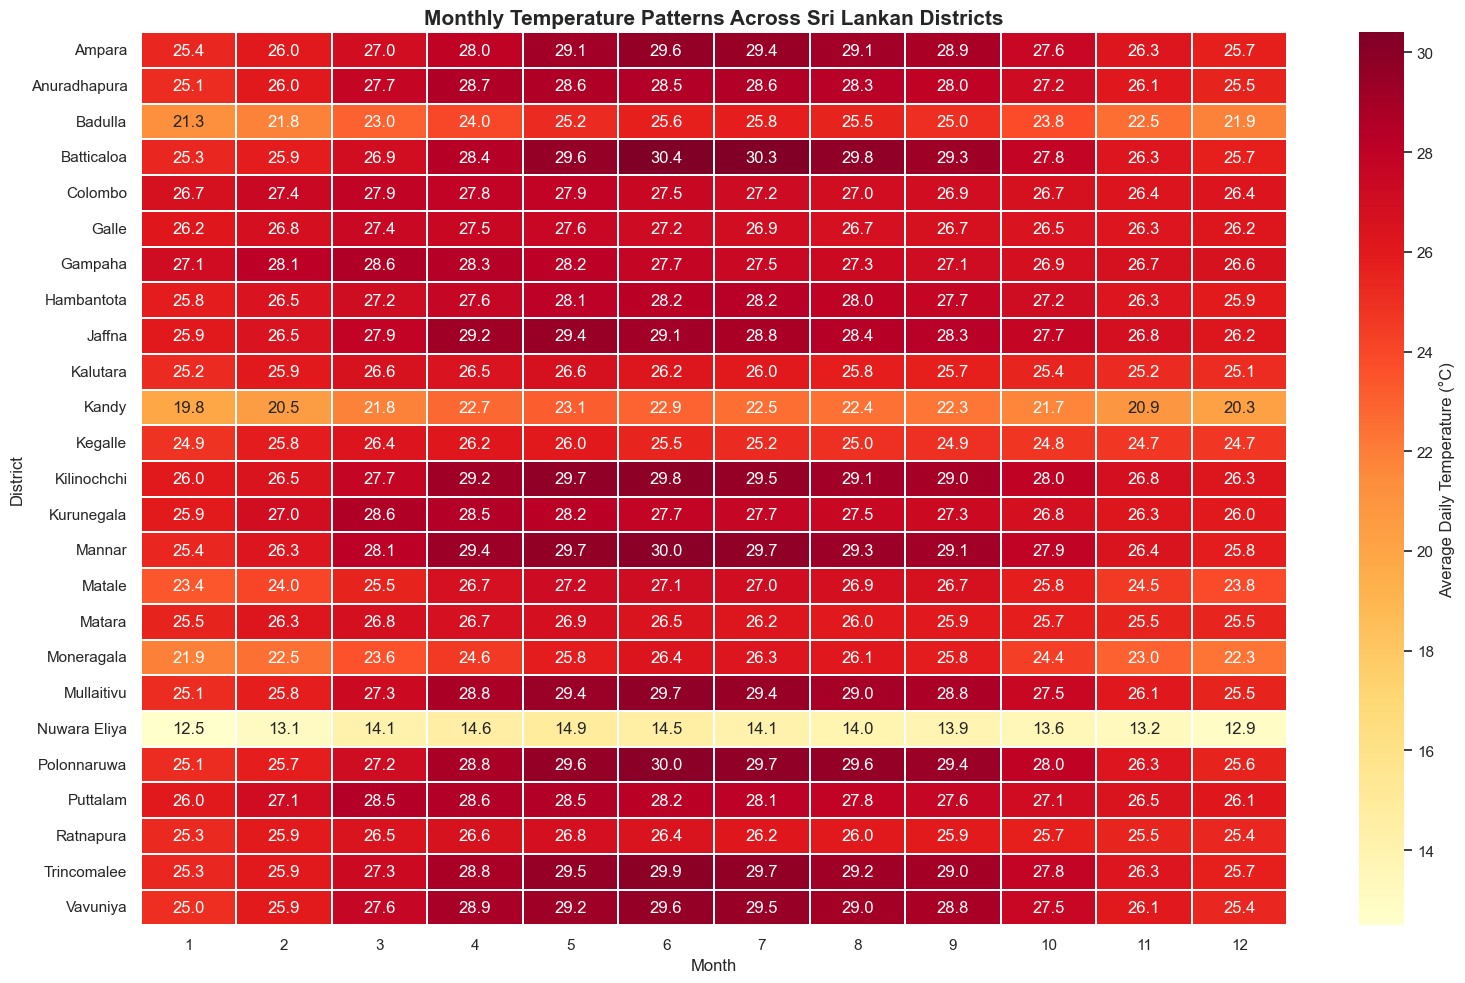

In [20]:
# ============================================================
# CELL 14: DISTRICT-LEVEL MONTHLY TEMPERATURE ANALYSIS
# ============================================================

# Calculate average temperature by district and month
district_monthly_temperature = (
    weather_clean
    .groupby(["district", "month"])["temperature_2m_mean"]
    .mean()
    .reset_index()
)

# Create pivot table
temperature_pivot = district_monthly_temperature.pivot(
    index="district",
    columns="month",
    values="temperature_2m_mean"
)

# Arrange districts alphabetically
temperature_pivot = temperature_pivot.sort_index()

print("DISTRICT-LEVEL MONTHLY TEMPERATURE TABLE")
print("=" * 70)

display(temperature_pivot.round(2))

# Plot heatmap
plt.figure(figsize=(16, 10))

sns.heatmap(
    temperature_pivot,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    cbar_kws={
        "label": "Average Daily Temperature (°C)"
    }
)

plt.title(
    "Monthly Temperature Patterns Across Sri Lankan Districts",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("District")

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# CELL 15: DEFINE FORECASTING TARGETS AND HORIZONS
# ============================================================

# Forecasting targets
TARGET_COLUMNS = [
    "precipitation_sum",
    "temperature_2m_mean"
]

# Daily forecasting horizons: 1 to 7 days
HORIZONS = list(range(1, 8))

# Define the historical training and evaluation periods
TRAIN_END = pd.Timestamp("2023-12-31")
VALIDATION_START = pd.Timestamp("2024-01-01")
VALIDATION_END = pd.Timestamp("2024-12-31")
TEST_START = pd.Timestamp("2025-01-01")
TEST_END = pd.Timestamp("2025-12-19")

# Identify the latest available historical observation
LATEST_AVAILABLE_DATE = weather_clean["date"].max()

print("=" * 65)
print("RISKWEAVE WEATHER FORECASTING CONFIGURATION")
print("=" * 65)

print("\nForecasting targets:")
for target in TARGET_COLUMNS:
    print("-", target)

print("\nForecast horizons:")
print(HORIZONS)

print("\nForecast frequency: Daily")

print("\nHistorical date range:")
print(weather_clean["date"].min().date(), "to",
      LATEST_AVAILABLE_DATE.date())

print("\nChronological data split:")
print("Training ends:", TRAIN_END.date())
print("Validation:", VALIDATION_START.date(), "to",
      VALIDATION_END.date())
print("Testing:", TEST_START.date(), "to",
      TEST_END.date())

print("\nDistrict count:",
      weather_clean["district"].nunique())

print("\nLatest available observation:",
      LATEST_AVAILABLE_DATE.date())

RISKWEAVE WEATHER FORECASTING CONFIGURATION

Forecasting targets:
- precipitation_sum
- temperature_2m_mean

Forecast horizons:
[1, 2, 3, 4, 5, 6, 7]

Forecast frequency: Daily

Historical date range:
2006-12-23 to 2025-12-19

Chronological data split:
Training ends: 2023-12-31
Validation: 2024-01-01 to 2024-12-31
Testing: 2025-01-01 to 2025-12-19

District count: 25

Latest available observation: 2025-12-19


In [22]:
# ============================================================
# CELL 16: CREATE HISTORICAL WEATHER FEATURES
# ============================================================

# Sort observations by district and date
weather_sorted = weather_clean.sort_values(
    ["district", "date"]
).reset_index(drop=True)

# Historical weather variables used to create lag features
BASE_WEATHER_FEATURES = [
    "precipitation_sum",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min",
    "dew_point_2m_mean",
    "wind_speed_10m_mean",
    "wind_speed_10m_max",
    "cloud_cover_mean",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration"
]

# Verify that all selected variables exist
missing_features = [
    col for col in BASE_WEATHER_FEATURES
    if col not in weather_sorted.columns
]

if missing_features:
    raise ValueError(
        f"Missing weather features: {missing_features}"
    )

# Start with district and date identifiers
feature_df = weather_sorted[
    ["district", "date"]
].copy()

# Create lag features using past observations only
LAG_DAYS = [1, 2, 3, 7, 14, 28]

for col in BASE_WEATHER_FEATURES:

    for lag in LAG_DAYS:

        feature_name = f"{col}_lag_{lag}"

        feature_df[feature_name] = (
            weather_sorted.groupby("district")[col]
            .shift(lag)
        )

# Create historical rolling averages
ROLLING_VARIABLES = [
    "precipitation_sum",
    "temperature_2m_mean"
]

ROLLING_WINDOWS = [7, 14, 30]

for col in ROLLING_VARIABLES:

    for window in ROLLING_WINDOWS:

        feature_name = f"{col}_rolling_mean_{window}"

        feature_df[feature_name] = (
            weather_sorted.groupby("district")[col]
            .transform(
                lambda series: (
                    series.shift(1)
                    .rolling(window=window, min_periods=window)
                    .mean()
                )
            )
        )

# Create calendar features for the forecast origin date
feature_df["origin_dayofyear_sin"] = np.sin(
    2 * np.pi * feature_df["date"].dt.dayofyear / 365.25
)

feature_df["origin_dayofyear_cos"] = np.cos(
    2 * np.pi * feature_df["date"].dt.dayofyear / 365.25
)

feature_df["origin_dayofweek"] = (
    feature_df["date"].dt.dayofweek
)

# Identify model predictor columns
FEATURE_COLUMNS = [
    col for col in feature_df.columns
    if col not in ["district", "date"]
]

print("Historical feature engineering completed.")
print("=" * 65)

print("Feature dataset shape:", feature_df.shape)

print("Number of districts:",
      feature_df["district"].nunique())

print("Number of predictors:", len(FEATURE_COLUMNS))

print("\nFirst 15 predictor names:")
print(FEATURE_COLUMNS[:15])

print("\nMissing values in engineered features:")
print(
    feature_df[FEATURE_COLUMNS]
    .isnull()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nSample engineered features:")
display(
    feature_df[
        ["district", "date"] + FEATURE_COLUMNS[:8]
    ].head(10)
)

Historical feature engineering completed.
Feature dataset shape: (173425, 89)
Number of districts: 25
Number of predictors: 87

First 15 predictor names:
['precipitation_sum_lag_1', 'precipitation_sum_lag_2', 'precipitation_sum_lag_3', 'precipitation_sum_lag_7', 'precipitation_sum_lag_14', 'precipitation_sum_lag_28', 'temperature_2m_mean_lag_1', 'temperature_2m_mean_lag_2', 'temperature_2m_mean_lag_3', 'temperature_2m_mean_lag_7', 'temperature_2m_mean_lag_14', 'temperature_2m_mean_lag_28', 'temperature_2m_max_lag_1', 'temperature_2m_max_lag_2', 'temperature_2m_max_lag_3']

Missing values in engineered features:
temperature_2m_mean_rolling_mean_30    750
precipitation_sum_rolling_mean_30      750
precipitation_sum_lag_28               700
relative_humidity_2m_mean_lag_28       700
temperature_2m_min_lag_28              700
temperature_2m_max_lag_28              700
temperature_2m_mean_lag_28             700
relative_humidity_2m_min_lag_28        700
relative_humidity_2m_max_lag_28      

,district,date,precipitation_sum_lag_1,precipitation_sum_lag_2,precipitation_sum_lag_3,precipitation_sum_lag_7,precipitation_sum_lag_14,precipitation_sum_lag_28,temperature_2m_mean_lag_1,temperature_2m_mean_lag_2
0,Ampara,2006-12-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Ampara,2006-12-24,6.8,NaN,NaN,NaN,NaN,NaN,25.3,NaN
2,Ampara,2006-12-25,3.4,6.8,NaN,NaN,NaN,NaN,25.6,25.3
3,Ampara,2006-12-26,3.8,3.4,6.8,NaN,NaN,NaN,25.2,25.6
4,Ampara,2006-12-27,1.3,3.8,3.4,NaN,NaN,NaN,25.5,25.2
5,Ampara,2006-12-28,0.0,1.3,3.8,NaN,NaN,NaN,25.4,25.5
6,Ampara,2006-12-29,0.0,0.0,1.3,NaN,NaN,NaN,25.2,25.4
7,Ampara,2006-12-30,0.0,0.0,0.0,6.8,NaN,NaN,25.2,25.2
8,Ampara,2006-12-31,0.0,0.0,0.0,3.4,NaN,NaN,24.5,25.2
9,Ampara,2007-01-01,0.0,0.0,0.0,3.8,NaN,NaN,24.3,24.5


In [23]:
# ============================================================
# CELL 17: CREATE FORECASTING TARGET DATASETS
# ============================================================

# Create a separate lookup Series for each target
target_lookup = {}

for target in TARGET_COLUMNS:

    target_lookup[target] = (
        weather_sorted
        .set_index(["district", "date"])[target]
    )

# Store the forecasting datasets
dataset_by_target = {}

for target in TARGET_COLUMNS:

    print(f"\nProcessing target: {target}")

    # Select the correct one-dimensional target Series
    target_series = target_lookup[target]

    for horizon in HORIZONS:

        # Copy historical features
        frame = feature_df.copy()

        # Calculate the future target date
        frame["target_date"] = (
            frame["date"] +
            pd.to_timedelta(horizon, unit="D")
        )

        # Create district-date keys for future target lookup
        keys = pd.MultiIndex.from_arrays(
            [
                frame["district"].values,
                frame["target_date"].values
            ],
            names=["district", "date"]
        )

        # Retrieve future target values
        future_values = target_series.reindex(keys).to_numpy()

        # Store target values
        frame["y"] = future_values

        # Add known future calendar features
        frame["target_dayofyear_sin"] = np.sin(
            2 * np.pi *
            frame["target_date"].dt.dayofyear / 365.25
        )

        frame["target_dayofyear_cos"] = np.cos(
            2 * np.pi *
            frame["target_date"].dt.dayofyear / 365.25
        )

        frame["target_month"] = (
            frame["target_date"].dt.month
        )

        # Remove rows without an available future target
        frame = frame.dropna(subset=["y"]).reset_index(drop=True)

        # Save dataset using target and horizon as key
        dataset_by_target[(target, horizon)] = frame

        print(
            f"Horizon {horizon}: "
            f"{len(frame):,} records | "
            f"Target dates: "
            f"{frame['target_date'].min().date()} to "
            f"{frame['target_date'].max().date()}"
        )

# Final summary
print("\n" + "=" * 65)
print("FORECASTING TARGET DATASETS CREATED")
print("=" * 65)

print("Total datasets:", len(dataset_by_target))

for target in TARGET_COLUMNS:

    count = sum(
        1 for key in dataset_by_target
        if key[0] == target
    )

    print(f"{target}: {count} datasets")

# Inspect one dataset
sample_dataset = dataset_by_target[
    ("precipitation_sum", 1)
]

print("\nSample dataset shape:", sample_dataset.shape)

display(
    sample_dataset[
        [
            "district",
            "date",
            "target_date",
            "y",
            "target_month"
        ]
    ].head(10)
)


Processing target: precipitation_sum
Horizon 1: 173,400 records | Target dates: 2006-12-24 to 2025-12-19
Horizon 2: 173,375 records | Target dates: 2006-12-25 to 2025-12-19
Horizon 3: 173,350 records | Target dates: 2006-12-26 to 2025-12-19
Horizon 4: 173,325 records | Target dates: 2006-12-27 to 2025-12-19
Horizon 5: 173,300 records | Target dates: 2006-12-28 to 2025-12-19
Horizon 6: 173,275 records | Target dates: 2006-12-29 to 2025-12-19
Horizon 7: 173,250 records | Target dates: 2006-12-30 to 2025-12-19

Processing target: temperature_2m_mean
Horizon 1: 173,400 records | Target dates: 2006-12-24 to 2025-12-19
Horizon 2: 173,375 records | Target dates: 2006-12-25 to 2025-12-19
Horizon 3: 173,350 records | Target dates: 2006-12-26 to 2025-12-19
Horizon 4: 173,325 records | Target dates: 2006-12-27 to 2025-12-19
Horizon 5: 173,300 records | Target dates: 2006-12-28 to 2025-12-19
Horizon 6: 173,275 records | Target dates: 2006-12-29 to 2025-12-19
Horizon 7: 173,250 records | Target da

,district,date,target_date,y,target_month
0,Ampara,2006-12-23,2006-12-24,3.4,12
1,Ampara,2006-12-24,2006-12-25,3.8,12
2,Ampara,2006-12-25,2006-12-26,1.3,12
3,Ampara,2006-12-26,2006-12-27,0.0,12
4,Ampara,2006-12-27,2006-12-28,0.0,12
5,Ampara,2006-12-28,2006-12-29,0.0,12
6,Ampara,2006-12-29,2006-12-30,0.0,12
7,Ampara,2006-12-30,2006-12-31,0.0,12
8,Ampara,2006-12-31,2007-01-01,0.0,1
9,Ampara,2007-01-01,2007-01-02,0.0,1


In [24]:
# ============================================================
# CELL 18: CHRONOLOGICAL TRAINING, VALIDATION AND TEST SPLIT
# ============================================================

# Store the split datasets
split_datasets = {}

for (target, horizon), frame in dataset_by_target.items():

    # Training: target dates up to 31 December 2023
    train_data = frame[
        frame["target_date"] <= TRAIN_END
    ].copy()

    # Validation: target dates during 2024
    validation_data = frame[
        (frame["target_date"] >= VALIDATION_START) &
        (frame["target_date"] <= VALIDATION_END)
    ].copy()

    # Testing: target dates during 2025
    test_data = frame[
        (frame["target_date"] >= TEST_START) &
        (frame["target_date"] <= TEST_END)
    ].copy()

    # Save the three datasets
    split_datasets[(target, horizon)] = {
        "train": train_data,
        "validation": validation_data,
        "test": test_data
    }

# Display split summary
print("=" * 75)
print("CHRONOLOGICAL FORECASTING DATA SPLIT")
print("=" * 75)

for target in TARGET_COLUMNS:

    print(f"\nTARGET: {target}")

    for horizon in HORIZONS:

        parts = split_datasets[(target, horizon)]

        print(
            f"Horizon {horizon}: "
            f"Train = {len(parts['train']):,}, "
            f"Validation = {len(parts['validation']):,}, "
            f"Test = {len(parts['test']):,}"
        )

# Validate the split dates
print("\n" + "=" * 75)
print("DATE BOUNDARY VALIDATION")
print("=" * 75)

for key, parts in split_datasets.items():

    train_data = parts["train"]
    validation_data = parts["validation"]
    test_data = parts["test"]

    assert train_data["target_date"].max() <= TRAIN_END

    assert validation_data["target_date"].min() >= VALIDATION_START
    assert validation_data["target_date"].max() <= VALIDATION_END

    assert test_data["target_date"].min() >= TEST_START
    assert test_data["target_date"].max() <= TEST_END

print("All chronological split checks passed.")

# Inspect one example
example_parts = split_datasets[
    ("precipitation_sum", 1)
]

print("\nExample: Rainfall, 1-day horizon")

for split_name, split_frame in example_parts.items():

    print(f"\n{split_name.upper()}")

    print("Records:", len(split_frame))

    print(
        "Target date range:",
        split_frame["target_date"].min().date(),
        "to",
        split_frame["target_date"].max().date()
    )

CHRONOLOGICAL FORECASTING DATA SPLIT

TARGET: precipitation_sum
Horizon 1: Train = 155,425, Validation = 9,150, Test = 8,825
Horizon 2: Train = 155,400, Validation = 9,150, Test = 8,825
Horizon 3: Train = 155,375, Validation = 9,150, Test = 8,825
Horizon 4: Train = 155,350, Validation = 9,150, Test = 8,825
Horizon 5: Train = 155,325, Validation = 9,150, Test = 8,825
Horizon 6: Train = 155,300, Validation = 9,150, Test = 8,825
Horizon 7: Train = 155,275, Validation = 9,150, Test = 8,825

TARGET: temperature_2m_mean
Horizon 1: Train = 155,425, Validation = 9,150, Test = 8,825
Horizon 2: Train = 155,400, Validation = 9,150, Test = 8,825
Horizon 3: Train = 155,375, Validation = 9,150, Test = 8,825
Horizon 4: Train = 155,350, Validation = 9,150, Test = 8,825
Horizon 5: Train = 155,325, Validation = 9,150, Test = 8,825
Horizon 6: Train = 155,300, Validation = 9,150, Test = 8,825
Horizon 7: Train = 155,275, Validation = 9,150, Test = 8,825

DATE BOUNDARY VALIDATION
All chronological split che

In [25]:
# ============================================================
# CELL 19: DEFINE MODEL FEATURES AND CHECK DATA LEAKAGE
# ============================================================

# Target-date calendar features are known in advance
TARGET_CALENDAR_FEATURES = [
    "target_dayofyear_sin",
    "target_dayofyear_cos",
    "target_month"
]

# Final model predictors
MODEL_FEATURE_COLUMNS = (
    ["district"]
    + FEATURE_COLUMNS
    + TARGET_CALENDAR_FEATURES
)

# Remove duplicate column names while preserving order
MODEL_FEATURE_COLUMNS = list(
    dict.fromkeys(MODEL_FEATURE_COLUMNS)
)

print("=" * 65)
print("WEATHER FORECASTING MODEL FEATURE CONFIGURATION")
print("=" * 65)

print("\nTotal model predictors:", len(MODEL_FEATURE_COLUMNS))

print("\nCategorical predictors:")
print(["district"])

print("\nNumeric predictor count:",
      len(MODEL_FEATURE_COLUMNS) - 1)

# Check feature availability in every forecasting dataset
missing_feature_columns = []

for key, frame in dataset_by_target.items():

    missing = [
        col for col in MODEL_FEATURE_COLUMNS
        if col not in frame.columns
    ]

    if missing:
        missing_feature_columns.append((key, missing))

if missing_feature_columns:
    raise ValueError(
        f"Missing model features: {missing_feature_columns}"
    )

# Check that actual targets and future dates are not predictors
FORBIDDEN_FEATURES = [
    "y",
    "target_date",
    "precipitation_sum",
    "temperature_2m_mean"
]

leakage_features = [
    col for col in MODEL_FEATURE_COLUMNS
    if col in FORBIDDEN_FEATURES
]

if leakage_features:
    raise ValueError(
        f"Potential target leakage detected: {leakage_features}"
    )

# Verify that historical lag and rolling features are shifted
assert all(
    "_lag_" in col or "_rolling_mean_" in col
    or col in [
        "origin_dayofyear_sin",
        "origin_dayofyear_cos",
        "origin_dayofweek"
    ]
    for col in FEATURE_COLUMNS
)

print("\nFeature availability check: PASSED")
print("Target leakage check: PASSED")
print("Historical feature check: PASSED")

print("\nFirst 15 model predictors:")
print(MODEL_FEATURE_COLUMNS[:15])

print("\nSample model input:")
display(
    dataset_by_target[("precipitation_sum", 1)][
        MODEL_FEATURE_COLUMNS
    ].head()
)

WEATHER FORECASTING MODEL FEATURE CONFIGURATION

Total model predictors: 91

Categorical predictors:
['district']

Numeric predictor count: 90

Feature availability check: PASSED
Target leakage check: PASSED
Historical feature check: PASSED

First 15 model predictors:
['district', 'precipitation_sum_lag_1', 'precipitation_sum_lag_2', 'precipitation_sum_lag_3', 'precipitation_sum_lag_7', 'precipitation_sum_lag_14', 'precipitation_sum_lag_28', 'temperature_2m_mean_lag_1', 'temperature_2m_mean_lag_2', 'temperature_2m_mean_lag_3', 'temperature_2m_mean_lag_7', 'temperature_2m_mean_lag_14', 'temperature_2m_mean_lag_28', 'temperature_2m_max_lag_1', 'temperature_2m_max_lag_2']

Sample model input:


,district,precipitation_sum_lag_1,precipitation_sum_lag_2,precipitation_sum_lag_3,precipitation_sum_lag_7,precipitation_sum_lag_14,precipitation_sum_lag_28,temperature_2m_mean_lag_1,temperature_2m_mean_lag_2,temperature_2m_mean_lag_3,temperature_2m_mean_lag_7,temperature_2m_mean_lag_14,temperature_2m_mean_lag_28,temperature_2m_max_lag_1,temperature_2m_max_lag_2,temperature_2m_max_lag_3,temperature_2m_max_lag_7,temperature_2m_max_lag_14,temperature_2m_max_lag_28,temperature_2m_min_lag_1,temperature_2m_min_lag_2,temperature_2m_min_lag_3,temperature_2m_min_lag_7,temperature_2m_min_lag_14,temperature_2m_min_lag_28,relative_humidity_2m_mean_lag_1,relative_humidity_2m_mean_lag_2,relative_humidity_2m_mean_lag_3,relative_humidity_2m_mean_lag_7,relative_humidity_2m_mean_lag_14,relative_humidity_2m_mean_lag_28,relative_humidity_2m_max_lag_1,relative_humidity_2m_max_lag_2,relative_humidity_2m_max_lag_3,relative_humidity_2m_max_lag_7,relative_humidity_2m_max_lag_14,relative_humidity_2m_max_lag_28,relative_humidity_2m_min_lag_1,relative_humidity_2m_min_lag_2,relative_humidity_2m_min_lag_3,relative_humidity_2m_min_lag_7,relative_humidity_2m_min_lag_14,relative_humidity_2m_min_lag_28,dew_point_2m_mean_lag_1,dew_point_2m_mean_lag_2,dew_point_2m_mean_lag_3,dew_point_2m_mean_lag_7,dew_point_2m_mean_lag_14,dew_point_2m_mean_lag_28,wind_speed_10m_mean_lag_1,wind_speed_10m_mean_lag_2,wind_speed_10m_mean_lag_3,wind_speed_10m_mean_lag_7,wind_speed_10m_mean_lag_14,wind_speed_10m_mean_lag_28,wind_speed_10m_max_lag_1,wind_speed_10m_max_lag_2,wind_speed_10m_max_lag_3,wind_speed_10m_max_lag_7,wind_speed_10m_max_lag_14,wind_speed_10m_max_lag_28,cloud_cover_mean_lag_1,cloud_cover_mean_lag_2,cloud_cover_mean_lag_3,cloud_cover_mean_lag_7,cloud_cover_mean_lag_14,cloud_cover_mean_lag_28,shortwave_radiation_sum_lag_1,shortwave_radiation_sum_lag_2,shortwave_radiation_sum_lag_3,shortwave_radiation_sum_lag_7,shortwave_radiation_sum_lag_14,shortwave_radiation_sum_lag_28,et0_fao_evapotranspiration_lag_1,et0_fao_evapotranspiration_lag_2,et0_fao_evapotranspiration_lag_3,et0_fao_evapotranspiration_lag_7,et0_fao_evapotranspiration_lag_14,et0_fao_evapotranspiration_lag_28,precipitation_sum_rolling_mean_7,precipitation_sum_rolling_mean_14,precipitation_sum_rolling_mean_30,temperature_2m_mean_rolling_mean_7,temperature_2m_mean_rolling_mean_14,temperature_2m_mean_rolling_mean_30,origin_dayofyear_sin,origin_dayofyear_cos,origin_dayofweek,target_dayofyear_sin,target_dayofyear_cos,target_month
0,Ampara,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.141444,0.989946,5,-0.124395,0.992233,12
1,Ampara,6.8,NaN,NaN,NaN,NaN,NaN,25.3,NaN,NaN,NaN,NaN,NaN,27.1,NaN,NaN,NaN,NaN,NaN,24.2,NaN,NaN,NaN,NaN,NaN,89.0,NaN,NaN,NaN,NaN,NaN,94.0,NaN,NaN,NaN,NaN,NaN,81.0,NaN,NaN,NaN,NaN,NaN,23.2,NaN,NaN,NaN,NaN,NaN,14.9,NaN,NaN,NaN,NaN,NaN,18.1,NaN,NaN,NaN,NaN,NaN,99.0,NaN,NaN,NaN,NaN,NaN,13.74,NaN,NaN,NaN,NaN,NaN,2.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.124395,0.992233,6,-0.107308,0.994226,12
2,Ampara,3.4,6.8,NaN,NaN,NaN,NaN,25.6,25.3,NaN,NaN,NaN,NaN,27.3,27.1,NaN,NaN,NaN,NaN,23.8,24.2,NaN,NaN,NaN,NaN,87.0,89.0,NaN,NaN,NaN,NaN,94.0,94.0,NaN,NaN,NaN,NaN,81.0,81.0,NaN,NaN,NaN,NaN,23.2,23.2,NaN,NaN,NaN,NaN,17.0,14.9,NaN,NaN,NaN,NaN,22.1,18.1,NaN,NaN,NaN,NaN,97.0,99.0,NaN,NaN,NaN,NaN,11.36,13.74,NaN,NaN,NaN,NaN,2.60,2.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.107308,0.994226,0,-0.090190,0.995925,12
3,Ampara,3.8,3.4,6.8,NaN,NaN,NaN,25.2,25.6,25.3,NaN,NaN,NaN,26.4,27.3,27.1,NaN,NaN,NaN,24.0,23.8,24.2,NaN,NaN,NaN,83.0,87.0,89.0,NaN,NaN,NaN,87.0,94.0,94.0,NaN,NaN,NaN,79.0,81.0,81.0,NaN,NaN,NaN,22.1,23.2,23.2,NaN,NaN,NaN,17.0,17.0,14.9,NaN,NaN,NaN,20.8,22.1,18.1,NaN,NaN,NaN,100.0,97.0,99.0,NaN,NaN,NaN,6.42,

In [26]:
# ============================================================
# CELL 20: DEFINE MACHINE LEARNING PREPROCESSING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Separate categorical and numerical predictors
CATEGORICAL_FEATURES = ["district"]

NUMERICAL_FEATURES = [
    col for col in MODEL_FEATURE_COLUMNS
    if col not in CATEGORICAL_FEATURES
]

# Numerical preprocessing
numeric_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing
categorical_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# Combine preprocessing steps
PREPROCESSOR = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_preprocessor,
            NUMERICAL_FEATURES
        ),
        (
            "categorical",
            categorical_preprocessor,
            CATEGORICAL_FEATURES
        )
    ],
    remainder="drop"
)

print("Machine learning preprocessing pipeline created.")
print("=" * 65)

print("Categorical features:", len(CATEGORICAL_FEATURES))
print("Numerical features:", len(NUMERICAL_FEATURES))

print("\nNumerical imputation: Median")
print("Numerical scaling: StandardScaler")
print("Categorical encoding: OneHotEncoder")
print("Unknown categories: Ignored safely")

# Check missing values in the training sample
sample_train = split_datasets[
    ("precipitation_sum", 1)
]["train"]

print("\nTraining sample shape:", sample_train.shape)

print(
    "Missing numerical values before preprocessing:",
    sample_train[NUMERICAL_FEATURES].isna().sum().sum()
)

print("\nPreprocessing pipeline configuration:")
print(PREPROCESSOR)

Machine learning preprocessing pipeline created.
Categorical features: 1
Numerical features: 90

Numerical imputation: Median
Numerical scaling: StandardScaler
Categorical encoding: OneHotEncoder
Unknown categories: Ignored safely

Training sample shape: (155425, 94)
Missing numerical values before preprocessing: 20425

Preprocessing pipeline configuration:
ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['precipitation_sum_lag_1',
                                  'precipitation_sum_lag_2',
                                  'precipitation_sum_lag_3',
                                  'precipitation_sum_lag_7',
                                  'precipitation_sum_lag_14',
                                  'precipitation_sum_lag_28',
 

In [27]:
# ============================================================
# CELL 21: DEFINE CANDIDATE FORECASTING MODELS
# ============================================================

from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Check whether XGBoost is installed
try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True

except ImportError:
    XGBOOST_AVAILABLE = False

# Candidate model configurations
MODEL_CONFIGURATIONS = {

    "RandomForest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

# Add XGBoost only when available
if XGBOOST_AVAILABLE:

    MODEL_CONFIGURATIONS["XGBoost"] = XGBRegressor(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )

# Create complete preprocessing and model pipelines
def build_model_pipeline(model_name):

    model = clone(
        MODEL_CONFIGURATIONS[model_name]
    )

    return Pipeline(
        steps=[
            ("preprocessor", clone(PREPROCESSOR)),
            ("model", model)
        ]
    )

# Display available models
print("=" * 65)
print("CANDIDATE WEATHER FORECASTING MODELS")
print("=" * 65)

print("\nAvailable machine learning models:")

for model_name in MODEL_CONFIGURATIONS:
    print("-", model_name)

print("\nPersistence baseline: Available separately")

print("\nXGBoost installed:", XGBOOST_AVAILABLE)

# Test pipeline creation without fitting
for model_name in MODEL_CONFIGURATIONS:

    test_pipeline = build_model_pipeline(model_name)

    print(
        f"{model_name} pipeline created:",
        isinstance(test_pipeline, Pipeline)
    )

CANDIDATE WEATHER FORECASTING MODELS

Available machine learning models:
- RandomForest
- HistGradientBoosting
- XGBoost

Persistence baseline: Available separately

XGBoost installed: True
RandomForest pipeline created: True
HistGradientBoosting pipeline created: True
XGBoost pipeline created: True


In [28]:
# ============================================================
# CELL 22: DEFINE EVALUATION METRICS AND PERSISTENCE BASELINE
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Evaluation metrics
# ------------------------------------------------------------

def calculate_forecast_metrics(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    return {
        "MAE": mean_absolute_error(actual, predicted),

        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),

        "R2": r2_score(actual, predicted)
    }


# ------------------------------------------------------------
# 2. Create persistence baseline
# ------------------------------------------------------------

# The persistence forecast assumes that the latest observed
# weather value remains unchanged for the forecast horizon.

baseline_lookup = (
    weather_sorted
    .set_index(["district", "date"])
)

baseline_results = {}

for target in TARGET_COLUMNS:

    for horizon in HORIZONS:

        split_data = split_datasets[(target, horizon)]

        test_data = split_data["test"]

        # Retrieve the latest observed target at the forecast
        # origin date for each district.
        origin_index = pd.MultiIndex.from_arrays(
            [
                test_data["district"],
                test_data["date"]
            ],
            names=["district", "date"]
        )

        baseline_predictions = (
            baseline_lookup[target]
            .reindex(origin_index)
            .to_numpy()
        )

        actual_values = test_data["y"].to_numpy()

        # Ensure the baseline has no missing predictions.
        assert not np.isnan(baseline_predictions).any(), (
            f"Missing baseline predictions: {target}, "
            f"horizon {horizon}"
        )

        # Rainfall cannot be negative.
        if target == "precipitation_sum":
            baseline_predictions = np.maximum(
                baseline_predictions,
                0
            )

        metrics = calculate_forecast_metrics(
            actual_values,
            baseline_predictions
        )

        baseline_results[(target, horizon)] = metrics


# ------------------------------------------------------------
# 3. Display baseline evaluation
# ------------------------------------------------------------

baseline_rows = []

for (target, horizon), metrics in baseline_results.items():

    baseline_rows.append({
        "target": target,
        "horizon_days": horizon,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "R2": metrics["R2"]
    })

baseline_metrics_df = pd.DataFrame(baseline_rows)

print("=" * 75)
print("PERSISTENCE BASELINE — TEST SET")
print("=" * 75)

display(
    baseline_metrics_df.round(4)
)

print("\nBaseline evaluation completed.")

PERSISTENCE BASELINE — TEST SET


,target,horizon_days,MAE,RMSE,R2
0,precipitation_sum,1,5.2781,13.3282,0.0157
1,precipitation_sum,2,6.6156,16.2437,-0.4620
2,precipitation_sum,3,7.1721,17.1071,-0.6215
3,precipitation_sum,4,7.4965,17.4536,-0.6879
4,precipitation_sum,5,7.6365,17.3166,-0.6615
5,precipitation_sum,6,7.9109,18.0227,-0.7997
6,precipitation_sum,7,7.9906,18.2253,-0.8404
7,temperature_2m_mean,1,0.4414,0.5909,0.9681
8,temperature_2m_mean,2,0.5985,0.7921,0.9427
9,temperature_2m_mean,3,0.6830,0.8999,0.9260



Baseline evaluation completed.


In [29]:
# ============================================================
# CELL 23: MODEL TRAINING SMOKE TEST
# ============================================================

# Use one representative task:
# Rainfall forecasting, 1-day horizon.

smoke_target = "precipitation_sum"
smoke_horizon = 1

smoke_train = split_datasets[
    (smoke_target, smoke_horizon)
]["train"]

# Use a small training sample to check model compatibility.
smoke_sample = smoke_train.iloc[:5000].copy()

X_smoke = smoke_sample[MODEL_FEATURE_COLUMNS]
y_smoke = smoke_sample["y"]

model_smoke_test_results = {}

print("=" * 65)
print("MODEL TRAINING SMOKE TEST")
print("=" * 65)

print("\nTraining sample shape:", X_smoke.shape)

for model_name in MODEL_CONFIGURATIONS:

    print(f"\nTesting {model_name}...")

    test_pipeline = build_model_pipeline(model_name)

    test_pipeline.fit(
        X_smoke,
        y_smoke
    )

    sample_predictions = test_pipeline.predict(
        X_smoke.iloc[:10]
    )

    model_smoke_test_results[model_name] = {
        "pipeline_created": True,
        "training_successful": True,
        "prediction_count": len(sample_predictions)
    }

    print("Training successful.")
    print("Predictions generated:", len(sample_predictions))

print("\n" + "=" * 65)
print("SMOKE TEST SUMMARY")
print("=" * 65)

for model_name, result in model_smoke_test_results.items():

    print(
        model_name,
        "->",
        result["training_successful"]
    )

print("\nAll smoke tests completed.")

MODEL TRAINING SMOKE TEST

Training sample shape: (5000, 91)

Testing RandomForest...
Training successful.
Predictions generated: 10

Testing HistGradientBoosting...
Training successful.
Predictions generated: 10

Testing XGBoost...
Training successful.
Predictions generated: 10

SMOKE TEST SUMMARY
RandomForest -> True
HistGradientBoosting -> True
XGBoost -> True

All smoke tests completed.


In [31]:
# ============================================================
# CELL 24: MEMORY-EFFICIENT 1-DAY RAINFALL EXPERIMENT
# ============================================================

import gc
import time

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor

# ------------------------------------------------------------
# 1. Select target and horizon
# ------------------------------------------------------------

experiment_target = "precipitation_sum"
experiment_horizon = 1

experiment_train = split_datasets[
    (experiment_target, experiment_horizon)
]["train"]

experiment_validation = split_datasets[
    (experiment_target, experiment_horizon)
]["validation"]

print("Original training records:", len(experiment_train))
print("Validation records:", len(experiment_validation))


# ------------------------------------------------------------
# 2. Remove rows with missing predictors
# ------------------------------------------------------------

experiment_train_clean = experiment_train.dropna(
    subset=MODEL_FEATURE_COLUMNS
)

print(
    "Training records after missing-value removal:",
    len(experiment_train_clean)
)


# ------------------------------------------------------------
# 3. Select a chronological sample from every district
# ------------------------------------------------------------

# Select every third chronological record within each district.
# This preserves representation across districts and time.

experiment_sample = (
    experiment_train_clean
    .groupby("district", group_keys=False, sort=False)
    .apply(lambda group: group.iloc[::3])
    .reset_index(drop=True)
)

print("Sampled training records:", len(experiment_sample))
print("Districts represented:", experiment_sample["district"].nunique())


# ------------------------------------------------------------
# 4. Prepare predictors
# ------------------------------------------------------------

X_train_memory = experiment_sample[
    MODEL_FEATURE_COLUMNS
].copy()

y_train_memory = experiment_sample["y"].to_numpy(
    dtype=np.float32
)

X_validation_memory = experiment_validation[
    MODEL_FEATURE_COLUMNS
].copy()

y_validation_memory = experiment_validation["y"].to_numpy(
    dtype=np.float32
)

# Convert numerical features to float32
X_train_memory[NUMERICAL_FEATURES] = (
    X_train_memory[NUMERICAL_FEATURES].astype(np.float32)
)

X_validation_memory[NUMERICAL_FEATURES] = (
    X_validation_memory[NUMERICAL_FEATURES].astype(np.float32)
)

# Check missing values
assert not X_train_memory.isna().any().any()
assert not X_validation_memory.isna().any().any()

print("\nTraining feature shape:", X_train_memory.shape)
print("Validation feature shape:", X_validation_memory.shape)


# ------------------------------------------------------------
# 5. Lightweight preprocessing
# ------------------------------------------------------------

memory_preprocessor = ColumnTransformer(
    transformers=[
        (
            "district",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32
            ),
            CATEGORICAL_FEATURES
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_FEATURES
        )
    ],
    remainder="drop",
    sparse_threshold=0
)


# ------------------------------------------------------------
# 6. Define lightweight model
# ------------------------------------------------------------

memory_model = Pipeline(
    steps=[
        ("preprocessor", memory_preprocessor),

        (
            "model",
            HistGradientBoostingRegressor(
                max_iter=50,
                learning_rate=0.05,
                max_leaf_nodes=31,
                l2_regularization=1.0,
                early_stopping=False,
                random_state=42
            )
        )
    ]
)


# ------------------------------------------------------------
# 7. Train model
# ------------------------------------------------------------

print("\nStarting Histogram Gradient Boosting training...")

start_time = time.time()

memory_model.fit(
    X_train_memory,
    y_train_memory
)

training_time = time.time() - start_time

print("Training completed successfully.")
print("Training time:", round(training_time, 2), "seconds")


# ------------------------------------------------------------
# 8. Validate model
# ------------------------------------------------------------

print("\nGenerating validation predictions...")

validation_predictions = memory_model.predict(
    X_validation_memory
)

validation_predictions = np.maximum(
    validation_predictions,
    0
)

memory_metrics = calculate_forecast_metrics(
    y_validation_memory,
    validation_predictions
)

print("\n" + "=" * 65)
print("1-DAY RAINFALL VALIDATION RESULTS")
print("=" * 65)

print("Model: HistGradientBoosting")
print("MAE:", round(memory_metrics["MAE"], 4))
print("RMSE:", round(memory_metrics["RMSE"], 4))
print("R2:", round(memory_metrics["R2"], 4))
print("Training time:", round(training_time, 2), "seconds")

print("\nTraining experiment completed.")

Original training records: 155425
Validation records: 9150
Training records after missing-value removal: 154675
Sampled training records: 51575
Districts represented: 25

Training feature shape: (51575, 91)
Validation feature shape: (9150, 91)

Starting Histogram Gradient Boosting training...
Training completed successfully.
Training time: 2.15 seconds

Generating validation predictions...

1-DAY RAINFALL VALIDATION RESULTS
Model: HistGradientBoosting
MAE: 5.3144
RMSE: 10.3382
R2: 0.1443
Training time: 2.15 seconds

Training experiment completed.


In [33]:
# ============================================================
# CELL 25: SAVE FIRST WEATHER FORECASTING EXPERIMENT
# ============================================================

import json
from datetime import datetime

# Create output directory if it does not exist
WEATHER_FORECASTING_DIR = (
    PROJECT_ROOT / "outputs" / "weather_forecasting"
)

WEATHER_FORECASTING_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Prepare experiment results
experiment_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "HistGradientBoosting",
    "training_records": int(len(experiment_sample)),
    "validation_records": int(len(experiment_validation)),
    "training_time_seconds": round(training_time, 2),
    "MAE": float(memory_metrics["MAE"]),
    "RMSE": float(memory_metrics["RMSE"]),
    "R2": float(memory_metrics["R2"]),
    "max_iterations": 50,
    "learning_rate": 0.05,
    "max_leaf_nodes": 31,
    "early_stopping": False,
    "training_sample_method": (
        "Every third chronological record per district"
    ),
    "experiment_date": datetime.now().isoformat()
}

# Save JSON results
experiment_json_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_1day_histgradientboosting_experiment.json"
)

with open(experiment_json_path, "w", encoding="utf-8") as file:

    json.dump(
        experiment_record,
        file,
        indent=4
    )

# Save a CSV copy of the metrics
experiment_csv_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_1day_histgradientboosting_experiment.csv"
)

pd.DataFrame([experiment_record]).to_csv(
    experiment_csv_path,
    index=False
)

print("=" * 65)
print("EXPERIMENT RESULTS SAVED")
print("=" * 65)

print("\nJSON:", experiment_json_path)
print("CSV:", experiment_csv_path)

print("\nSaved validation metrics:")

for metric in ["MAE", "RMSE", "R2"]:

    print(
        metric,
        ":",
        experiment_record[metric]
    )

print("\nCell  completed successfully.")

EXPERIMENT RESULTS SAVED

JSON: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_1day_histgradientboosting_experiment.json
CSV: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_1day_histgradientboosting_experiment.csv

Saved validation metrics:
MAE : 5.3144344067494265
RMSE : 10.338243164847162
R2 : 0.1443008709778475

Cell  completed successfully.


In [34]:
# ============================================================
# CELL 26: XGBOOST — 1-DAY RAINFALL FORECAST
# ============================================================

import gc
import time

from xgboost import XGBRegressor

# ------------------------------------------------------------
# 1. Define XGBoost model
# ------------------------------------------------------------

xgb_model = Pipeline(
    steps=[
        ("preprocessor", clone(memory_preprocessor)),

        (
            "model",
            XGBRegressor(
                n_estimators=50,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                tree_method="hist",
                max_bin=64,
                random_state=42,
                n_jobs=1,
                verbosity=0
            )
        )
    ]
)

print("=" * 65)
print("XGBOOST TRAINING — 1-DAY RAINFALL")
print("=" * 65)

# ------------------------------------------------------------
# 2. Train model
# ------------------------------------------------------------

start_time = time.time()

xgb_model.fit(
    X_train_memory,
    y_train_memory
)

xgb_training_time = time.time() - start_time

print("\nXGBoost training completed.")
print("Training time:", round(xgb_training_time, 2), "seconds")

# ------------------------------------------------------------
# 3. Generate validation predictions
# ------------------------------------------------------------

xgb_predictions = xgb_model.predict(
    X_validation_memory
)

xgb_predictions = np.maximum(
    xgb_predictions,
    0
)

# ------------------------------------------------------------
# 4. Calculate validation metrics
# ------------------------------------------------------------

xgb_metrics = calculate_forecast_metrics(
    y_validation_memory,
    xgb_predictions
)

print("\n" + "=" * 65)
print("XGBOOST VALIDATION RESULTS")
print("=" * 65)

print("MAE:", round(xgb_metrics["MAE"], 4))
print("RMSE:", round(xgb_metrics["RMSE"], 4))
print("R2:", round(xgb_metrics["R2"], 4))
print("Training time:", round(xgb_training_time, 2), "seconds")

# ------------------------------------------------------------
# 5. Save experiment results
# ------------------------------------------------------------

xgb_experiment_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "XGBoost",
    "training_records": int(len(experiment_sample)),
    "validation_records": int(len(experiment_validation)),
    "training_time_seconds": round(xgb_training_time, 2),
    "MAE": float(xgb_metrics["MAE"]),
    "RMSE": float(xgb_metrics["RMSE"]),
    "R2": float(xgb_metrics["R2"]),
    "n_estimators": 50,
    "max_depth": 4,
    "learning_rate": 0.05,
    "tree_method": "hist",
    "max_bin": 64
}

xgb_json_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_1day_xgboost_experiment.json"
)

with open(xgb_json_path, "w", encoding="utf-8") as file:
    json.dump(xgb_experiment_record, file, indent=4)

print("\nXGBoost results saved to:")
print(xgb_json_path)

print("\nCell 26 completed successfully.")

# ------------------------------------------------------------
# 6. Release temporary prediction memory
# ------------------------------------------------------------

del xgb_predictions
gc.collect()

XGBOOST TRAINING — 1-DAY RAINFALL

XGBoost training completed.
Training time: 1.66 seconds

XGBOOST VALIDATION RESULTS
MAE: 5.2872
RMSE: 10.2861
R2: 0.1529
Training time: 1.66 seconds

XGBoost results saved to:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_1day_xgboost_experiment.json

Cell 26 completed successfully.


738

In [35]:
# ============================================================
# CELL 27: RANDOM FOREST — 1-DAY RAINFALL FORECAST
# ============================================================

import gc
import time

from sklearn.ensemble import RandomForestRegressor

# ------------------------------------------------------------
# 1. Define lightweight Random Forest
# ------------------------------------------------------------

rf_model = Pipeline(
    steps=[
        ("preprocessor", clone(memory_preprocessor)),

        (
            "model",
            RandomForestRegressor(
                n_estimators=30,
                max_depth=12,
                min_samples_leaf=5,
                max_features="sqrt",
                random_state=42,
                n_jobs=1
            )
        )
    ]
)

print("=" * 65)
print("RANDOM FOREST TRAINING — 1-DAY RAINFALL")
print("=" * 65)

# ------------------------------------------------------------
# 2. Train model
# ------------------------------------------------------------

start_time = time.time()

rf_model.fit(
    X_train_memory,
    y_train_memory
)

rf_training_time = time.time() - start_time

print("\nRandom Forest training completed.")
print("Training time:", round(rf_training_time, 2), "seconds")

# ------------------------------------------------------------
# 3. Generate validation predictions
# ------------------------------------------------------------

rf_predictions = rf_model.predict(
    X_validation_memory
)

rf_predictions = np.maximum(
    rf_predictions,
    0
)

# ------------------------------------------------------------
# 4. Calculate validation metrics
# ------------------------------------------------------------

rf_metrics = calculate_forecast_metrics(
    y_validation_memory,
    rf_predictions
)

print("\n" + "=" * 65)
print("RANDOM FOREST VALIDATION RESULTS")
print("=" * 65)

print("MAE:", round(rf_metrics["MAE"], 4))
print("RMSE:", round(rf_metrics["RMSE"], 4))
print("R2:", round(rf_metrics["R2"], 4))
print("Training time:", round(rf_training_time, 2), "seconds")

# ------------------------------------------------------------
# 5. Save experiment results
# ------------------------------------------------------------

rf_experiment_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "RandomForest",
    "training_records": int(len(experiment_sample)),
    "validation_records": int(len(experiment_validation)),
    "training_time_seconds": round(rf_training_time, 2),
    "MAE": float(rf_metrics["MAE"]),
    "RMSE": float(rf_metrics["RMSE"]),
    "R2": float(rf_metrics["R2"]),
    "n_estimators": 30,
    "max_depth": 12,
    "min_samples_leaf": 5,
    "max_features": "sqrt"
}

rf_json_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_1day_randomforest_experiment.json"
)

with open(rf_json_path, "w", encoding="utf-8") as file:
    json.dump(rf_experiment_record, file, indent=4)

print("\nRandom Forest results saved to:")
print(rf_json_path)

print("\nCell 27 completed successfully.")

# Release temporary prediction memory
del rf_predictions
gc.collect()

RANDOM FOREST TRAINING — 1-DAY RAINFALL

Random Forest training completed.
Training time: 5.35 seconds

RANDOM FOREST VALIDATION RESULTS
MAE: 5.3287
RMSE: 10.2424
R2: 0.1601
Training time: 5.35 seconds

Random Forest results saved to:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_1day_randomforest_experiment.json

Cell 27 completed successfully.


101

In [36]:
# ============================================================
# CELL 28: COMPARE THREE RAINFALL FORECASTING MODELS
# ============================================================

# Collect the three experiment records
rainfall_comparison = pd.DataFrame([
    experiment_record,
    xgb_experiment_record,
    rf_experiment_record
])

# Sort by primary selection metric: MAE
rainfall_comparison = (
    rainfall_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("=" * 70)
print("1-DAY RAINFALL — MODEL COMPARISON")
print("=" * 70)

display(
    rainfall_comparison[
        [
            "model",
            "MAE",
            "RMSE",
            "R2",
            "training_time_seconds",
            "training_records"
        ]
    ].round(4)
)

# Save comparison
comparison_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_1day_model_comparison.csv"
)

rainfall_comparison.to_csv(
    comparison_path,
    index=False
)

print("\nComparison saved to:")
print(comparison_path)

print("\nCurrent best model by validation MAE:")
print(rainfall_comparison.iloc[0]["model"])

# Release fitted models to reduce memory usage
del memory_model
del xgb_model
del rf_model

gc.collect()

print("\nUnused fitted models released from memory.")
print("Cell 28 completed successfully.")

1-DAY RAINFALL — MODEL COMPARISON


,model,MAE,RMSE,R2,training_time_seconds,training_records
0,XGBoost,5.2872,10.2861,0.1529,1.66,51575
1,HistGradientBoosting,5.3144,10.3382,0.1443,2.15,51575
2,RandomForest,5.3287,10.2424,0.1601,5.35,51575



Comparison saved to:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_1day_model_comparison.csv

Current best model by validation MAE:
XGBoost

Unused fitted models released from memory.
Cell 28 completed successfully.


In [37]:
# ============================================================
# CELL 29: PREPARE 7-DAY RAINFALL FORECASTING DATA
# ============================================================

experiment_target = "precipitation_sum"
experiment_horizon = 7

# Retrieve the correct datasets
experiment_train = split_datasets[
    (experiment_target, experiment_horizon)
]["train"]

experiment_validation = split_datasets[
    (experiment_target, experiment_horizon)
]["validation"]

# Remove rows with missing predictors
experiment_train_clean = experiment_train.dropna(
    subset=MODEL_FEATURE_COLUMNS
)

# Chronological sampling: every third record per district
experiment_sample = (
    experiment_train_clean
    .groupby("district", group_keys=False, sort=False)
    .apply(lambda group: group.iloc[::3])
    .reset_index(drop=True)
)

# Prepare training predictors
X_train_memory = experiment_sample[
    MODEL_FEATURE_COLUMNS
].copy()

y_train_memory = experiment_sample["y"].to_numpy(
    dtype=np.float32
)

# Prepare complete validation predictors
X_validation_memory = experiment_validation[
    MODEL_FEATURE_COLUMNS
].copy()

y_validation_memory = experiment_validation["y"].to_numpy(
    dtype=np.float32
)

# Convert numerical features to float32
X_train_memory[NUMERICAL_FEATURES] = (
    X_train_memory[NUMERICAL_FEATURES].astype(np.float32)
)

X_validation_memory[NUMERICAL_FEATURES] = (
    X_validation_memory[NUMERICAL_FEATURES].astype(np.float32)
)

# Validate prepared data
assert X_train_memory.isna().sum().sum() == 0
assert X_validation_memory.isna().sum().sum() == 0

assert experiment_sample["district"].nunique() == 25

print("=" * 65)
print("7-DAY RAINFALL DATA PREPARATION")
print("=" * 65)

print("Training records:", len(X_train_memory))
print("Validation records:", len(X_validation_memory))
print("Districts:", experiment_sample["district"].nunique())

print(
    "Training target date range:",
    experiment_sample["target_date"].min(),
    "to",
    experiment_sample["target_date"].max()
)

print(
    "Validation target date range:",
    experiment_validation["target_date"].min(),
    "to",
    experiment_validation["target_date"].max()
)

print("\nCell 29 completed successfully.")

7-DAY RAINFALL DATA PREPARATION
Training records: 51525
Validation records: 9150
Districts: 25
Training target date range: 2007-01-29 00:00:00 to 2023-12-31 00:00:00
Validation target date range: 2024-01-01 00:00:00 to 2024-12-31 00:00:00

Cell 29 completed successfully.


In [38]:
# ============================================================
# CELL 30: XGBOOST — 7-DAY RAINFALL FORECAST
# ============================================================

import gc
import time

xgb_model = Pipeline(
    steps=[
        ("preprocessor", clone(memory_preprocessor)),
        (
            "model",
            XGBRegressor(
                n_estimators=50,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                tree_method="hist",
                max_bin=64,
                random_state=42,
                n_jobs=1,
                verbosity=0
            )
        )
    ]
)

print("=" * 65)
print("XGBOOST — 7-DAY RAINFALL")
print("=" * 65)

start_time = time.time()

xgb_model.fit(
    X_train_memory,
    y_train_memory
)

xgb_training_time = time.time() - start_time

print("\nTraining completed.")
print("Training time:", round(xgb_training_time, 2), "seconds")

# Generate validation predictions
xgb_predictions = xgb_model.predict(
    X_validation_memory
)

xgb_predictions = np.maximum(
    xgb_predictions,
    0
)

# Calculate metrics
xgb_metrics = calculate_forecast_metrics(
    y_validation_memory,
    xgb_predictions
)

print("\n" + "=" * 65)
print("7-DAY RAINFALL VALIDATION RESULTS")
print("=" * 65)

print("MAE:", round(xgb_metrics["MAE"], 4))
print("RMSE:", round(xgb_metrics["RMSE"], 4))
print("R2:", round(xgb_metrics["R2"], 4))
print("Training time:", round(xgb_training_time, 2), "seconds")

# Save results
xgb_experiment_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "XGBoost",
    "training_records": int(len(experiment_sample)),
    "validation_records": int(len(experiment_validation)),
    "training_time_seconds": round(xgb_training_time, 2),
    "MAE": float(xgb_metrics["MAE"]),
    "RMSE": float(xgb_metrics["RMSE"]),
    "R2": float(xgb_metrics["R2"]),
    "n_estimators": 50,
    "max_depth": 4,
    "learning_rate": 0.05,
    "tree_method": "hist",
    "max_bin": 64
}

xgb_json_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_7day_xgboost_experiment.json"
)

with open(xgb_json_path, "w", encoding="utf-8") as file:
    json.dump(xgb_experiment_record, file, indent=4)

print("\nResults saved to:", xgb_json_path)

# Release fitted model and temporary predictions
del xgb_model
del xgb_predictions
gc.collect()

print("\nCell 30 completed successfully.")

XGBOOST — 7-DAY RAINFALL

Training completed.
Training time: 1.7 seconds

7-DAY RAINFALL VALIDATION RESULTS
MAE: 5.7197
RMSE: 10.6389
R2: 0.0938
Training time: 1.7 seconds

Results saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_7day_xgboost_experiment.json

Cell 30 completed successfully.


In [39]:
# ============================================================
# CELL 31: HISTOGRAM GRADIENT BOOSTING — 7-DAY RAINFALL
# ============================================================

import gc
import time

hist_model = Pipeline(
    steps=[
        ("preprocessor", clone(memory_preprocessor)),
        (
            "model",
            HistGradientBoostingRegressor(
                max_iter=50,
                learning_rate=0.05,
                max_leaf_nodes=31,
                l2_regularization=1.0,
                early_stopping=False,
                random_state=42
            )
        )
    ]
)

print("=" * 65)
print("HISTOGRAM GRADIENT BOOSTING — 7-DAY RAINFALL")
print("=" * 65)

# Train
start_time = time.time()

hist_model.fit(
    X_train_memory,
    y_train_memory
)

hist_training_time = time.time() - start_time

print("\nTraining completed.")
print("Training time:", round(hist_training_time, 2), "seconds")

# Predict
hist_predictions = hist_model.predict(
    X_validation_memory
)

hist_predictions = np.maximum(
    hist_predictions,
    0
)

# Evaluate
hist_metrics = calculate_forecast_metrics(
    y_validation_memory,
    hist_predictions
)

print("\n" + "=" * 65)
print("7-DAY RAINFALL VALIDATION RESULTS")
print("=" * 65)

print("MAE:", round(hist_metrics["MAE"], 4))
print("RMSE:", round(hist_metrics["RMSE"], 4))
print("R2:", round(hist_metrics["R2"], 4))
print("Training time:", round(hist_training_time, 2), "seconds")

# Save results
hist_experiment_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "HistGradientBoosting",
    "training_records": int(len(experiment_sample)),
    "validation_records": int(len(experiment_validation)),
    "training_time_seconds": round(hist_training_time, 2),
    "MAE": float(hist_metrics["MAE"]),
    "RMSE": float(hist_metrics["RMSE"]),
    "R2": float(hist_metrics["R2"]),
    "max_iter": 50,
    "learning_rate": 0.05,
    "max_leaf_nodes": 31
}

hist_json_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_7day_histgradientboosting_experiment.json"
)

with open(hist_json_path, "w", encoding="utf-8") as file:
    json.dump(hist_experiment_record, file, indent=4)

print("\nResults saved to:", hist_json_path)

# Release model and predictions
del hist_model
del hist_predictions
gc.collect()

print("\nCell 31 completed successfully.")

HISTOGRAM GRADIENT BOOSTING — 7-DAY RAINFALL

Training completed.
Training time: 2.22 seconds

7-DAY RAINFALL VALIDATION RESULTS
MAE: 5.7015
RMSE: 10.6422
R2: 0.0932
Training time: 2.22 seconds

Results saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_7day_histgradientboosting_experiment.json

Cell 31 completed successfully.


In [40]:
# ============================================================
# CELL 32: RANDOM FOREST — 7-DAY RAINFALL
# ============================================================

import gc
import time

rf_model = Pipeline(
    steps=[
        ("preprocessor", clone(memory_preprocessor)),
        (
            "model",
            RandomForestRegressor(
                n_estimators=30,
                max_depth=12,
                min_samples_leaf=5,
                max_features="sqrt",
                random_state=42,
                n_jobs=1
            )
        )
    ]
)

print("=" * 65)
print("RANDOM FOREST — 7-DAY RAINFALL")
print("=" * 65)

# Train
start_time = time.time()

rf_model.fit(
    X_train_memory,
    y_train_memory
)

rf_training_time = time.time() - start_time

print("\nTraining completed.")
print("Training time:", round(rf_training_time, 2), "seconds")

# Predict
rf_predictions = rf_model.predict(
    X_validation_memory
)

rf_predictions = np.maximum(
    rf_predictions,
    0
)

# Evaluate
rf_metrics = calculate_forecast_metrics(
    y_validation_memory,
    rf_predictions
)

print("\n" + "=" * 65)
print("7-DAY RAINFALL VALIDATION RESULTS")
print("=" * 65)

print("MAE:", round(rf_metrics["MAE"], 4))
print("RMSE:", round(rf_metrics["RMSE"], 4))
print("R2:", round(rf_metrics["R2"], 4))
print("Training time:", round(rf_training_time, 2), "seconds")

# Save experiment
rf_experiment_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "RandomForest",
    "training_records": int(len(experiment_sample)),
    "validation_records": int(len(experiment_validation)),
    "training_time_seconds": round(rf_training_time, 2),
    "MAE": float(rf_metrics["MAE"]),
    "RMSE": float(rf_metrics["RMSE"]),
    "R2": float(rf_metrics["R2"]),
    "n_estimators": 30,
    "max_depth": 12,
    "min_samples_leaf": 5,
    "max_features": "sqrt"
}

rf_json_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_7day_randomforest_experiment.json"
)

with open(rf_json_path, "w", encoding="utf-8") as file:
    json.dump(rf_experiment_record, file, indent=4)

print("\nResults saved to:", rf_json_path)

# Release memory
del rf_model
del rf_predictions
gc.collect()

print("\nCell 32 completed successfully.")

RANDOM FOREST — 7-DAY RAINFALL

Training completed.
Training time: 5.02 seconds

7-DAY RAINFALL VALIDATION RESULTS
MAE: 5.7109
RMSE: 10.5147
R2: 0.1148
Training time: 5.02 seconds

Results saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_7day_randomforest_experiment.json

Cell 32 completed successfully.


In [41]:
# ============================================================
# CELL 33: SEVEN-DAY RAINFALL MODEL COMPARISON
# ============================================================

rainfall_7day_comparison = pd.DataFrame([
    xgb_experiment_record,
    hist_experiment_record,
    rf_experiment_record
])

rainfall_7day_comparison = (
    rainfall_7day_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("=" * 70)
print("7-DAY RAINFALL — MODEL COMPARISON")
print("=" * 70)

display(
    rainfall_7day_comparison[
        [
            "model",
            "MAE",
            "RMSE",
            "R2",
            "training_time_seconds",
            "training_records"
        ]
    ].round(4)
)

# Save comparison
comparison_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_7day_model_comparison.csv"
)

rainfall_7day_comparison.to_csv(
    comparison_path,
    index=False
)

print("\nComparison saved to:")
print(comparison_path)

print("\nBest model by validation MAE:")
print(rainfall_7day_comparison.iloc[0]["model"])

print("\nCell 33 completed successfully.")

7-DAY RAINFALL — MODEL COMPARISON


,model,MAE,RMSE,R2,training_time_seconds,training_records
0,HistGradientBoosting,5.7015,10.6422,0.0932,2.22,51525
1,RandomForest,5.7109,10.5147,0.1148,5.02,51525
2,XGBoost,5.7197,10.6389,0.0938,1.70,51525



Comparison saved to:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_7day_model_comparison.csv

Best model by validation MAE:
HistGradientBoosting

Cell 33 completed successfully.


In [42]:
# Cell 34: Prepare 1-day temperature forecasting data

experiment_target = "temperature_2m_mean"
experiment_horizon = 1

# Retrieve chronological training and validation datasets
experiment_train = split_datasets[
    (experiment_target, experiment_horizon)
]["train"].copy()

experiment_validation = split_datasets[
    (experiment_target, experiment_horizon)
]["validation"].copy()

# Remove rows with missing predictor values
experiment_train_clean = experiment_train.dropna(
    subset=MODEL_FEATURE_COLUMNS
).copy()

# Chronological systematic sampling: every third row per district
experiment_sample = (
    experiment_train_clean
    .groupby("district", group_keys=False, sort=False)
    .apply(lambda group: group.iloc[::3])
    .reset_index(drop=True)
)

# Prepare training and validation features
X_train_memory = experiment_sample[
    MODEL_FEATURE_COLUMNS
].copy()

y_train_memory = experiment_sample["y"].to_numpy(
    dtype=np.float32
)

X_validation_memory = experiment_validation[
    MODEL_FEATURE_COLUMNS
].copy()

y_validation_memory = experiment_validation["y"].to_numpy(
    dtype=np.float32
)

# Convert numerical predictors to float32 to reduce memory usage
X_train_memory[NUMERICAL_FEATURES] = (
    X_train_memory[NUMERICAL_FEATURES].astype(np.float32)
)

X_validation_memory[NUMERICAL_FEATURES] = (
    X_validation_memory[NUMERICAL_FEATURES].astype(np.float32)
)

# Validate prepared datasets
assert not X_train_memory.isna().any().any()
assert not X_validation_memory.isna().any().any()

print("Target:", experiment_target)
print("Forecast horizon:", experiment_horizon, "day")
print("Training records:", len(X_train_memory))
print("Validation records:", len(X_validation_memory))
print("Number of districts:", experiment_sample["district"].nunique())

print(
    "Training target dates:",
    experiment_sample["target_date"].min(),
    "to",
    experiment_sample["target_date"].max()
)

print(
    "Validation target dates:",
    experiment_validation["target_date"].min(),
    "to",
    experiment_validation["target_date"].max()
)

print("Missing training predictors:", X_train_memory.isna().sum().sum())
print("Missing validation predictors:", X_validation_memory.isna().sum().sum())
print("Dataset preparation completed.")

Target: temperature_2m_mean
Forecast horizon: 1 day
Training records: 51575
Validation records: 9150
Number of districts: 25
Training target dates: 2007-01-23 00:00:00 to 2023-12-31 00:00:00
Validation target dates: 2024-01-01 00:00:00 to 2024-12-31 00:00:00
Missing training predictors: 0
Missing validation predictors: 0
Dataset preparation completed.


In [43]:
# Cell 35: Train XGBoost for 1-day temperature forecasting

import time
import gc
import json
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

start_time = time.time()

temperature_xgb_model = Pipeline([
    ("preprocessor", clone(memory_preprocessor)),
    ("model", XGBRegressor(
        n_estimators=50,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        max_bin=64,
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))
])

# Train the model
temperature_xgb_model.fit(
    X_train_memory,
    y_train_memory
)

# Generate validation predictions
temperature_xgb_predictions = temperature_xgb_model.predict(
    X_validation_memory
)

# Calculate validation metrics
temperature_xgb_mae = mean_absolute_error(
    y_validation_memory,
    temperature_xgb_predictions
)

temperature_xgb_rmse = np.sqrt(
    mean_squared_error(
        y_validation_memory,
        temperature_xgb_predictions
    )
)

temperature_xgb_r2 = r2_score(
    y_validation_memory,
    temperature_xgb_predictions
)

training_time = time.time() - start_time

print("1-Day Temperature XGBoost Results")
print("---------------------------------")
print(f"MAE:  {temperature_xgb_mae:.4f} °C")
print(f"RMSE: {temperature_xgb_rmse:.4f} °C")
print(f"R²:   {temperature_xgb_r2:.4f}")
print(f"Training time: {training_time:.2f} seconds")

1-Day Temperature XGBoost Results
---------------------------------
MAE:  0.6130 °C
RMSE: 0.7748 °C
R²:   0.9429
Training time: 1.65 seconds


In [44]:
# Cell 36: Save 1-day temperature XGBoost experiment

temperature_xgb_experiment_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "XGBoost",
    "mae": float(temperature_xgb_mae),
    "rmse": float(temperature_xgb_rmse),
    "r2": float(temperature_xgb_r2),
    "training_time_seconds": float(training_time),
    "training_records": int(len(X_train_memory)),
    "validation_records": int(len(X_validation_memory)),
    "validation_start": str(
        experiment_validation["target_date"].min().date()
    ),
    "validation_end": str(
        experiment_validation["target_date"].max().date()
    )
}

output_path = (
    WEATHER_FORECASTING_DIR
    / "temperature_1day_xgboost_experiment.json"
)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(
        temperature_xgb_experiment_record,
        file,
        indent=4
    )

print("Experiment results saved to:", output_path)
print(json.dumps(temperature_xgb_experiment_record, indent=4))

Experiment results saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\temperature_1day_xgboost_experiment.json
{
    "target": "temperature_2m_mean",
    "horizon_days": 1,
    "model": "XGBoost",
    "mae": 0.6130130290985107,
    "rmse": 0.7747764941914139,
    "r2": 0.9429214596748352,
    "training_time_seconds": 1.6544687747955322,
    "training_records": 51575,
    "validation_records": 9150,
    "validation_start": "2024-01-01",
    "validation_end": "2024-12-31"
}


In [45]:
# Cell 37: Train HistGradientBoosting for 1-day temperature

import time
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

start_time = time.time()

temperature_hist_model = Pipeline([
    ("preprocessor", clone(memory_preprocessor)),
    ("model", HistGradientBoostingRegressor(
        max_iter=50,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42
    ))
])

# Train the model
temperature_hist_model.fit(
    X_train_memory,
    y_train_memory
)

# Generate validation predictions
temperature_hist_predictions = temperature_hist_model.predict(
    X_validation_memory
)

# Calculate validation metrics
temperature_hist_mae = mean_absolute_error(
    y_validation_memory,
    temperature_hist_predictions
)

temperature_hist_rmse = np.sqrt(
    mean_squared_error(
        y_validation_memory,
        temperature_hist_predictions
    )
)

temperature_hist_r2 = r2_score(
    y_validation_memory,
    temperature_hist_predictions
)

hist_training_time = time.time() - start_time

print("1-Day Temperature HistGradientBoosting Results")
print("-----------------------------------------------")
print(f"MAE:  {temperature_hist_mae:.4f} °C")
print(f"RMSE: {temperature_hist_rmse:.4f} °C")
print(f"R²:   {temperature_hist_r2:.4f}")
print(f"Training time: {hist_training_time:.2f} seconds")

1-Day Temperature HistGradientBoosting Results
-----------------------------------------------
MAE:  0.6049 °C
RMSE: 0.7660 °C
R²:   0.9442
Training time: 2.29 seconds


In [46]:
# Cell 38: Save 1-day temperature HistGradientBoosting experiment

temperature_hist_experiment_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "HistGradientBoosting",
    "mae": float(temperature_hist_mae),
    "rmse": float(temperature_hist_rmse),
    "r2": float(temperature_hist_r2),
    "training_time_seconds": float(hist_training_time),
    "training_records": int(len(X_train_memory)),
    "validation_records": int(len(X_validation_memory)),
    "validation_start": str(
        experiment_validation["target_date"].min().date()
    ),
    "validation_end": str(
        experiment_validation["target_date"].max().date()
    )
}

output_path = (
    WEATHER_FORECASTING_DIR
    / "temperature_1day_histgradientboosting_experiment.json"
)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(
        temperature_hist_experiment_record,
        file,
        indent=4
    )

print("Experiment results saved to:", output_path)
print(json.dumps(temperature_hist_experiment_record, indent=4))

Experiment results saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\temperature_1day_histgradientboosting_experiment.json
{
    "target": "temperature_2m_mean",
    "horizon_days": 1,
    "model": "HistGradientBoosting",
    "mae": 0.604870019401893,
    "rmse": 0.7659559997769078,
    "r2": 0.9442137001603494,
    "training_time_seconds": 2.285344123840332,
    "training_records": 51575,
    "validation_records": 9150,
    "validation_start": "2024-01-01",
    "validation_end": "2024-12-31"
}


In [47]:
# Cell 39: Train Random Forest for 1-day temperature

import time
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

start_time = time.time()

temperature_rf_model = Pipeline([
    ("preprocessor", clone(memory_preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=1
    ))
])

# Train the model
temperature_rf_model.fit(
    X_train_memory,
    y_train_memory
)

# Generate validation predictions
temperature_rf_predictions = temperature_rf_model.predict(
    X_validation_memory
)

# Calculate validation metrics
temperature_rf_mae = mean_absolute_error(
    y_validation_memory,
    temperature_rf_predictions
)

temperature_rf_rmse = np.sqrt(
    mean_squared_error(
        y_validation_memory,
        temperature_rf_predictions
    )
)

temperature_rf_r2 = r2_score(
    y_validation_memory,
    temperature_rf_predictions
)

rf_training_time = time.time() - start_time

print("1-Day Temperature Random Forest Results")
print("----------------------------------------")
print(f"MAE:  {temperature_rf_mae:.4f} °C")
print(f"RMSE: {temperature_rf_rmse:.4f} °C")
print(f"R²:   {temperature_rf_r2:.4f}")
print(f"Training time: {rf_training_time:.2f} seconds")

1-Day Temperature Random Forest Results
----------------------------------------
MAE:  0.5778 °C
RMSE: 0.7355 °C
R²:   0.9486
Training time: 5.37 seconds


In [48]:
# Cell 40: Save 1-day temperature Random Forest experiment

temperature_rf_experiment_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "RandomForest",
    "mae": float(temperature_rf_mae),
    "rmse": float(temperature_rf_rmse),
    "r2": float(temperature_rf_r2),
    "training_time_seconds": float(rf_training_time),
    "training_records": int(len(X_train_memory)),
    "validation_records": int(len(X_validation_memory)),
    "validation_start": str(
        experiment_validation["target_date"].min().date()
    ),
    "validation_end": str(
        experiment_validation["target_date"].max().date()
    )
}

output_path = (
    WEATHER_FORECASTING_DIR
    / "temperature_1day_randomforest_experiment.json"
)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(
        temperature_rf_experiment_record,
        file,
        indent=4
    )

print("Experiment results saved to:", output_path)
print(json.dumps(temperature_rf_experiment_record, indent=4))

Experiment results saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\temperature_1day_randomforest_experiment.json
{
    "target": "temperature_2m_mean",
    "horizon_days": 1,
    "model": "RandomForest",
    "mae": 0.5777789399509046,
    "rmse": 0.7355226649930847,
    "r2": 0.9485586885569728,
    "training_time_seconds": 5.372403860092163,
    "training_records": 51575,
    "validation_records": 9150,
    "validation_start": "2024-01-01",
    "validation_end": "2024-12-31"
}


In [49]:
# Cell 41: Compare 1-day temperature forecasting models

temperature_1day_comparison = pd.DataFrame([
    temperature_xgb_experiment_record,
    temperature_hist_experiment_record,
    temperature_rf_experiment_record
])

# Sort by validation MAE (lower is better)
temperature_1day_comparison = (
    temperature_1day_comparison
    .sort_values(by="mae", ascending=True)
    .reset_index(drop=True)
)

# Save comparison results
comparison_path = (
    WEATHER_FORECASTING_DIR
    / "temperature_1day_model_comparison.csv"
)

temperature_1day_comparison.to_csv(
    comparison_path,
    index=False
)

print("1-Day Temperature Model Comparison")
print("----------------------------------")

display(
    temperature_1day_comparison[
        [
            "model",
            "mae",
            "rmse",
            "r2",
            "training_time_seconds",
            "training_records",
            "validation_records"
        ]
    ].round(4)
)

print("\nComparison saved to:", comparison_path)

print(
    "\nBest model based on validation MAE:",
    temperature_1day_comparison.iloc[0]["model"]
)

1-Day Temperature Model Comparison
----------------------------------


,model,mae,rmse,r2,training_time_seconds,training_records,validation_records
0,RandomForest,0.5778,0.7355,0.9486,5.3724,51575,9150
1,HistGradientBoosting,0.6049,0.7660,0.9442,2.2853,51575,9150
2,XGBoost,0.6130,0.7748,0.9429,1.6545,51575,9150



Comparison saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\temperature_1day_model_comparison.csv

Best model based on validation MAE: RandomForest


In [50]:
# Cell 42: Prepare 7-day temperature forecasting data

experiment_target = "temperature_2m_mean"
experiment_horizon = 7

# Retrieve training and validation datasets
experiment_train = split_datasets[
    (experiment_target, experiment_horizon)
]["train"].copy()

experiment_validation = split_datasets[
    (experiment_target, experiment_horizon)
]["validation"].copy()

# Remove rows with missing predictor values
experiment_train_clean = experiment_train.dropna(
    subset=MODEL_FEATURE_COLUMNS
).copy()

# Chronological systematic sampling: every third row per district
experiment_sample = (
    experiment_train_clean
    .groupby("district", group_keys=False, sort=False)
    .apply(lambda group: group.iloc[::3])
    .reset_index(drop=True)
)

# Prepare training features and target
X_train_memory = experiment_sample[
    MODEL_FEATURE_COLUMNS
].copy()

y_train_memory = experiment_sample["y"].to_numpy(
    dtype=np.float32
)

# Prepare validation features and target
X_validation_memory = experiment_validation[
    MODEL_FEATURE_COLUMNS
].copy()

y_validation_memory = experiment_validation["y"].to_numpy(
    dtype=np.float32
)

# Convert numerical features to float32
X_train_memory[NUMERICAL_FEATURES] = (
    X_train_memory[NUMERICAL_FEATURES].astype(np.float32)
)

X_validation_memory[NUMERICAL_FEATURES] = (
    X_validation_memory[NUMERICAL_FEATURES].astype(np.float32)
)

# Validate datasets
assert not X_train_memory.isna().any().any()
assert not X_validation_memory.isna().any().any()

print("Target:", experiment_target)
print("Forecast horizon:", experiment_horizon, "days")
print("Training records:", len(X_train_memory))
print("Validation records:", len(X_validation_memory))
print("Number of districts:", experiment_sample["district"].nunique())

print(
    "Training target dates:",
    experiment_sample["target_date"].min(),
    "to",
    experiment_sample["target_date"].max()
)

print(
    "Validation target dates:",
    experiment_validation["target_date"].min(),
    "to",
    experiment_validation["target_date"].max()
)

print("Missing training predictors:", X_train_memory.isna().sum().sum())
print("Missing validation predictors:", X_validation_memory.isna().sum().sum())

print("7-day temperature dataset preparation completed.")

Target: temperature_2m_mean
Forecast horizon: 7 days
Training records: 51525
Validation records: 9150
Number of districts: 25
Training target dates: 2007-01-29 00:00:00 to 2023-12-31 00:00:00
Validation target dates: 2024-01-01 00:00:00 to 2024-12-31 00:00:00
Missing training predictors: 0
Missing validation predictors: 0
7-day temperature dataset preparation completed.


In [51]:
# Cell 43: Train XGBoost for 7-day temperature forecasting

start_time = time.time()

temperature_7day_xgb_model = Pipeline([
    ("preprocessor", clone(memory_preprocessor)),
    ("model", XGBRegressor(
        n_estimators=50,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        max_bin=64,
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))
])

# Train model
temperature_7day_xgb_model.fit(
    X_train_memory,
    y_train_memory
)

# Predict validation data
temperature_7day_xgb_predictions = (
    temperature_7day_xgb_model.predict(X_validation_memory)
)

# Calculate validation metrics
temperature_7day_xgb_mae = mean_absolute_error(
    y_validation_memory,
    temperature_7day_xgb_predictions
)

temperature_7day_xgb_rmse = np.sqrt(
    mean_squared_error(
        y_validation_memory,
        temperature_7day_xgb_predictions
    )
)

temperature_7day_xgb_r2 = r2_score(
    y_validation_memory,
    temperature_7day_xgb_predictions
)

temperature_7day_xgb_time = time.time() - start_time

print("7-Day Temperature XGBoost Results")
print("----------------------------------")
print(f"MAE:  {temperature_7day_xgb_mae:.4f} °C")
print(f"RMSE: {temperature_7day_xgb_rmse:.4f} °C")
print(f"R²:   {temperature_7day_xgb_r2:.4f}")
print(f"Training time: {temperature_7day_xgb_time:.2f} seconds")

7-Day Temperature XGBoost Results
----------------------------------
MAE:  0.7377 °C
RMSE: 0.9380 °C
R²:   0.9163
Training time: 1.67 seconds


In [52]:
# Cell 44: Save 7-day temperature XGBoost experiment

temperature_7day_xgb_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "XGBoost",
    "mae": float(temperature_7day_xgb_mae),
    "rmse": float(temperature_7day_xgb_rmse),
    "r2": float(temperature_7day_xgb_r2),
    "training_time_seconds": float(temperature_7day_xgb_time),
    "training_records": int(len(X_train_memory)),
    "validation_records": int(len(X_validation_memory)),
    "validation_start": str(
        experiment_validation["target_date"].min().date()
    ),
    "validation_end": str(
        experiment_validation["target_date"].max().date()
    )
}

output_path = (
    WEATHER_FORECASTING_DIR
    / "temperature_7day_xgboost_experiment.json"
)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(
        temperature_7day_xgb_record,
        file,
        indent=4
    )

print("Experiment results saved to:", output_path)
print(json.dumps(temperature_7day_xgb_record, indent=4))

Experiment results saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\temperature_7day_xgboost_experiment.json
{
    "target": "temperature_2m_mean",
    "horizon_days": 7,
    "model": "XGBoost",
    "mae": 0.7377232909202576,
    "rmse": 0.9380002276698896,
    "r2": 0.9163384437561035,
    "training_time_seconds": 1.6741650104522705,
    "training_records": 51525,
    "validation_records": 9150,
    "validation_start": "2024-01-01",
    "validation_end": "2024-12-31"
}


In [53]:
# Cell 45: Train HistGradientBoosting for 7-day temperature

start_time = time.time()

temperature_7day_hist_model = Pipeline([
    ("preprocessor", clone(memory_preprocessor)),
    ("model", HistGradientBoostingRegressor(
        max_iter=50,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42
    ))
])

# Train the model
temperature_7day_hist_model.fit(
    X_train_memory,
    y_train_memory
)

# Generate validation predictions
temperature_7day_hist_predictions = (
    temperature_7day_hist_model.predict(X_validation_memory)
)

# Calculate validation metrics
temperature_7day_hist_mae = mean_absolute_error(
    y_validation_memory,
    temperature_7day_hist_predictions
)

temperature_7day_hist_rmse = np.sqrt(
    mean_squared_error(
        y_validation_memory,
        temperature_7day_hist_predictions
    )
)

temperature_7day_hist_r2 = r2_score(
    y_validation_memory,
    temperature_7day_hist_predictions
)

temperature_7day_hist_time = time.time() - start_time

print("7-Day Temperature HistGradientBoosting Results")
print("-----------------------------------------------")
print(f"MAE:  {temperature_7day_hist_mae:.4f} °C")
print(f"RMSE: {temperature_7day_hist_rmse:.4f} °C")
print(f"R²:   {temperature_7day_hist_r2:.4f}")
print(f"Training time: {temperature_7day_hist_time:.2f} seconds")

7-Day Temperature HistGradientBoosting Results
-----------------------------------------------
MAE:  0.7290 °C
RMSE: 0.9305 °C
R²:   0.9177
Training time: 2.48 seconds


In [54]:
# Cell 46: Save 7-day temperature HistGradientBoosting experiment

temperature_7day_hist_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "HistGradientBoosting",
    "mae": float(temperature_7day_hist_mae),
    "rmse": float(temperature_7day_hist_rmse),
    "r2": float(temperature_7day_hist_r2),
    "training_time_seconds": float(temperature_7day_hist_time),
    "training_records": int(len(X_train_memory)),
    "validation_records": int(len(X_validation_memory)),
    "validation_start": str(
        experiment_validation["target_date"].min().date()
    ),
    "validation_end": str(
        experiment_validation["target_date"].max().date()
    )
}

output_path = (
    WEATHER_FORECASTING_DIR
    / "temperature_7day_histgradientboosting_experiment.json"
)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(
        temperature_7day_hist_record,
        file,
        indent=4
    )

print("Experiment results saved to:", output_path)
print(json.dumps(temperature_7day_hist_record, indent=4))

Experiment results saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\temperature_7day_histgradientboosting_experiment.json
{
    "target": "temperature_2m_mean",
    "horizon_days": 7,
    "model": "HistGradientBoosting",
    "mae": 0.7290149670684918,
    "rmse": 0.9305045525475021,
    "r2": 0.9176702272670018,
    "training_time_seconds": 2.478935480117798,
    "training_records": 51525,
    "validation_records": 9150,
    "validation_start": "2024-01-01",
    "validation_end": "2024-12-31"
}


In [55]:
# Cell 47: Train Random Forest for 7-day temperature

start_time = time.time()

temperature_7day_rf_model = Pipeline([
    ("preprocessor", clone(memory_preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=1
    ))
])

# Train the model
temperature_7day_rf_model.fit(
    X_train_memory,
    y_train_memory
)

# Generate validation predictions
temperature_7day_rf_predictions = (
    temperature_7day_rf_model.predict(X_validation_memory)
)

# Calculate validation metrics
temperature_7day_rf_mae = mean_absolute_error(
    y_validation_memory,
    temperature_7day_rf_predictions
)

temperature_7day_rf_rmse = np.sqrt(
    mean_squared_error(
        y_validation_memory,
        temperature_7day_rf_predictions
    )
)

temperature_7day_rf_r2 = r2_score(
    y_validation_memory,
    temperature_7day_rf_predictions
)

temperature_7day_rf_time = time.time() - start_time

print("7-Day Temperature Random Forest Results")
print("----------------------------------------")
print(f"MAE:  {temperature_7day_rf_mae:.4f} °C")
print(f"RMSE: {temperature_7day_rf_rmse:.4f} °C")
print(f"R²:   {temperature_7day_rf_r2:.4f}")
print(f"Training time: {temperature_7day_rf_time:.2f} seconds")

7-Day Temperature Random Forest Results
----------------------------------------
MAE:  0.7039 °C
RMSE: 0.8931 °C
R²:   0.9241
Training time: 5.44 seconds


In [56]:
# Cell 48: Save 7-day temperature Random Forest experiment

temperature_7day_rf_record = {
    "target": experiment_target,
    "horizon_days": experiment_horizon,
    "model": "RandomForest",
    "mae": float(temperature_7day_rf_mae),
    "rmse": float(temperature_7day_rf_rmse),
    "r2": float(temperature_7day_rf_r2),
    "training_time_seconds": float(temperature_7day_rf_time),
    "training_records": int(len(X_train_memory)),
    "validation_records": int(len(X_validation_memory)),
    "validation_start": str(
        experiment_validation["target_date"].min().date()
    ),
    "validation_end": str(
        experiment_validation["target_date"].max().date()
    )
}

output_path = (
    WEATHER_FORECASTING_DIR
    / "temperature_7day_randomforest_experiment.json"
)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(
        temperature_7day_rf_record,
        file,
        indent=4
    )

print("Experiment results saved to:", output_path)
print(json.dumps(temperature_7day_rf_record, indent=4))

Experiment results saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\temperature_7day_randomforest_experiment.json
{
    "target": "temperature_2m_mean",
    "horizon_days": 7,
    "model": "RandomForest",
    "mae": 0.7038896761961041,
    "rmse": 0.893140572335069,
    "r2": 0.9241493077593219,
    "training_time_seconds": 5.442340850830078,
    "training_records": 51525,
    "validation_records": 9150,
    "validation_start": "2024-01-01",
    "validation_end": "2024-12-31"
}


In [57]:
# Cell 49: Compare 7-day temperature forecasting models

temperature_7day_comparison = pd.DataFrame([
    temperature_7day_xgb_record,
    temperature_7day_hist_record,
    temperature_7day_rf_record
])

# Sort by validation MAE (lower is better)
temperature_7day_comparison = (
    temperature_7day_comparison
    .sort_values(by="mae", ascending=True)
    .reset_index(drop=True)
)

# Save comparison CSV
comparison_path = (
    WEATHER_FORECASTING_DIR
    / "temperature_7day_model_comparison.csv"
)

temperature_7day_comparison.to_csv(
    comparison_path,
    index=False
)

print("7-Day Temperature Model Comparison")
print("----------------------------------")

display(
    temperature_7day_comparison[
        [
            "model",
            "mae",
            "rmse",
            "r2",
            "training_time_seconds",
            "training_records",
            "validation_records"
        ]
    ].round(4)
)

print("\nComparison saved to:", comparison_path)

print(
    "\nBest model based on validation MAE:",
    temperature_7day_comparison.iloc[0]["model"]
)

7-Day Temperature Model Comparison
----------------------------------


,model,mae,rmse,r2,training_time_seconds,training_records,validation_records
0,RandomForest,0.7039,0.8931,0.9241,5.4423,51525,9150
1,HistGradientBoosting,0.7290,0.9305,0.9177,2.4789,51525,9150
2,XGBoost,0.7377,0.9380,0.9163,1.6742,51525,9150



Comparison saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\temperature_7day_model_comparison.csv

Best model based on validation MAE: RandomForest


In [59]:
# Cell 50A: Inspect validation dataset structure

sample_validation = split_datasets[
    ("precipitation_sum", 1)
]["validation"]

print("Available columns:")
print(sample_validation.columns.tolist())

print("\nFirst five validation records:")
display(sample_validation.head())

print("\nOriginal weather data columns:")
print(weather_clean.columns.tolist())

Available columns:
['district', 'date', 'precipitation_sum_lag_1', 'precipitation_sum_lag_2', 'precipitation_sum_lag_3', 'precipitation_sum_lag_7', 'precipitation_sum_lag_14', 'precipitation_sum_lag_28', 'temperature_2m_mean_lag_1', 'temperature_2m_mean_lag_2', 'temperature_2m_mean_lag_3', 'temperature_2m_mean_lag_7', 'temperature_2m_mean_lag_14', 'temperature_2m_mean_lag_28', 'temperature_2m_max_lag_1', 'temperature_2m_max_lag_2', 'temperature_2m_max_lag_3', 'temperature_2m_max_lag_7', 'temperature_2m_max_lag_14', 'temperature_2m_max_lag_28', 'temperature_2m_min_lag_1', 'temperature_2m_min_lag_2', 'temperature_2m_min_lag_3', 'temperature_2m_min_lag_7', 'temperature_2m_min_lag_14', 'temperature_2m_min_lag_28', 'relative_humidity_2m_mean_lag_1', 'relative_humidity_2m_mean_lag_2', 'relative_humidity_2m_mean_lag_3', 'relative_humidity_2m_mean_lag_7', 'relative_humidity_2m_mean_lag_14', 'relative_humidity_2m_mean_lag_28', 'relative_humidity_2m_max_lag_1', 'relative_humidity_2m_max_lag_2', 

,district,date,precipitation_sum_lag_1,precipitation_sum_lag_2,precipitation_sum_lag_3,precipitation_sum_lag_7,precipitation_sum_lag_14,precipitation_sum_lag_28,temperature_2m_mean_lag_1,temperature_2m_mean_lag_2,temperature_2m_mean_lag_3,temperature_2m_mean_lag_7,temperature_2m_mean_lag_14,temperature_2m_mean_lag_28,temperature_2m_max_lag_1,temperature_2m_max_lag_2,temperature_2m_max_lag_3,temperature_2m_max_lag_7,temperature_2m_max_lag_14,temperature_2m_max_lag_28,temperature_2m_min_lag_1,temperature_2m_min_lag_2,temperature_2m_min_lag_3,temperature_2m_min_lag_7,temperature_2m_min_lag_14,temperature_2m_min_lag_28,relative_humidity_2m_mean_lag_1,relative_humidity_2m_mean_lag_2,relative_humidity_2m_mean_lag_3,relative_humidity_2m_mean_lag_7,relative_humidity_2m_mean_lag_14,relative_humidity_2m_mean_lag_28,relative_humidity_2m_max_lag_1,relative_humidity_2m_max_lag_2,relative_humidity_2m_max_lag_3,relative_humidity_2m_max_lag_7,relative_humidity_2m_max_lag_14,relative_humidity_2m_max_lag_28,relative_humidity_2m_min_lag_1,relative_humidity_2m_min_lag_2,relative_humidity_2m_min_lag_3,relative_humidity_2m_min_lag_7,relative_humidity_2m_min_lag_14,relative_humidity_2m_min_lag_28,dew_point_2m_mean_lag_1,dew_point_2m_mean_lag_2,dew_point_2m_mean_lag_3,dew_point_2m_mean_lag_7,dew_point_2m_mean_lag_14,dew_point_2m_mean_lag_28,wind_speed_10m_mean_lag_1,wind_speed_10m_mean_lag_2,wind_speed_10m_mean_lag_3,wind_speed_10m_mean_lag_7,wind_speed_10m_mean_lag_14,wind_speed_10m_mean_lag_28,wind_speed_10m_max_lag_1,wind_speed_10m_max_lag_2,wind_speed_10m_max_lag_3,wind_speed_10m_max_lag_7,wind_speed_10m_max_lag_14,wind_speed_10m_max_lag_28,cloud_cover_mean_lag_1,cloud_cover_mean_lag_2,cloud_cover_mean_lag_3,cloud_cover_mean_lag_7,cloud_cover_mean_lag_14,cloud_cover_mean_lag_28,shortwave_radiation_sum_lag_1,shortwave_radiation_sum_lag_2,shortwave_radiation_sum_lag_3,shortwave_radiation_sum_lag_7,shortwave_radiation_sum_lag_14,shortwave_radiation_sum_lag_28,et0_fao_evapotranspiration_lag_1,et0_fao_evapotranspiration_lag_2,et0_fao_evapotranspiration_lag_3,et0_fao_evapotranspiration_lag_7,et0_fao_evapotranspiration_lag_14,et0_fao_evapotranspiration_lag_28,precipitation_sum_rolling_mean_7,precipitation_sum_rolling_mean_14,precipitation_sum_rolling_mean_30,temperature_2m_mean_rolling_mean_7,temperature_2m_mean_rolling_mean_14,temperature_2m_mean_rolling_mean_30,origin_dayofyear_sin,origin_dayofyear_cos,origin_dayofweek,target_date,y,target_dayofyear_sin,target_dayofyear_cos,target_month
6217,Ampara,2023-12-31,10.2,15.9,18.0,1.9,14.5,3.8,25.7,25.2,25.5,26.9,26.5,27.5,27.9,25.9,26.2,29.0,29.0,30.6,24.7,24.6,24.8,24.8,25.1,25.2,92.0,93.0,93.0,86.0,89.0,85.0,95.0,96.0,96.0,91.0,94.0,95.0,84.0,90.0,89.0,81.0,80.0,70.0,24.3,24.0,24.3,24.4,24.5,24.7,12.8,9.8,15.3,11.8,6.2,9.3,16.4,14.3,20.7,16.1,12.8,14.2,94.0,100.0,96.0,44.0,81.0,99.0,12.02,7.29,11.26,18.05,12.08,19.14,2.36,1.50,2.08,3.67,2.47,3.94,8.528571,7.750000,10.786667,26.185714,26.450000,26.396667,-0.004301,0.999991,6,2024-01-01,34.0,0.017202,0.999852,1
6218,Ampara,2024-01-01,7.0,10.2,15.9,1.7,16.5,2.9,25.5,25.7,25.2,27.3,25.9,26.5,27.4,27.9,25.9,29.7,27.5,28.4,24.3,24.7,24.6,25.2,24.7,25.4,93.0,92.0,93.0,80.0,91.0,87.0,96.0,95.0,96.0,90.0,94.0,91.0,85.0,84.0,90.0,69.0,84.0,76.0,24.1,24.3,24.0,23.5,24.2,24.2,12.4,12.8,9.8,14.1,5.6,17.5,16.0,16.4,14.3,22.0,10.9,23.6,80.0,94.0,100.0,43.0,92.0,96.0,15.08,12.02,7.29,19.38,10.39,10.34,2.75,2.36,1.50,4.24,2.07,2.49,9.257143,7.214286,10.670000,25.985714,26.378571,26.386667,0.017202,0.999852,0,2024-01-02,20.7,0.034398,0.999408,1
6219,Ampara,2024-01-02,34.0,7.0,10.2,3.5,7.5,8.6,25.0,25.5,25.7,26.7,26.4,27.1,26.3,27.4,27.9,29.0,28.7,29.6,24.1,24.3,24.7,25.0,24.5,24.8,93.0,93.0,92.0,86.0,88.0,86.0,96.0,96.0,95.0,91.0,94.0,91.0,85.0,85.0,84.0,82.0,79.0,76.0,23.8,24.1,24.3,24.2,24.2,24.5,11.3,12.4,12.8,17.4,12.0,12.5,15.5,16.0,16.4,22.1,16.6,17.1,96.0,80.0,94.0,69.0,61.0,61.0,11.54,15.08,12.02,15.86,16.05,17.08,2.17,2.75,2.36,3.36,3.24,3.65,13.871429,8.464286,11


Original weather data columns:
['district', 'date', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'cloud_cover_mean', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'requested_latitude', 'requested_longitude', 'era5_grid_latitude', 'era5_grid_longitude', 'era5_grid_elevation_m', 'model', 'timezone', 'month', 'month_name', 'year']


In [60]:
# Cell 50: Calculate persistence baseline on validation data

persistence_validation_records = []

for target in TARGET_COLUMNS:

    for horizon in [1, 7]:

        validation_data = split_datasets[
            (target, horizon)
        ]["validation"].copy()

        # Most recent observed value available at forecast origin
        persistence_column = f"{target}_lag_1"

        y_true = validation_data["y"].to_numpy(
            dtype=np.float32
        )

        y_pred = validation_data[persistence_column].to_numpy(
            dtype=np.float32
        )

        # Calculate metrics
        mae = mean_absolute_error(y_true, y_pred)

        rmse = np.sqrt(
            mean_squared_error(y_true, y_pred)
        )

        r2 = r2_score(y_true, y_pred)

        persistence_validation_records.append({
            "target": target,
            "horizon_days": horizon,
            "model": "Persistence",
            "mae": float(mae),
            "rmse": float(rmse),
            "r2": float(r2),
            "validation_records": len(validation_data)
        })

persistence_validation_comparison = pd.DataFrame(
    persistence_validation_records
)

print("Validation Persistence Baseline Results")

display(
    persistence_validation_comparison.round(4)
)

print("\nPersistence baseline calculation completed.")

Validation Persistence Baseline Results


,target,horizon_days,model,mae,rmse,r2,validation_records
0,precipitation_sum,1,Persistence,6.0507,13.2817,-0.4123,9150
1,precipitation_sum,7,Persistence,7.3167,15.0428,-0.8117,9150
2,temperature_2m_mean,1,Persistence,0.6134,0.8013,0.9389,9150
3,temperature_2m_mean,7,Persistence,0.8590,1.1059,0.8837,9150



Persistence baseline calculation completed.


In [61]:
# Cell 51: Consolidate all weather forecasting validation results

# Combine rainfall model comparisons
rainfall_1day_results = pd.read_csv(
    WEATHER_FORECASTING_DIR
    / "rainfall_1day_model_comparison.csv"
)

rainfall_7day_results = pd.read_csv(
    WEATHER_FORECASTING_DIR
    / "rainfall_7day_model_comparison.csv"
)

# Combine temperature model comparisons
temperature_1day_results = pd.read_csv(
    WEATHER_FORECASTING_DIR
    / "temperature_1day_model_comparison.csv"
)

temperature_7day_results = pd.read_csv(
    WEATHER_FORECASTING_DIR
    / "temperature_7day_model_comparison.csv"
)

# Combine all machine-learning results
ml_validation_results = pd.concat(
    [
        rainfall_1day_results,
        rainfall_7day_results,
        temperature_1day_results,
        temperature_7day_results
    ],
    ignore_index=True
)

# Add persistence results
all_validation_results = pd.concat(
    [
        ml_validation_results,
        persistence_validation_comparison
    ],
    ignore_index=True
)

# Sort by forecasting task and validation MAE
all_validation_results = (
    all_validation_results
    .sort_values(
        by=["target", "horizon_days", "mae"],
        ascending=[True, True, True]
    )
    .reset_index(drop=True)
)

# Save consolidated comparison
comparison_path = (
    WEATHER_FORECASTING_DIR
    / "all_weather_forecasting_validation_comparison.csv"
)

all_validation_results.to_csv(
    comparison_path,
    index=False
)

display(
    all_validation_results[
        [
            "target",
            "horizon_days",
            "model",
            "mae",
            "rmse",
            "r2"
        ]
    ].round(4)
)

print("\nConsolidated validation comparison saved:")
print(comparison_path)

,target,horizon_days,model,mae,rmse,r2
0,precipitation_sum,1,Persistence,6.0507,13.2817,-0.4123
1,precipitation_sum,1,XGBoost,NaN,NaN,NaN
2,precipitation_sum,1,HistGradientBoosting,NaN,NaN,NaN
3,precipitation_sum,1,RandomForest,NaN,NaN,NaN
4,precipitation_sum,7,Persistence,7.3167,15.0428,-0.8117
5,precipitation_sum,7,HistGradientBoosting,NaN,NaN,NaN
6,precipitation_sum,7,RandomForest,NaN,NaN,NaN
7,precipitation_sum,7,XGBoost,NaN,NaN,NaN
8,temperature_2m_mean,1,RandomForest,0.5778,0.7355,0.9486
9,temperature_2m_mean,1,HistGradientBoosting,0.6049,0.7660,0.9442



Consolidated validation comparison saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\all_weather_forecasting_validation_comparison.csv


In [62]:
# Cell 52: Inspect all model comparison CSV structures

comparison_files = {
    "Rainfall 1-day": "rainfall_1day_model_comparison.csv",
    "Rainfall 7-day": "rainfall_7day_model_comparison.csv",
    "Temperature 1-day": "temperature_1day_model_comparison.csv",
    "Temperature 7-day": "temperature_7day_model_comparison.csv"
}

for name, filename in comparison_files.items():

    file_path = WEATHER_FORECASTING_DIR / filename

    comparison_df = pd.read_csv(file_path)

    print("\n", "=" * 60)
    print(name)
    print("=" * 60)

    print("Columns:")
    print(comparison_df.columns.tolist())

    print("\nFirst three records:")
    display(comparison_df.head(3))


Rainfall 1-day
Columns:
['target', 'horizon_days', 'model', 'training_records', 'validation_records', 'training_time_seconds', 'MAE', 'RMSE', 'R2', 'max_iterations', 'learning_rate', 'max_leaf_nodes', 'early_stopping', 'training_sample_method', 'experiment_date', 'n_estimators', 'max_depth', 'tree_method', 'max_bin', 'min_samples_leaf', 'max_features']

First three records:


,target,horizon_days,model,training_records,validation_records,training_time_seconds,MAE,RMSE,R2,max_iterations,learning_rate,max_leaf_nodes,early_stopping,training_sample_method,experiment_date,n_estimators,max_depth,tree_method,max_bin,min_samples_leaf,max_features
0,precipitation_sum,1,XGBoost,51575,9150,1.66,5.287182,10.286134,0.152905,NaN,0.05,NaN,NaN,NaN,NaN,50.0,4.0,hist,64.0,NaN,NaN
1,precipitation_sum,1,HistGradientBoosting,51575,9150,2.15,5.314434,10.338243,0.144301,50.0,0.05,31.0,False,Every third chronological record per district,2026-11-08T18:37:45.693912,NaN,NaN,NaN,NaN,NaN,NaN
2,precipitation_sum,1,RandomForest,51575,9150,5.35,5.328661,10.242351,0.160101,NaN,NaN,NaN,NaN,NaN,NaN,30.0,12.0,NaN,NaN,5.0,sqrt



Rainfall 7-day
Columns:
['target', 'horizon_days', 'model', 'training_records', 'validation_records', 'training_time_seconds', 'MAE', 'RMSE', 'R2', 'n_estimators', 'max_depth', 'learning_rate', 'tree_method', 'max_bin', 'max_iter', 'max_leaf_nodes', 'min_samples_leaf', 'max_features']

First three records:


,target,horizon_days,model,training_records,validation_records,training_time_seconds,MAE,RMSE,R2,n_estimators,max_depth,learning_rate,tree_method,max_bin,max_iter,max_leaf_nodes,min_samples_leaf,max_features
0,precipitation_sum,7,HistGradientBoosting,51525,9150,2.22,5.701455,10.642218,0.093241,NaN,NaN,0.05,NaN,NaN,50.0,31.0,NaN,NaN
1,precipitation_sum,7,RandomForest,51525,9150,5.02,5.710916,10.514662,0.114847,30.0,12.0,NaN,NaN,NaN,NaN,NaN,5.0,sqrt
2,precipitation_sum,7,XGBoost,51525,9150,1.70,5.719687,10.638856,0.093814,50.0,4.0,0.05,hist,64.0,NaN,NaN,NaN,NaN



Temperature 1-day
Columns:
['target', 'horizon_days', 'model', 'mae', 'rmse', 'r2', 'training_time_seconds', 'training_records', 'validation_records', 'validation_start', 'validation_end']

First three records:


,target,horizon_days,model,mae,rmse,r2,training_time_seconds,training_records,validation_records,validation_start,validation_end
0,temperature_2m_mean,1,RandomForest,0.577779,0.735523,0.948559,5.372404,51575,9150,2024-01-01,2024-12-31
1,temperature_2m_mean,1,HistGradientBoosting,0.604870,0.765956,0.944214,2.285344,51575,9150,2024-01-01,2024-12-31
2,temperature_2m_mean,1,XGBoost,0.613013,0.774776,0.942921,1.654469,51575,9150,2024-01-01,2024-12-31



Temperature 7-day
Columns:
['target', 'horizon_days', 'model', 'mae', 'rmse', 'r2', 'training_time_seconds', 'training_records', 'validation_records', 'validation_start', 'validation_end']

First three records:


,target,horizon_days,model,mae,rmse,r2,training_time_seconds,training_records,validation_records,validation_start,validation_end
0,temperature_2m_mean,7,RandomForest,0.703890,0.893141,0.924149,5.442341,51525,9150,2024-01-01,2024-12-31
1,temperature_2m_mean,7,HistGradientBoosting,0.729015,0.930505,0.917670,2.478935,51525,9150,2024-01-01,2024-12-31
2,temperature_2m_mean,7,XGBoost,0.737723,0.938000,0.916338,1.674165,51525,9150,2024-01-01,2024-12-31


In [63]:
# Cell 53: Correct and consolidate all weather validation results

# Load all four comparison files
comparison_files = [
    "rainfall_1day_model_comparison.csv",
    "rainfall_7day_model_comparison.csv",
    "temperature_1day_model_comparison.csv",
    "temperature_7day_model_comparison.csv"
]

comparison_dataframes = []

for filename in comparison_files:

    file_path = WEATHER_FORECASTING_DIR / filename

    df = pd.read_csv(file_path)

    # Standardize column names to lowercase
    df.columns = df.columns.str.lower()

    comparison_dataframes.append(df)

# Combine machine-learning results
ml_validation_results = pd.concat(
    comparison_dataframes,
    ignore_index=True,
    sort=False
)

# Add persistence baseline results
persistence_results = persistence_validation_comparison.copy()

persistence_results.columns = (
    persistence_results.columns.str.lower()
)

all_validation_results = pd.concat(
    [
        ml_validation_results,
        persistence_results
    ],
    ignore_index=True,
    sort=False
)

# Keep the required evaluation columns
required_columns = [
    "target",
    "horizon_days",
    "model",
    "mae",
    "rmse",
    "r2",
    "training_records",
    "validation_records",
    "training_time_seconds"
]

# Add missing optional columns if necessary
for column in required_columns:
    if column not in all_validation_results.columns:
        all_validation_results[column] = np.nan

all_validation_results = all_validation_results[
    required_columns
]

# Sort results by target, horizon and MAE
all_validation_results = (
    all_validation_results
    .sort_values(
        by=["target", "horizon_days", "mae"],
        ascending=[True, True, True]
    )
    .reset_index(drop=True)
)

# Save consolidated comparison
comparison_path = (
    WEATHER_FORECASTING_DIR
    / "all_weather_forecasting_validation_comparison.csv"
)

all_validation_results.to_csv(
    comparison_path,
    index=False
)

# Display results
display(
    all_validation_results.round(4)
)

print("\nConsolidated validation comparison saved:")
print(comparison_path)

# Check for missing evaluation metrics
print("\nMissing metric counts:")
print(
    all_validation_results[
        ["mae", "rmse", "r2"]
    ].isna().sum()
)

,target,horizon_days,model,mae,rmse,r2,training_records,validation_records,training_time_seconds
0,precipitation_sum,1,XGBoost,5.2872,10.2861,0.1529,51575.0,9150,1.6600
1,precipitation_sum,1,HistGradientBoosting,5.3144,10.3382,0.1443,51575.0,9150,2.1500
2,precipitation_sum,1,RandomForest,5.3287,10.2424,0.1601,51575.0,9150,5.3500
3,precipitation_sum,1,Persistence,6.0507,13.2817,-0.4123,NaN,9150,NaN
4,precipitation_sum,7,HistGradientBoosting,5.7015,10.6422,0.0932,51525.0,9150,2.2200
5,precipitation_sum,7,RandomForest,5.7109,10.5147,0.1148,51525.0,9150,5.0200
6,precipitation_sum,7,XGBoost,5.7197,10.6389,0.0938,51525.0,9150,1.7000
7,precipitation_sum,7,Persistence,7.3167,15.0428,-0.8117,NaN,9150,NaN
8,temperature_2m_mean,1,RandomForest,0.5778,0.7355,0.9486,51575.0,9150,5.3724
9,temperature_2m_mean,1,HistGradientBoosting,0.6049,0.7660,0.9442,51575.0,9150,2.2853



Consolidated validation comparison saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\all_weather_forecasting_validation_comparison.csv

Missing metric counts:
mae     0
rmse    0
r2      0
dtype: int64


In [64]:
# Cell 54: Calculate improvement over persistence baseline

selected_models = {
    ("precipitation_sum", 1): "XGBoost",
    ("precipitation_sum", 7): "HistGradientBoosting",
    ("temperature_2m_mean", 1): "RandomForest",
    ("temperature_2m_mean", 7): "RandomForest"
}

improvement_records = []

for (target, horizon), selected_model in selected_models.items():

    task_results = all_validation_results[
        (all_validation_results["target"] == target) &
        (all_validation_results["horizon_days"] == horizon)
    ]

    baseline_mae = task_results.loc[
        task_results["model"] == "Persistence", "mae"
    ].iloc[0]

    model_mae = task_results.loc[
        task_results["model"] == selected_model, "mae"
    ].iloc[0]

    improvement = (
        (baseline_mae - model_mae) / baseline_mae
    ) * 100

    improvement_records.append({
        "target": target,
        "horizon_days": horizon,
        "selected_model": selected_model,
        "persistence_mae": baseline_mae,
        "model_mae": model_mae,
        "mae_improvement_percent": improvement
    })

improvement_comparison = pd.DataFrame(improvement_records)

# Save results
improvement_path = (
    WEATHER_FORECASTING_DIR
    / "weather_forecasting_baseline_improvement.csv"
)

improvement_comparison.to_csv(
    improvement_path,
    index=False
)

display(improvement_comparison.round(4))

print("\nBaseline improvement results saved:")
print(improvement_path)

,target,horizon_days,selected_model,persistence_mae,model_mae,mae_improvement_percent
0,precipitation_sum,1,XGBoost,6.0507,5.2872,12.6183
1,precipitation_sum,7,HistGradientBoosting,7.3167,5.7015,22.0765
2,temperature_2m_mean,1,RandomForest,0.6134,0.5778,5.8036
3,temperature_2m_mean,7,RandomForest,0.8590,0.7039,18.0524



Baseline improvement results saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\weather_forecasting_baseline_improvement.csv


In [65]:
# Cell 55: Inspect final test datasets

print("Split datasets type:", type(split_datasets))

print("\nAvailable dataset keys:")
print(list(split_datasets.keys()))

print("\nTest dataset inspection:")

for key, datasets in split_datasets.items():

    if isinstance(datasets, dict) and "test" in datasets:

        test_df = datasets["test"]

        print(f"\nDataset: {key}")
        print("Shape:", test_df.shape)

        if "target_date" in test_df.columns:
            print("Target date range:",
                  test_df["target_date"].min(),
                  "to",
                  test_df["target_date"].max())

        print("Missing values in target:", test_df["y"].isna().sum())
        print("Missing values in target date:",
              test_df["target_date"].isna().sum())

        print("Sample columns:", test_df.columns.tolist()[:12])

Split datasets type: <class 'dict'>

Available dataset keys:
[('precipitation_sum', 1), ('precipitation_sum', 2), ('precipitation_sum', 3), ('precipitation_sum', 4), ('precipitation_sum', 5), ('precipitation_sum', 6), ('precipitation_sum', 7), ('temperature_2m_mean', 1), ('temperature_2m_mean', 2), ('temperature_2m_mean', 3), ('temperature_2m_mean', 4), ('temperature_2m_mean', 5), ('temperature_2m_mean', 6), ('temperature_2m_mean', 7)]

Test dataset inspection:

Dataset: ('precipitation_sum', 1)
Shape: (8825, 94)
Target date range: 2025-01-01 00:00:00 to 2025-12-19 00:00:00
Missing values in target: 0
Missing values in target date: 0
Sample columns: ['district', 'date', 'precipitation_sum_lag_1', 'precipitation_sum_lag_2', 'precipitation_sum_lag_3', 'precipitation_sum_lag_7', 'precipitation_sum_lag_14', 'precipitation_sum_lag_28', 'temperature_2m_mean_lag_1', 'temperature_2m_mean_lag_2', 'temperature_2m_mean_lag_3', 'temperature_2m_mean_lag_7']

Dataset: ('precipitation_sum', 2)
Shape:

In [66]:
# Cell 56: Prepare final training and test datasets

FINAL_TASKS = {
    ("precipitation_sum", 1): "XGBoost",
    ("precipitation_sum", 7): "HistGradientBoosting",
    ("temperature_2m_mean", 1): "RandomForest",
    ("temperature_2m_mean", 7): "RandomForest"
}

final_datasets = {}

for (target, horizon), selected_model in FINAL_TASKS.items():

    datasets = split_datasets[(target, horizon)]

    train_df = datasets["train"].copy()
    test_df = datasets["test"].copy()

    # Remove rows with missing predictor values
    train_df = train_df.dropna(subset=MODEL_FEATURE_COLUMNS).copy()
    test_df = test_df.dropna(subset=MODEL_FEATURE_COLUMNS).copy()

    # Apply the same systematic chronological sampling
    # strategy used during model experiments
    train_df = (
        train_df
        .sort_values(["district", "date"])
        .groupby("district", group_keys=False)
        .apply(lambda group: group.iloc[::3])
        .reset_index(drop=True)
    )

    final_datasets[(target, horizon)] = {
        "model": selected_model,
        "train": train_df,
        "test": test_df
    }

    print(f"\nTarget: {target}")
    print(f"Horizon: {horizon} day(s)")
    print(f"Selected model: {selected_model}")
    print(f"Training records: {len(train_df):,}")
    print(f"Test records: {len(test_df):,}")
    print(
        "Test target dates:",
        test_df["target_date"].min(),
        "to",
        test_df["target_date"].max()
    )

print("\nFinal datasets prepared successfully.")


Target: precipitation_sum
Horizon: 1 day(s)
Selected model: XGBoost
Training records: 51,575
Test records: 8,825
Test target dates: 2025-01-01 00:00:00 to 2025-12-19 00:00:00

Target: precipitation_sum
Horizon: 7 day(s)
Selected model: HistGradientBoosting
Training records: 51,525
Test records: 8,825
Test target dates: 2025-01-01 00:00:00 to 2025-12-19 00:00:00

Target: temperature_2m_mean
Horizon: 1 day(s)
Selected model: RandomForest
Training records: 51,575
Test records: 8,825
Test target dates: 2025-01-01 00:00:00 to 2025-12-19 00:00:00

Target: temperature_2m_mean
Horizon: 7 day(s)
Selected model: RandomForest
Training records: 51,525
Test records: 8,825
Test target dates: 2025-01-01 00:00:00 to 2025-12-19 00:00:00

Final datasets prepared successfully.


In [67]:
# Cell 57: Fit selected models and evaluate on the test set

import gc
import time

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


final_models = {}
final_test_results = []

for (target, horizon), dataset in final_datasets.items():

    print("\n" + "=" * 65)
    print(f"Final model: {dataset['model']}")
    print(f"Target: {target}")
    print(f"Horizon: {horizon} day(s)")
    print("=" * 65)

    train_df = dataset["train"]
    test_df = dataset["test"]

    X_train = train_df[MODEL_FEATURE_COLUMNS]
    y_train = train_df["y"].astype(np.float32)

    X_test = test_df[MODEL_FEATURE_COLUMNS]
    y_test = test_df["y"].astype(np.float32)

    # Create a fresh preprocessor for each model
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "district",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                    dtype=np.float32
                ),
                CATEGORICAL_FEATURES
            ),
            ("numerical", "passthrough", NUMERICAL_FEATURES)
        ],
        remainder="drop",
        sparse_threshold=0
    )

    start_time = time.time()

    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    X_train_processed = np.asarray(
        X_train_processed, dtype=np.float32
    )
    X_test_processed = np.asarray(
        X_test_processed, dtype=np.float32
    )

    # Initialize the selected model
    if dataset["model"] == "XGBoost":

        model = XGBRegressor(
            n_estimators=50,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            max_bin=64,
            n_jobs=1,
            random_state=42
        )

    elif dataset["model"] == "HistGradientBoosting":

        model = HistGradientBoostingRegressor(
            max_iter=50,
            learning_rate=0.05,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            early_stopping=False,
            random_state=42
        )

    elif dataset["model"] == "RandomForest":

        model = RandomForestRegressor(
            n_estimators=30,
            max_depth=12,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=1,
            random_state=42
        )

    # Fit model
    model.fit(X_train_processed, y_train)

    # Generate test predictions
    predictions = model.predict(X_test_processed)

    # Calculate regression metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    elapsed_time = time.time() - start_time

    # Store model and preprocessor
    task_key = (target, horizon)

    final_models[task_key] = {
        "model": model,
        "preprocessor": preprocessor
    }

    final_test_results.append({
        "target": target,
        "horizon_days": horizon,
        "model": dataset["model"],
        "mae": mae,
        "rmse": rmse,
        "r2": r2,
        "training_records": len(train_df),
        "test_records": len(test_df),
        "training_time_seconds": elapsed_time
    })

    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")
    print(f"Elapsed time: {elapsed_time:.2f} seconds")

    # Release temporary arrays
    del X_train_processed, X_test_processed
    del X_train, X_test, y_train, y_test
    gc.collect()


# Create final test comparison table
final_test_comparison = pd.DataFrame(final_test_results)

display(final_test_comparison.round(4))

# Save test results
final_test_path = (
    WEATHER_FORECASTING_DIR
    / "final_weather_forecasting_test_results.csv"
)

final_test_comparison.to_csv(
    final_test_path,
    index=False
)

print("\nFinal test results saved:")
print(final_test_path)


Final model: XGBoost
Target: precipitation_sum
Horizon: 1 day(s)
MAE:  5.5991
RMSE: 12.5339
R²:   0.1296
Elapsed time: 2.99 seconds

Final model: HistGradientBoosting
Target: precipitation_sum
Horizon: 7 day(s)
MAE:  6.0237
RMSE: 13.0329
R²:   0.0589
Elapsed time: 1.71 seconds

Final model: RandomForest
Target: temperature_2m_mean
Horizon: 1 day(s)
MAE:  0.5598
RMSE: 0.7230
R²:   0.9522
Elapsed time: 5.06 seconds

Final model: RandomForest
Target: temperature_2m_mean
Horizon: 7 day(s)
MAE:  0.6612
RMSE: 0.8380
R²:   0.9358
Elapsed time: 5.28 seconds


,target,horizon_days,model,mae,rmse,r2,training_records,test_records,training_time_seconds
0,precipitation_sum,1,XGBoost,5.5991,12.5339,0.1296,51575,8825,2.9852
1,precipitation_sum,7,HistGradientBoosting,6.0237,13.0329,0.0589,51525,8825,1.7113
2,temperature_2m_mean,1,RandomForest,0.5598,0.7230,0.9522,51575,8825,5.0594
3,temperature_2m_mean,7,RandomForest,0.6612,0.8380,0.9358,51525,8825,5.2793



Final test results saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\final_weather_forecasting_test_results.csv


In [68]:
# Cell 58: Calculate persistence baseline on the test period

test_persistence_results = []

for (target, horizon), dataset in final_datasets.items():

    test_df = dataset["test"]

    # Actual target values
    y_test = test_df["y"].astype(float)

    # Latest available observation at forecast origin
    persistence_predictions = test_df[
        f"{target}_lag_1"
    ].astype(float)

    # Persistence metrics
    persistence_mae = mean_absolute_error(
        y_test,
        persistence_predictions
    )

    persistence_rmse = np.sqrt(
        mean_squared_error(y_test, persistence_predictions)
    )

    persistence_r2 = r2_score(
        y_test,
        persistence_predictions
    )

    # Selected model metrics from final test evaluation
    model_result = next(
        result for result in final_test_results
        if result["target"] == target
        and result["horizon_days"] == horizon
    )

    # Calculate MAE improvement
    mae_improvement = (
        (persistence_mae - model_result["mae"])
        / persistence_mae
    ) * 100

    test_persistence_results.append({
        "target": target,
        "horizon_days": horizon,
        "model": model_result["model"],
        "model_mae": model_result["mae"],
        "persistence_mae": persistence_mae,
        "model_rmse": model_result["rmse"],
        "persistence_rmse": persistence_rmse,
        "model_r2": model_result["r2"],
        "persistence_r2": persistence_r2,
        "mae_improvement_percent": mae_improvement
    })


# Create comparison DataFrame
test_baseline_comparison = pd.DataFrame(
    test_persistence_results
)

display(test_baseline_comparison.round(4))


# Save comparison
test_baseline_path = (
    WEATHER_FORECASTING_DIR
    / "weather_forecasting_test_vs_persistence.csv"
)

test_baseline_comparison.to_csv(
    test_baseline_path,
    index=False
)

print("\nTest versus persistence comparison saved:")
print(test_baseline_path)

,target,horizon_days,model,model_mae,persistence_mae,model_rmse,persistence_rmse,model_r2,persistence_r2,mae_improvement_percent
0,precipitation_sum,1,XGBoost,5.5991,6.6156,12.5339,16.2437,0.1296,-0.4620,15.3653
1,precipitation_sum,7,HistGradientBoosting,6.0237,8.0376,13.0329,18.1909,0.0589,-0.8335,25.0556
2,temperature_2m_mean,1,RandomForest,0.5598,0.5985,0.7230,0.7921,0.9522,0.9427,6.4553
3,temperature_2m_mean,7,RandomForest,0.6612,0.8213,0.8380,1.0519,0.9358,0.8989,19.4922



Test versus persistence comparison saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\weather_forecasting_test_vs_persistence.csv


In [69]:
# Cell 59: Save final weather forecasting models

import joblib
import json

MODEL_ARTIFACT_DIR = (
    PROJECT_ROOT / "models" / "weather_forecasting"
)

MODEL_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

saved_model_records = []

for (target, horizon), artifacts in final_models.items():

    model = artifacts["model"]
    preprocessor = artifacts["preprocessor"]

    # Find the corresponding test metrics
    result = next(
        row for row in final_test_results
        if row["target"] == target
        and row["horizon_days"] == horizon
    )

    artifact = {
        "model": model,
        "preprocessor": preprocessor,
        "target": target,
        "horizon_days": horizon,
        "model_name": result["model"],
        "feature_columns": MODEL_FEATURE_COLUMNS,
        "categorical_features": CATEGORICAL_FEATURES,
        "numerical_features": NUMERICAL_FEATURES,
        "test_metrics": {
            "mae": float(result["mae"]),
            "rmse": float(result["rmse"]),
            "r2": float(result["r2"])
        }
    }

    filename = f"{target}_{horizon}day_model.joblib"
    artifact_path = MODEL_ARTIFACT_DIR / filename

    joblib.dump(artifact, artifact_path)

    saved_model_records.append({
        "target": target,
        "horizon_days": horizon,
        "model": result["model"],
        "artifact_path": str(artifact_path),
        "file_size_mb": round(
            artifact_path.stat().st_size / (1024 ** 2), 3
        )
    })

    print(f"Saved: {filename}")

saved_models_summary = pd.DataFrame(saved_model_records)

display(saved_models_summary)

print("\nAll final models saved successfully.")
print("Model directory:", MODEL_ARTIFACT_DIR)

Saved: precipitation_sum_1day_model.joblib
Saved: precipitation_sum_7day_model.joblib
Saved: temperature_2m_mean_1day_model.joblib
Saved: temperature_2m_mean_7day_model.joblib


,target,horizon_days,model,artifact_path,file_size_mb
0,precipitation_sum,1,XGBoost,c:\Users\Nethmi\Documents\GitHub\RiskWeave\mod...,0.096
1,precipitation_sum,7,HistGradientBoosting,c:\Users\Nethmi\Documents\GitHub\RiskWeave\mod...,0.308
2,temperature_2m_mean,1,RandomForest,c:\Users\Nethmi\Documents\GitHub\RiskWeave\mod...,5.758
3,temperature_2m_mean,7,RandomForest,c:\Users\Nethmi\Documents\GitHub\RiskWeave\mod...,5.453



All final models saved successfully.
Model directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave\models\weather_forecasting


In [70]:
# Cell 60: Verify saved weather forecasting models

import joblib

verification_results = []

for (target, horizon) in FINAL_TASKS:

    filename = f"{target}_{horizon}day_model.joblib"
    artifact_path = MODEL_ARTIFACT_DIR / filename

    # Check whether file exists
    if not artifact_path.exists():
        print(f"ERROR: Missing file: {filename}")
        continue

    # Load saved artifact
    loaded_artifact = joblib.load(artifact_path)

    # Verify essential components
    checks = {
        "model": loaded_artifact.get("model") is not None,
        "preprocessor": loaded_artifact.get("preprocessor") is not None,
        "feature_columns": bool(
            loaded_artifact.get("feature_columns")
        ),
        "test_metrics": bool(
            loaded_artifact.get("test_metrics")
        )
    }

    verification_results.append({
        "filename": filename,
        "target": target,
        "horizon_days": horizon,
        "all_checks_passed": all(checks.values()),
        "file_size_mb": round(
            artifact_path.stat().st_size / (1024 ** 2), 3
        )
    })

verification_df = pd.DataFrame(verification_results)

display(verification_df)

print(
    "\nVerified models:",
    verification_df["all_checks_passed"].sum(),
    "/",
    len(FINAL_TASKS)
)

,filename,target,horizon_days,all_checks_passed,file_size_mb
0,precipitation_sum_1day_model.joblib,precipitation_sum,1,True,0.096
1,precipitation_sum_7day_model.joblib,precipitation_sum,7,True,0.308
2,temperature_2m_mean_1day_model.joblib,temperature_2m_mean,1,True,5.758
3,temperature_2m_mean_7day_model.joblib,temperature_2m_mean,7,True,5.453



Verified models: 4 / 4


In [71]:
# Cell 61: Prepare predictions for forecast diagnostics

forecast_diagnostics = {}

for (target, horizon), dataset in final_datasets.items():

    test_df = dataset["test"].copy()

    # Retrieve the final fitted model and preprocessor
    artifacts = final_models[(target, horizon)]

    model = artifacts["model"]
    preprocessor = artifacts["preprocessor"]

    # Prepare test features
    X_test = test_df[MODEL_FEATURE_COLUMNS]

    X_test_processed = preprocessor.transform(X_test)

    X_test_processed = np.asarray(
        X_test_processed,
        dtype=np.float32
    )

    # Generate predictions
    predictions = model.predict(X_test_processed)

    # Build diagnostics dataframe
    diagnostics_df = pd.DataFrame({
        "district": test_df["district"].values,
        "forecast_origin_date": test_df["date"].values,
        "target_date": test_df["target_date"].values,
        "actual": test_df["y"].values,
        "predicted": predictions
    })

    # Calculate residuals
    diagnostics_df["residual"] = (
        diagnostics_df["actual"] -
        diagnostics_df["predicted"]
    )

    diagnostics_df["absolute_error"] = (
        diagnostics_df["residual"].abs()
    )

    forecast_diagnostics[(target, horizon)] = diagnostics_df

    print(
        f"{target} | {horizon}-day forecast:",
        diagnostics_df.shape
    )

print("\nForecast diagnostic datasets prepared.")

precipitation_sum | 1-day forecast: (8825, 7)
precipitation_sum | 7-day forecast: (8825, 7)
temperature_2m_mean | 1-day forecast: (8825, 7)
temperature_2m_mean | 7-day forecast: (8825, 7)

Forecast diagnostic datasets prepared.


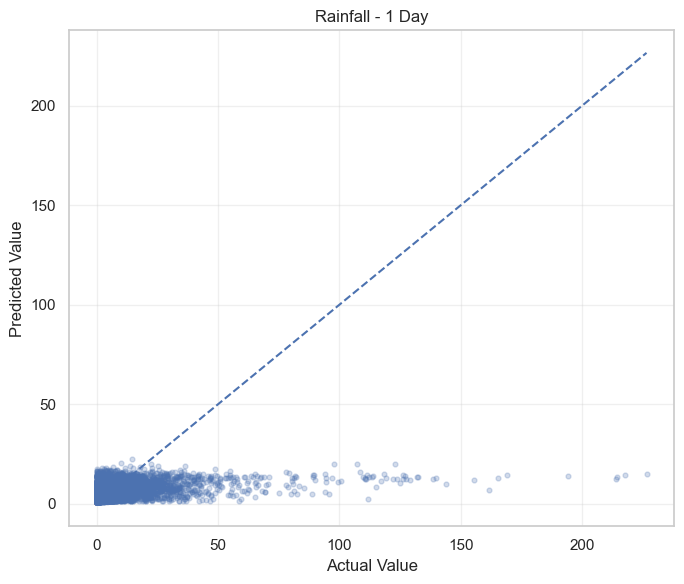

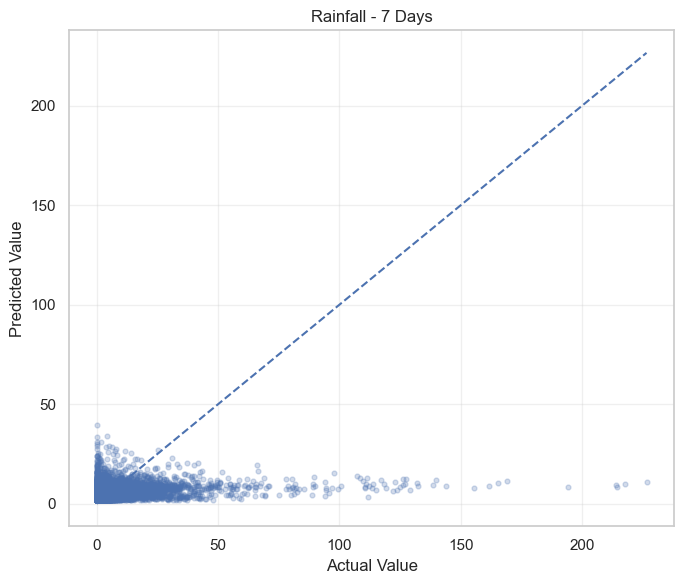

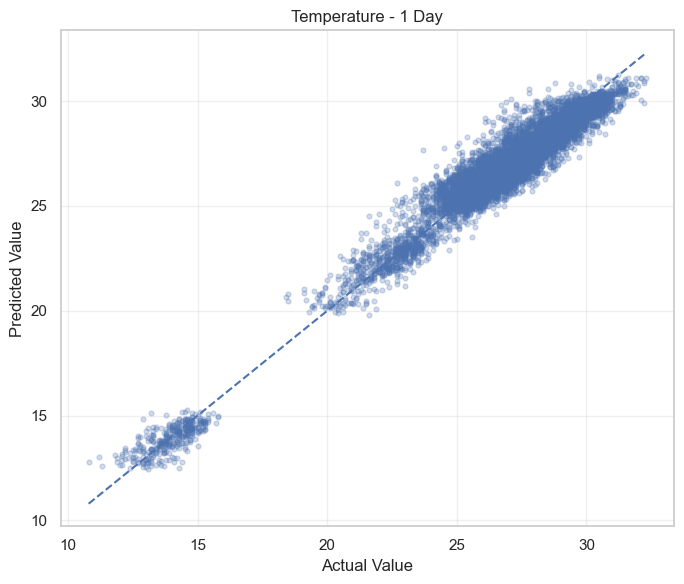

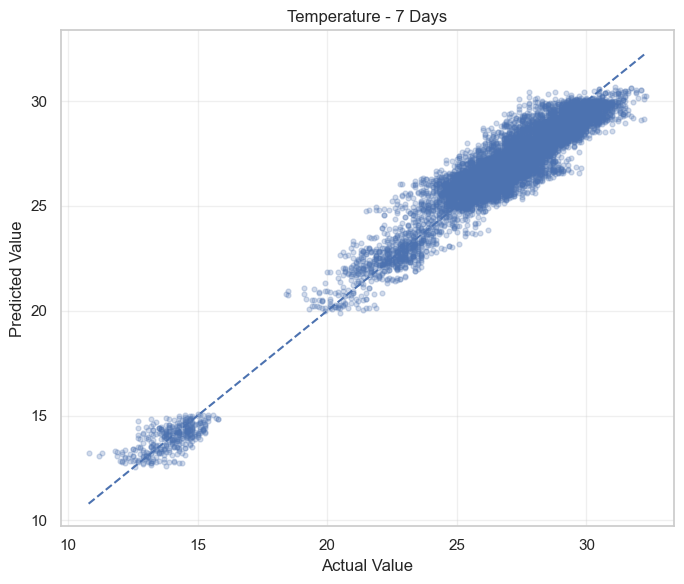

In [72]:
# Cell 62: Actual versus predicted scatter plots

import matplotlib.pyplot as plt

plot_titles = {
    ("precipitation_sum", 1): "Rainfall - 1 Day",
    ("precipitation_sum", 7): "Rainfall - 7 Days",
    ("temperature_2m_mean", 1): "Temperature - 1 Day",
    ("temperature_2m_mean", 7): "Temperature - 7 Days"
}

for task, diagnostics_df in forecast_diagnostics.items():

    target, horizon = task

    plt.figure(figsize=(7, 6))

    plt.scatter(
        diagnostics_df["actual"],
        diagnostics_df["predicted"],
        alpha=0.25,
        s=12
    )

    # Reference line: perfect predictions
    min_value = min(
        diagnostics_df["actual"].min(),
        diagnostics_df["predicted"].min()
    )

    max_value = max(
        diagnostics_df["actual"].max(),
        diagnostics_df["predicted"].max()
    )

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    plt.title(plot_titles[task])
    plt.xlabel("Actual Value")
    plt.ylabel("Predicted Value")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

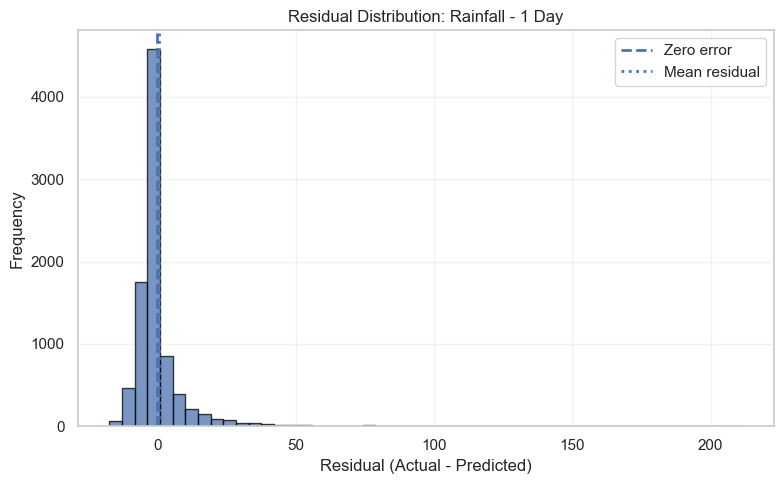

Rainfall - 1 Day | Mean residual: 0.6212


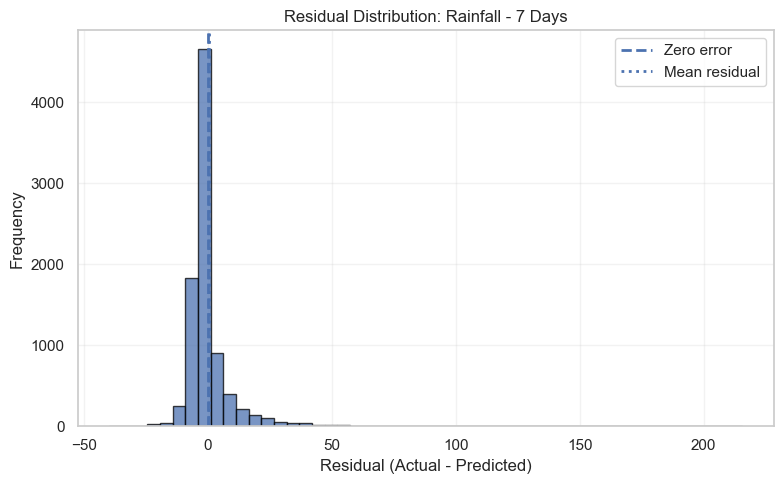

Rainfall - 7 Days | Mean residual: 0.5835


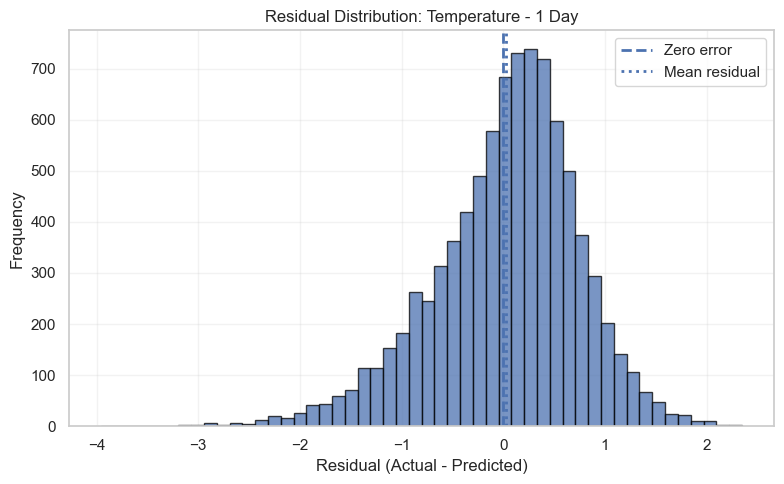

Temperature - 1 Day | Mean residual: 0.0267


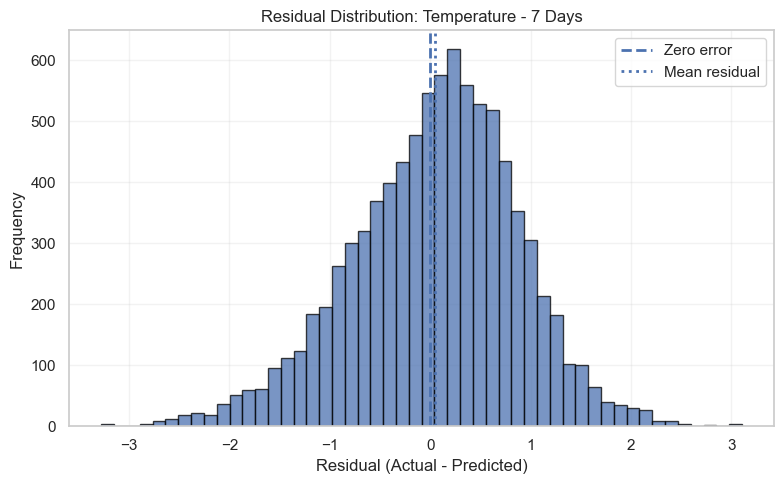

Temperature - 7 Days | Mean residual: 0.0426


In [73]:
# Cell 63: Residual distribution analysis

import matplotlib.pyplot as plt

plot_titles = {
    ("precipitation_sum", 1): "Rainfall - 1 Day",
    ("precipitation_sum", 7): "Rainfall - 7 Days",
    ("temperature_2m_mean", 1): "Temperature - 1 Day",
    ("temperature_2m_mean", 7): "Temperature - 7 Days"
}

for task, diagnostics_df in forecast_diagnostics.items():

    plt.figure(figsize=(8, 5))

    plt.hist(
        diagnostics_df["residual"],
        bins=50,
        alpha=0.75,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--",
        linewidth=2,
        label="Zero error"
    )

    plt.axvline(
        diagnostics_df["residual"].mean(),
        linestyle=":",
        linewidth=2,
        label="Mean residual"
    )

    plt.title(
        f"Residual Distribution: {plot_titles[task]}"
    )

    plt.xlabel("Residual (Actual - Predicted)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(
        f"{plot_titles[task]} | "
        f"Mean residual: "
        f"{diagnostics_df['residual'].mean():.4f}"
    )

In [74]:
# Cell 64: Calculate residual statistics

residual_statistics = []

for (target, horizon), diagnostics_df in forecast_diagnostics.items():

    residual = diagnostics_df["residual"]

    residual_statistics.append({
        "target": target,
        "horizon_days": horizon,

        "mean_residual": residual.mean(),
        "median_residual": residual.median(),

        "residual_std": residual.std(),

        "underprediction_count": (residual > 0).sum(),
        "overprediction_count": (residual < 0).sum(),
        "exact_prediction_count": (residual == 0).sum(),

        "underprediction_percent": (
            (residual > 0).mean() * 100
        ),

        "overprediction_percent": (
            (residual < 0).mean() * 100
        )
    })

residual_statistics_df = pd.DataFrame(
    residual_statistics
)

display(residual_statistics_df.round(4))

# Save residual statistics
residual_statistics_path = (
    WEATHER_FORECASTING_DIR
    / "weather_forecasting_residual_statistics.csv"
)

residual_statistics_df.to_csv(
    residual_statistics_path,
    index=False
)

print("\nResidual statistics saved:")
print(residual_statistics_path)

,target,horizon_days,mean_residual,median_residual,residual_std,underprediction_count,overprediction_count,exact_prediction_count,underprediction_percent,overprediction_percent
0,precipitation_sum,1,0.6212,-1.5763,12.5192,2383,6442,0,27.0028,72.9972
1,precipitation_sum,7,0.5835,-2.0973,13.0206,2398,6427,0,27.1728,72.8272
2,temperature_2m_mean,1,0.0267,0.1103,0.7225,5067,3758,0,57.4164,42.5836
3,temperature_2m_mean,7,0.0426,0.1092,0.8369,4910,3915,0,55.6374,44.3626



Residual statistics saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\weather_forecasting_residual_statistics.csv


In [75]:
# Cell 65: Rainfall prediction error by rainfall intensity

rainfall_categories = [
    "No rainfall",
    "Light rainfall",
    "Moderate rainfall",
    "Heavy rainfall",
    "Very heavy rainfall"
]

rainfall_bins = [-0.001, 0, 10, 25, 50, np.inf]

rainfall_error_results = []

for horizon in [1, 7]:

    diagnostics_df = forecast_diagnostics[
        ("precipitation_sum", horizon)
    ].copy()

    diagnostics_df["rainfall_category"] = pd.cut(
        diagnostics_df["actual"],
        bins=rainfall_bins,
        labels=rainfall_categories,
        include_lowest=True
    )

    grouped = diagnostics_df.groupby(
        "rainfall_category",
        observed=False
    )

    for category, group in grouped:

        if len(group) == 0:
            continue

        rainfall_error_results.append({
            "horizon_days": horizon,
            "rainfall_category": category,
            "record_count": len(group),
            "mean_actual_rainfall": group["actual"].mean(),
            "mean_predicted_rainfall": group["predicted"].mean(),
            "mae": group["absolute_error"].mean(),
            "mean_residual": group["residual"].mean()
        })

rainfall_intensity_comparison = pd.DataFrame(
    rainfall_error_results
)

display(rainfall_intensity_comparison.round(4))

# Save results
rainfall_intensity_path = (
    WEATHER_FORECASTING_DIR
    / "rainfall_error_by_intensity.csv"
)

rainfall_intensity_comparison.to_csv(
    rainfall_intensity_path,
    index=False
)

print("\nRainfall intensity analysis saved:")
print(rainfall_intensity_path)

,horizon_days,rainfall_category,record_count,mean_actual_rainfall,mean_predicted_rainfall,mae,mean_residual
0,1,No rainfall,1579,0.0000,3.0645,3.0645,-3.0645
1,1,Light rainfall,5852,2.6929,5.2186,3.2774,-2.5256
2,1,Moderate rainfall,948,15.6050,7.9574,7.9569,7.6475
3,1,Heavy rainfall,319,33.8408,9.0673,24.7734,24.7734
4,1,Very heavy rainfall,127,89.3378,11.0077,78.3301,78.3301
5,7,No rainfall,1579,0.0000,3.9070,3.9070,-3.9070
6,7,Light rainfall,5852,2.6929,5.3238,3.4193,-2.6308
7,7,Moderate rainfall,948,15.6050,7.0924,8.7903,8.5125
8,7,Heavy rainfall,319,33.8408,7.5412,26.3092,26.2996
9,7,Very heavy rainfall,127,89.3378,8.5904,80.7474,80.7474



Rainfall intensity analysis saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\rainfall_error_by_intensity.csv


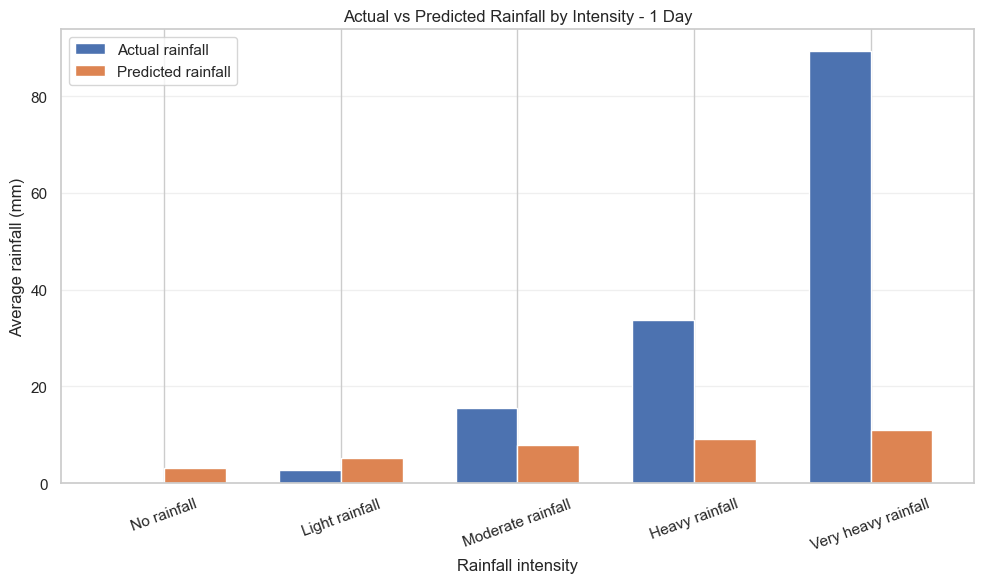

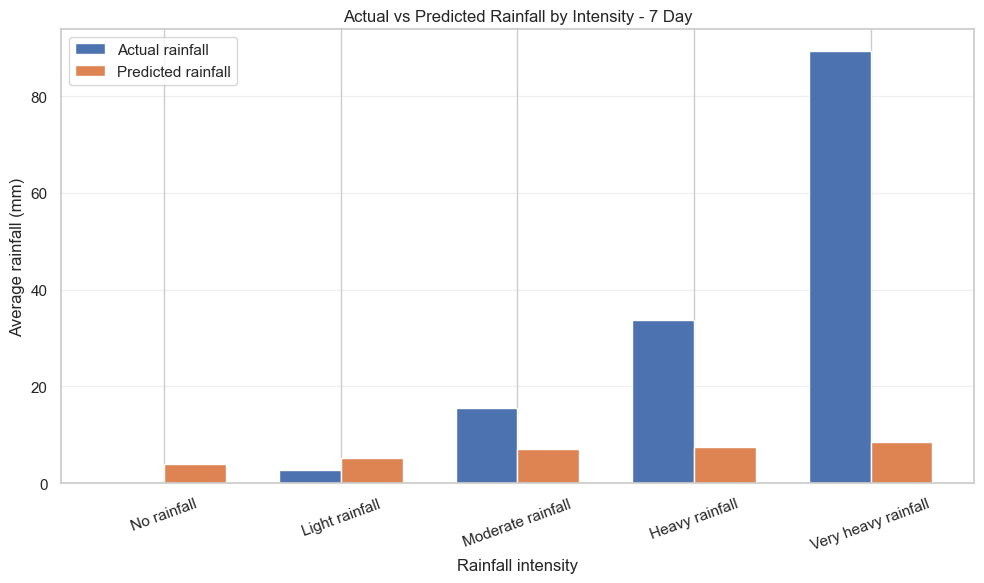

In [76]:
# Cell 66: Visualize rainfall prediction by intensity

import matplotlib.pyplot as plt
import numpy as np

for horizon in [1, 7]:

    plot_df = rainfall_intensity_comparison[
        rainfall_intensity_comparison["horizon_days"] == horizon
    ].copy()

    x = np.arange(len(plot_df))
    width = 0.35

    plt.figure(figsize=(10, 6))

    plt.bar(
        x - width / 2,
        plot_df["mean_actual_rainfall"],
        width,
        label="Actual rainfall"
    )

    plt.bar(
        x + width / 2,
        plot_df["mean_predicted_rainfall"],
        width,
        label="Predicted rainfall"
    )

    plt.xticks(
        x,
        plot_df["rainfall_category"],
        rotation=20
    )

    plt.xlabel("Rainfall intensity")
    plt.ylabel("Average rainfall (mm)")
    plt.title(
        f"Actual vs Predicted Rainfall by Intensity - {horizon} Day"
    )

    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [77]:
# Cell 67: Temperature prediction error by temperature range

temperature_categories = [
    "Below 20°C",
    "20–23°C",
    "23–26°C",
    "26–29°C",
    "Above 29°C"
]

temperature_bins = [-np.inf, 20, 23, 26, 29, np.inf]

temperature_error_results = []

for horizon in [1, 7]:

    diagnostics_df = forecast_diagnostics[
        ("temperature_2m_mean", horizon)
    ].copy()

    diagnostics_df["temperature_category"] = pd.cut(
        diagnostics_df["actual"],
        bins=temperature_bins,
        labels=temperature_categories,
        include_lowest=True
    )

    grouped = diagnostics_df.groupby(
        "temperature_category",
        observed=False
    )

    for category, group in grouped:

        if len(group) == 0:
            continue

        temperature_error_results.append({
            "horizon_days": horizon,
            "temperature_category": category,
            "record_count": len(group),
            "mean_actual_temperature": group["actual"].mean(),
            "mean_predicted_temperature": group["predicted"].mean(),
            "mae": group["absolute_error"].mean(),
            "mean_residual": group["residual"].mean()
        })

temperature_intensity_comparison = pd.DataFrame(
    temperature_error_results
)

display(temperature_intensity_comparison.round(4))

# Save results
temperature_intensity_path = (
    WEATHER_FORECASTING_DIR
    / "temperature_error_by_range.csv"
)

temperature_intensity_comparison.to_csv(
    temperature_intensity_path,
    index=False
)

print("\nTemperature range analysis saved:")
print(temperature_intensity_path)

,horizon_days,temperature_category,record_count,mean_actual_temperature,mean_predicted_temperature,mae,mean_residual
0,1,Below 20°C,380,14.3550,14.4006,0.5139,-0.0456
1,1,20–23°C,470,22.0183,22.2883,0.6029,-0.2700
2,1,23–26°C,2029,25.0997,25.4770,0.6397,-0.3774
3,1,26–29°C,4520,27.4317,27.3190,0.5245,0.1127
4,1,Above 29°C,1426,29.9307,29.4845,0.5563,0.4462
5,7,Below 20°C,380,14.3550,14.4114,0.5710,-0.0564
6,7,20–23°C,470,22.0183,22.4089,0.7121,-0.3906
7,7,23–26°C,2029,25.0997,25.5874,0.7288,-0.4877
8,7,26–29°C,4520,27.4317,27.2978,0.6042,0.1339
9,7,Above 29°C,1426,29.9307,29.2539,0.7529,0.6768



Temperature range analysis saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\temperature_error_by_range.csv


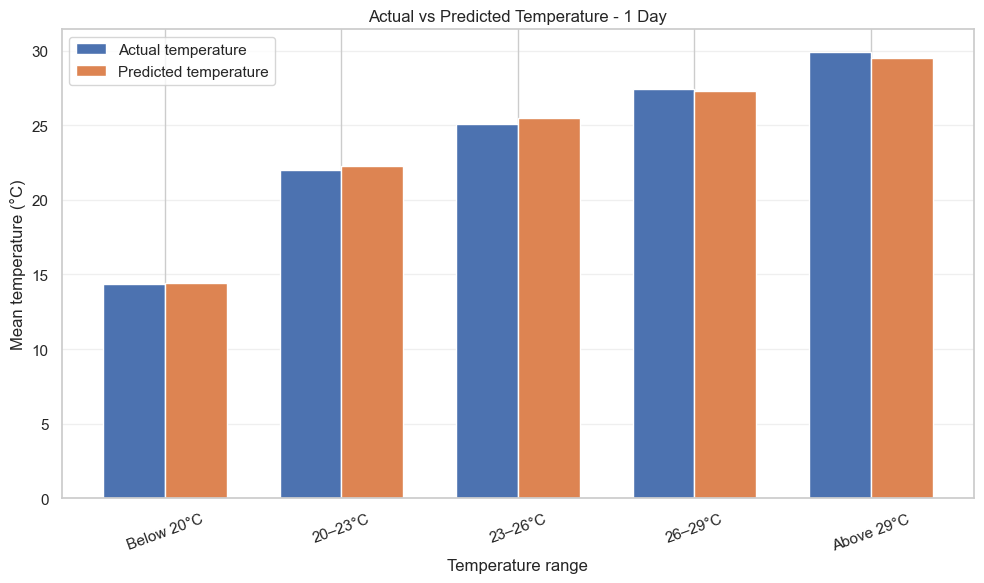

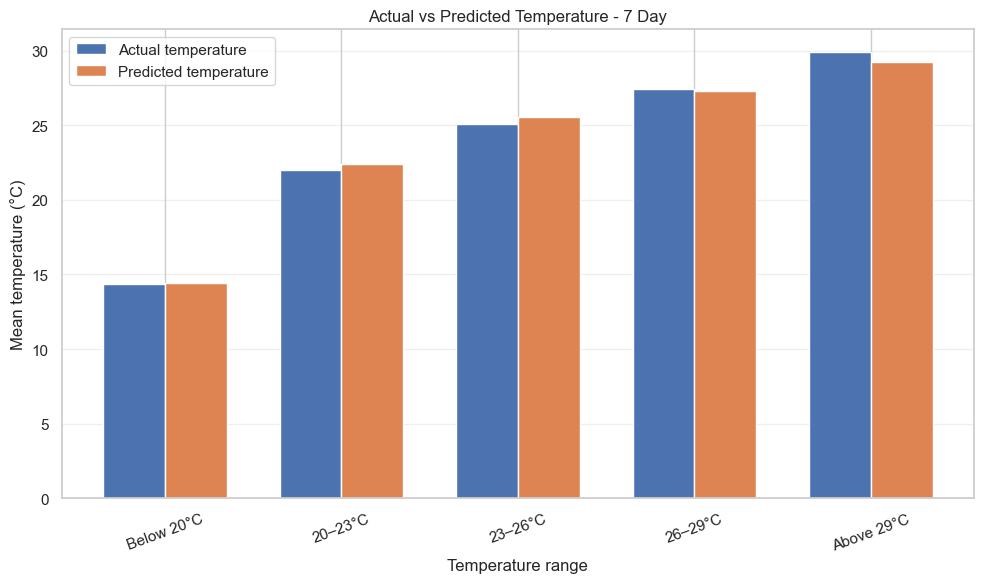

In [78]:
# Cell 68: Actual vs predicted temperature by range

import matplotlib.pyplot as plt
import numpy as np

for horizon in [1, 7]:

    plot_df = temperature_intensity_comparison[
        temperature_intensity_comparison["horizon_days"] == horizon
    ].copy()

    x = np.arange(len(plot_df))
    width = 0.35

    plt.figure(figsize=(10, 6))

    plt.bar(
        x - width / 2,
        plot_df["mean_actual_temperature"],
        width,
        label="Actual temperature"
    )

    plt.bar(
        x + width / 2,
        plot_df["mean_predicted_temperature"],
        width,
        label="Predicted temperature"
    )

    plt.xticks(
        x,
        plot_df["temperature_category"],
        rotation=20
    )

    plt.xlabel("Temperature range")
    plt.ylabel("Mean temperature (°C)")

    plt.title(
        f"Actual vs Predicted Temperature - {horizon} Day"
    )

    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [79]:
# Cell 69: District-level forecasting error analysis

district_error_results = []

for (target, horizon), diagnostics_df in forecast_diagnostics.items():

    grouped = diagnostics_df.groupby("district")

    for district, group in grouped:

        district_error_results.append({
            "target": target,
            "horizon_days": horizon,
            "district": district,
            "record_count": len(group),
            "mae": group["absolute_error"].mean(),
            "rmse": np.sqrt(
                np.mean(group["residual"] ** 2)
            ),
            "mean_residual": group["residual"].mean()
        })

district_error_comparison = pd.DataFrame(
    district_error_results
)

# Sort by target, horizon and MAE
district_error_comparison = (
    district_error_comparison
    .sort_values(
        ["target", "horizon_days", "mae"],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

display(district_error_comparison.round(4))

# Save results
district_error_path = (
    WEATHER_FORECASTING_DIR
    / "weather_forecasting_district_error_analysis.csv"
)

district_error_comparison.to_csv(
    district_error_path,
    index=False
)

print("\nDistrict-level error analysis saved:")
print(district_error_path)

print(
    "\nNumber of districts:",
    district_error_comparison["district"].nunique()
)

,target,horizon_days,district,record_count,mae,rmse,mean_residual
0,precipitation_sum,1,Kegalle,353,8.5741,18.8286,2.4080
1,precipitation_sum,1,Ratnapura,353,7.7210,14.8223,1.9428
2,precipitation_sum,1,Nuwara Eliya,353,7.0182,13.0866,0.9325
3,precipitation_sum,1,Gampaha,353,6.7337,16.8502,1.4792
4,precipitation_sum,1,Badulla,353,6.6862,12.2609,0.5232
5,precipitation_sum,1,Kalutara,353,6.5098,11.7912,0.5903
6,precipitation_sum,1,Matara,353,6.4670,11.8645,0.7353
7,precipitation_sum,1,Colombo,353,6.4209,12.9718,0.9552
8,precipitation_sum,1,Galle,353,6.2445,11.8781,0.7888
9,precipitation_sum,1,Kandy,353,6.0667,14.7157,0.4473



District-level error analysis saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\weather_forecasting_district_error_analysis.csv

Number of districts: 25


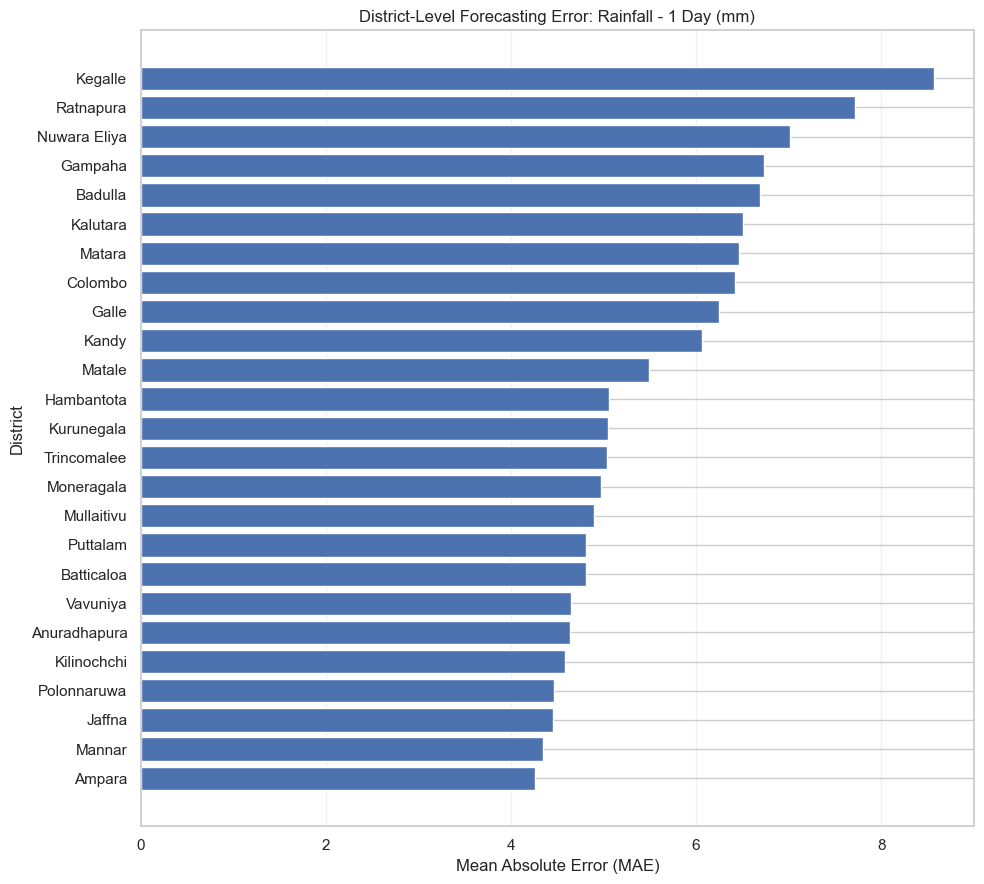

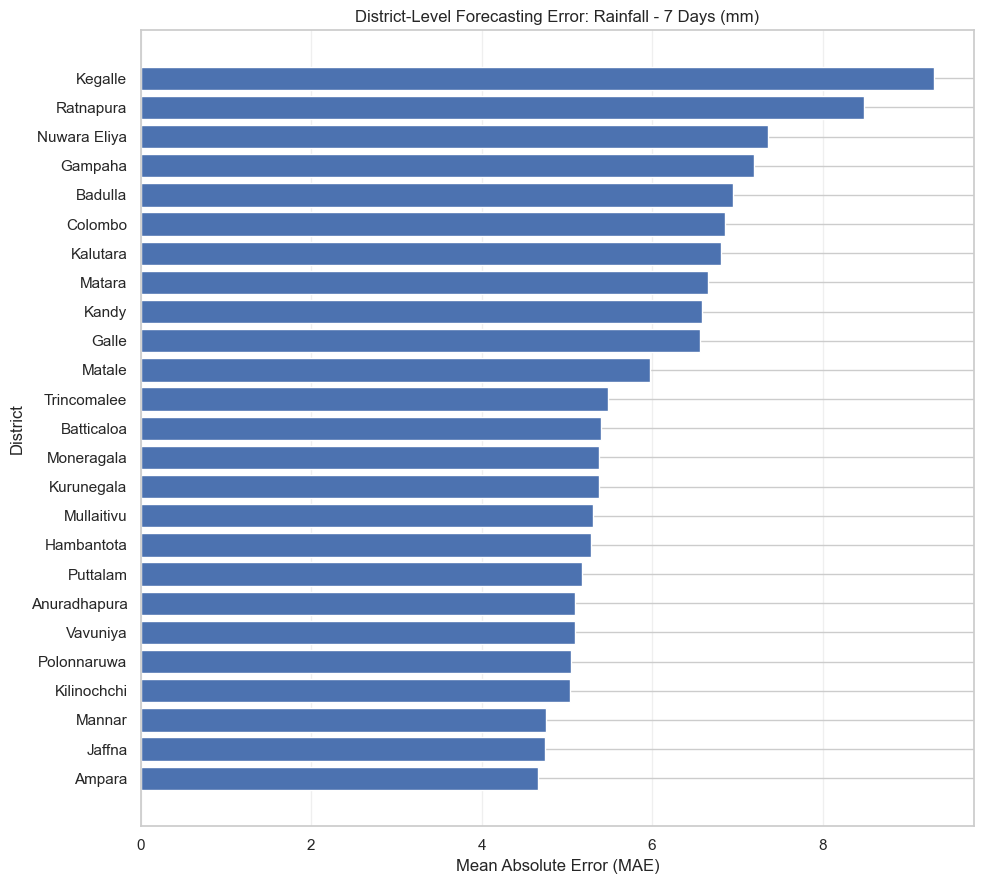

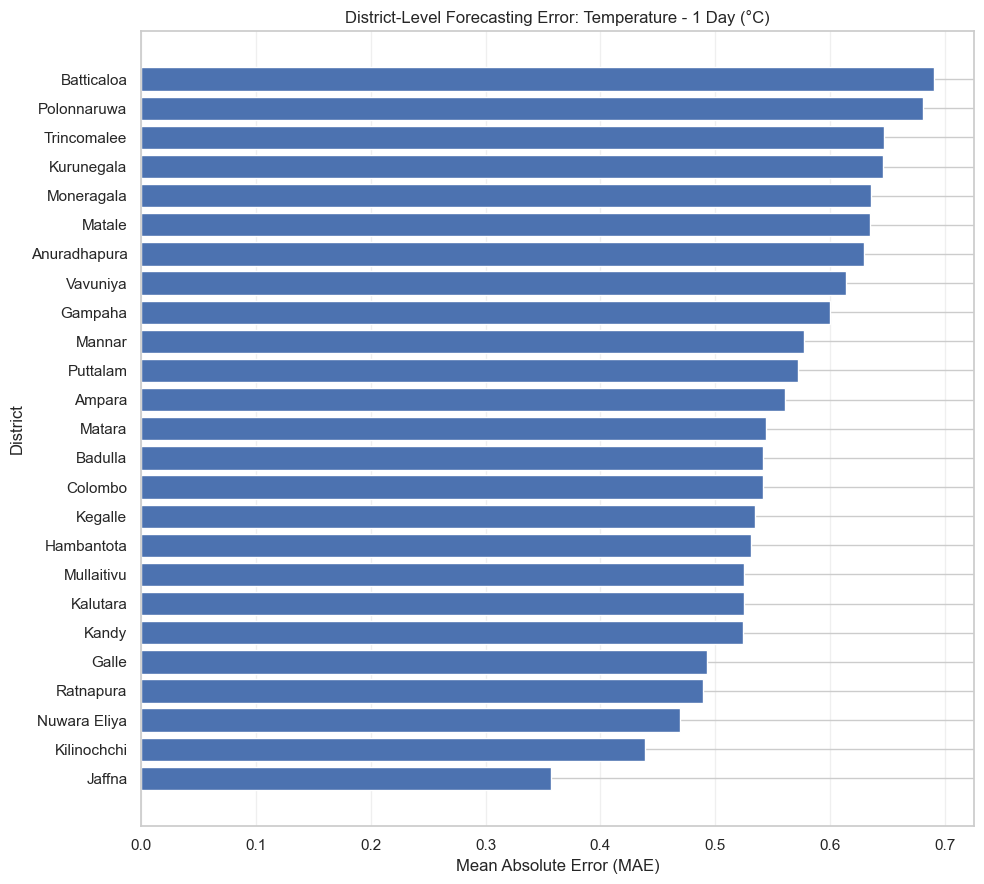

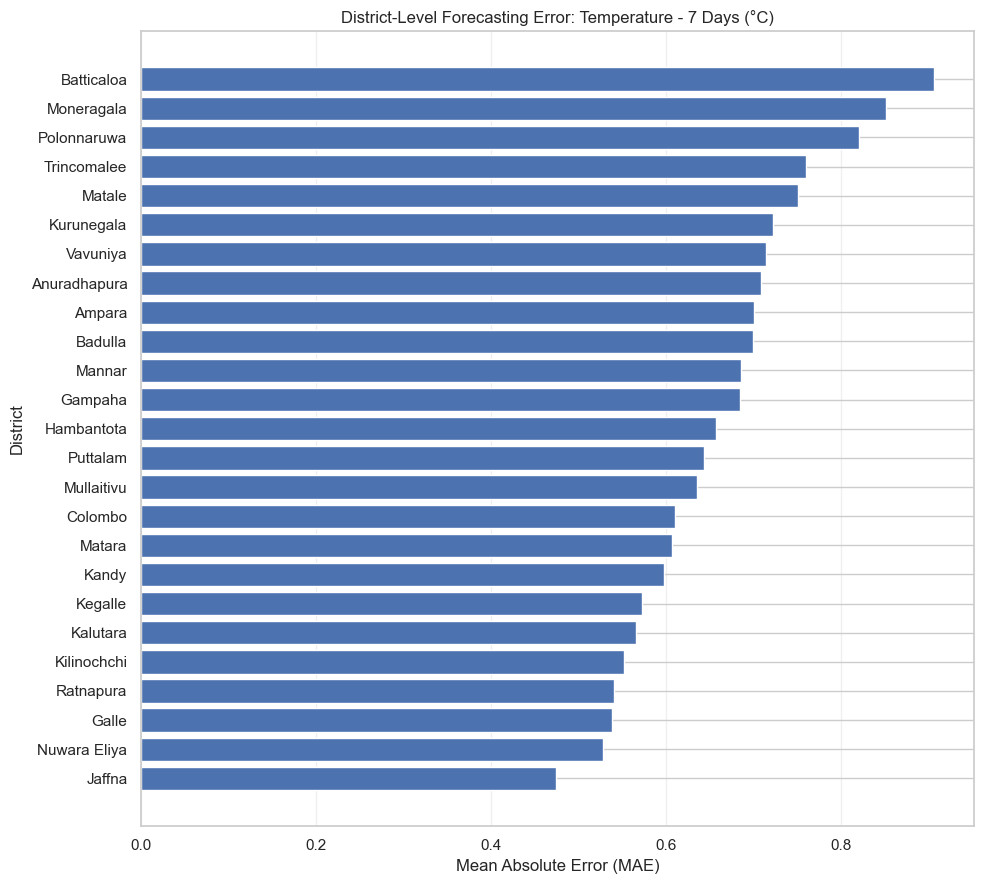

In [80]:
# Cell 70: Visualize district-level forecasting MAE

import matplotlib.pyplot as plt

plot_configurations = [
    ("precipitation_sum", 1, "Rainfall - 1 Day (mm)"),
    ("precipitation_sum", 7, "Rainfall - 7 Days (mm)"),
    ("temperature_2m_mean", 1, "Temperature - 1 Day (°C)"),
    ("temperature_2m_mean", 7, "Temperature - 7 Days (°C)")
]

for target, horizon, title in plot_configurations:

    plot_df = district_error_comparison[
        (district_error_comparison["target"] == target) &
        (district_error_comparison["horizon_days"] == horizon)
    ].sort_values("mae", ascending=True)

    plt.figure(figsize=(10, 9))

    plt.barh(
        plot_df["district"],
        plot_df["mae"]
    )

    plt.xlabel("Mean Absolute Error (MAE)")
    plt.ylabel("District")
    plt.title(f"District-Level Forecasting Error: {title}")

    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [81]:
# Cell 71: Check SHAP installation

try:
    import shap

    print("SHAP version:", shap.__version__)
    print("SHAP is installed successfully.")

except ImportError:
    print("SHAP is not installed.")
    print("Run the following command in VS Code terminal:")
    print("python -m pip install shap")

SHAP version: 0.51.0
SHAP is installed successfully.


In [82]:
# Cell 72: Prepare 1-day temperature data for SHAP

import shap
import numpy as np
import pandas as pd

# Select the 1-day temperature model
target = "temperature_2m_mean"
horizon = 1

task_key = (target, horizon)

# Retrieve fitted model and preprocessor
temperature_model = final_models[task_key]["model"]
temperature_preprocessor = final_models[task_key]["preprocessor"]

# Retrieve test dataset
temperature_test_df = final_datasets[task_key]["test"].copy()

# Select a reproducible sample of 200 observations
shap_sample = temperature_test_df.sample(
    n=min(200, len(temperature_test_df)),
    random_state=42
)

# Extract model features
X_shap = shap_sample[MODEL_FEATURE_COLUMNS]

# Apply fitted preprocessing
X_shap_processed = temperature_preprocessor.transform(X_shap)

X_shap_processed = np.asarray(
    X_shap_processed,
    dtype=np.float32
)

# Get transformed feature names
shap_feature_names = (
    temperature_preprocessor.get_feature_names_out()
)

# Create DataFrame for SHAP
X_shap_processed_df = pd.DataFrame(
    X_shap_processed,
    columns=shap_feature_names
)

print("SHAP sample shape:", X_shap_processed_df.shape)
print("Number of features:", len(shap_feature_names))
print("\nFirst 10 transformed features:")
print(list(shap_feature_names[:10]))

SHAP sample shape: (200, 115)
Number of features: 115

First 10 transformed features:
['district__district_Ampara', 'district__district_Anuradhapura', 'district__district_Badulla', 'district__district_Batticaloa', 'district__district_Colombo', 'district__district_Galle', 'district__district_Gampaha', 'district__district_Hambantota', 'district__district_Jaffna', 'district__district_Kalutara']


In [83]:
# Cell 73: Calculate SHAP values for 1-day temperature model

# Create TreeExplainer
temperature_explainer = shap.TreeExplainer(
    temperature_model
)

# Calculate SHAP values
temperature_shap_values = temperature_explainer.shap_values(
    X_shap_processed_df
)

# Check SHAP output
print("SHAP calculation completed.")

print("SHAP values shape:",
      np.asarray(temperature_shap_values).shape)

print("Input feature shape:",
      X_shap_processed_df.shape)

# Calculate mean absolute SHAP importance
temperature_shap_importance = pd.DataFrame({
    "feature": shap_feature_names,
    "mean_absolute_shap": np.abs(
        temperature_shap_values
    ).mean(axis=0)
})

temperature_shap_importance = (
    temperature_shap_importance
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

display(temperature_shap_importance.head(20))

SHAP calculation completed.
SHAP values shape: (200, 115)
Input feature shape: (200, 115)


,feature,mean_absolute_shap
0,numerical__temperature_2m_mean_lag_1,0.275915
1,numerical__temperature_2m_mean_rolling_mean_7,0.263711
2,numerical__temperature_2m_mean_rolling_mean_14,0.259111
3,numerical__temperature_2m_mean_lag_2,0.157890
4,numerical__temperature_2m_mean_lag_3,0.120176
5,numerical__temperature_2m_min_lag_2,0.102599
6,numerical__temperature_2m_mean_lag_28,0.076423
7,numerical__temperature_2m_mean_rolling_mean_30,0.074253
8,numerical__temperature_2m_mean_lag_14,0.069064
9,numerical__temperature_2m_max_lag_14,0.066390


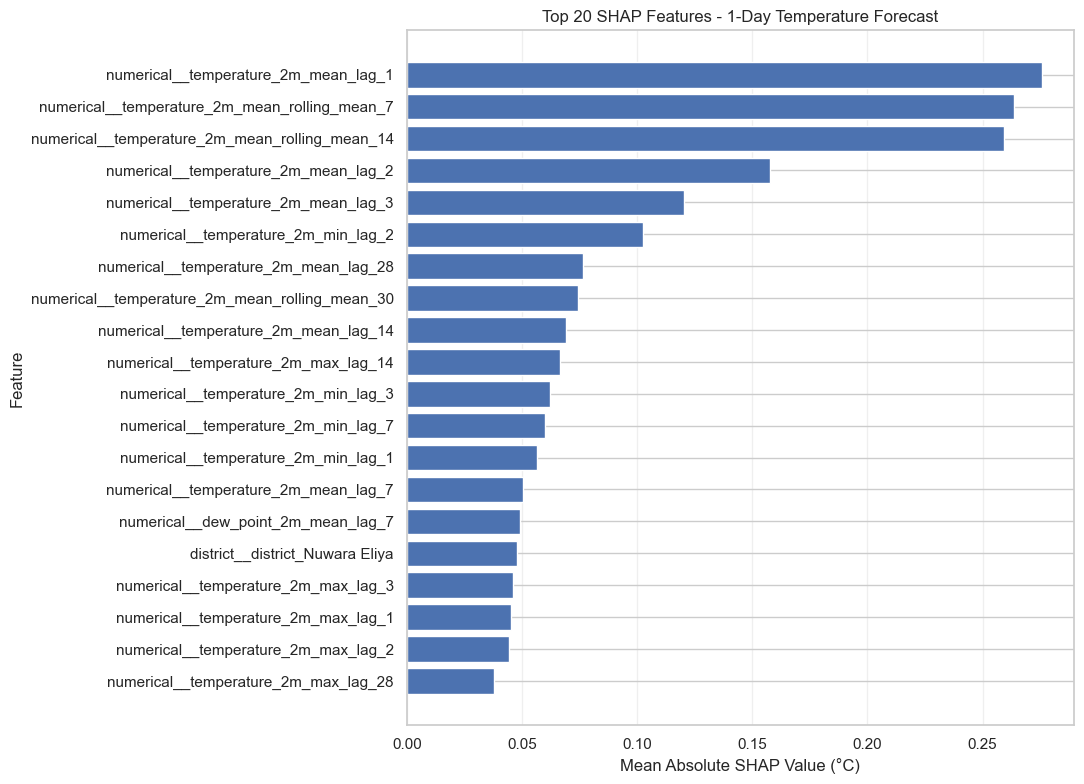

In [84]:
# Cell 74: Plot SHAP feature importance

import matplotlib.pyplot as plt

top_features = (
    temperature_shap_importance
    .head(20)
    .sort_values("mean_absolute_shap", ascending=True)
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["feature"],
    top_features["mean_absolute_shap"]
)

plt.xlabel("Mean Absolute SHAP Value (°C)")
plt.ylabel("Feature")

plt.title(
    "Top 20 SHAP Features - 1-Day Temperature Forecast"
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

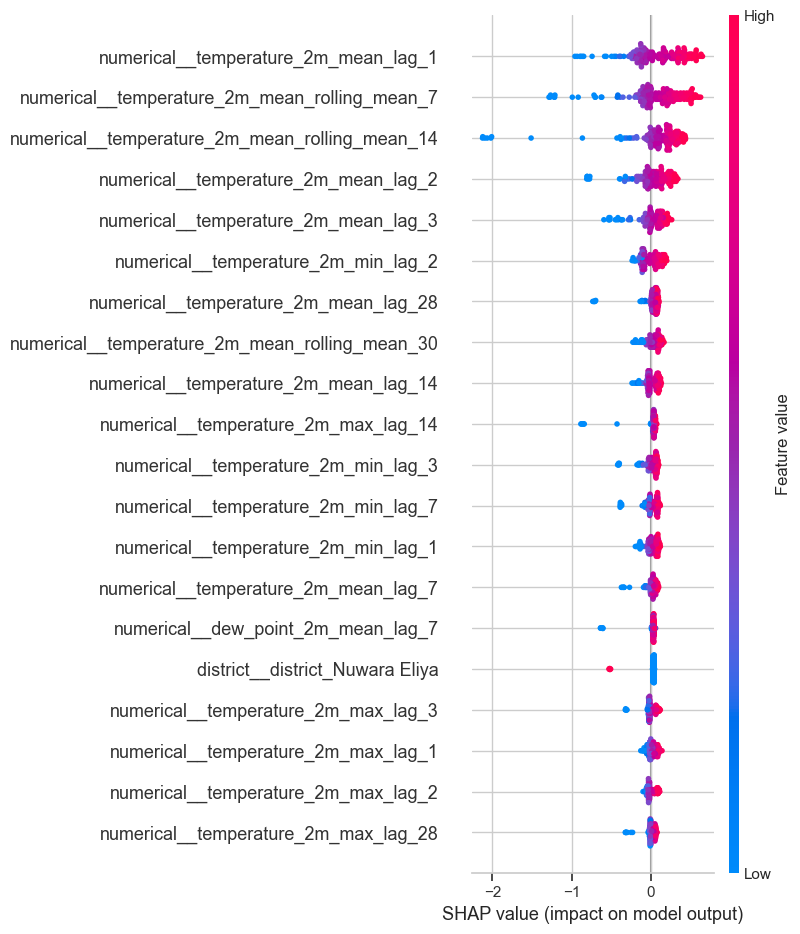

In [85]:
# Cell 75: SHAP beeswarm plot for 1-day temperature

shap.summary_plot(
    temperature_shap_values,
    X_shap_processed_df,
    max_display=20,
    show=True
)

In [86]:
# Cell 76: Prepare 7-day temperature data for SHAP

target = "temperature_2m_mean"
horizon = 7

task_key = (target, horizon)

# Retrieve fitted model and preprocessor
temperature_7day_model = final_models[task_key]["model"]

temperature_7day_preprocessor = (
    final_models[task_key]["preprocessor"]
)

# Retrieve test dataset
temperature_7day_test_df = (
    final_datasets[task_key]["test"].copy()
)

# Select a reproducible sample
shap_sample_7day = temperature_7day_test_df.sample(
    n=min(200, len(temperature_7day_test_df)),
    random_state=42
)

# Select model features
X_shap_7day = shap_sample_7day[MODEL_FEATURE_COLUMNS]

# Apply fitted preprocessing
X_shap_7day_processed = (
    temperature_7day_preprocessor.transform(X_shap_7day)
)

X_shap_7day_processed = np.asarray(
    X_shap_7day_processed,
    dtype=np.float32
)

# Get transformed feature names
shap_feature_names_7day = (
    temperature_7day_preprocessor.get_feature_names_out()
)

X_shap_7day_processed_df = pd.DataFrame(
    X_shap_7day_processed,
    columns=shap_feature_names_7day
)

print("7-day SHAP sample shape:",
      X_shap_7day_processed_df.shape)

print("Number of features:",
      len(shap_feature_names_7day))

print("\n7-day temperature SHAP data prepared.")

7-day SHAP sample shape: (200, 115)
Number of features: 115

7-day temperature SHAP data prepared.


In [87]:
# Cell 77: Calculate SHAP values for 7-day temperature model

temperature_7day_explainer = shap.TreeExplainer(
    temperature_7day_model
)

temperature_7day_shap_values = (
    temperature_7day_explainer.shap_values(
        X_shap_7day_processed_df
    )
)

print("7-day SHAP calculation completed.")

print(
    "SHAP values shape:",
    np.asarray(temperature_7day_shap_values).shape
)

# Calculate mean absolute SHAP importance
temperature_7day_shap_importance = pd.DataFrame({
    "feature": shap_feature_names_7day,
    "mean_absolute_shap": np.abs(
        temperature_7day_shap_values
    ).mean(axis=0)
})

temperature_7day_shap_importance = (
    temperature_7day_shap_importance
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

display(temperature_7day_shap_importance.head(20))

7-day SHAP calculation completed.
SHAP values shape: (200, 115)


,feature,mean_absolute_shap
0,numerical__temperature_2m_mean_rolling_mean_14,0.275543
1,numerical__temperature_2m_mean_rolling_mean_7,0.269274
2,numerical__temperature_2m_mean_rolling_mean_30,0.211381
3,numerical__temperature_2m_mean_lag_2,0.141905
4,numerical__temperature_2m_mean_lag_7,0.110068
5,numerical__temperature_2m_mean_lag_1,0.097041
6,numerical__temperature_2m_mean_lag_3,0.091330
7,numerical__temperature_2m_mean_lag_14,0.083019
8,numerical__temperature_2m_min_lag_3,0.071499
9,district__district_Nuwara Eliya,0.069994


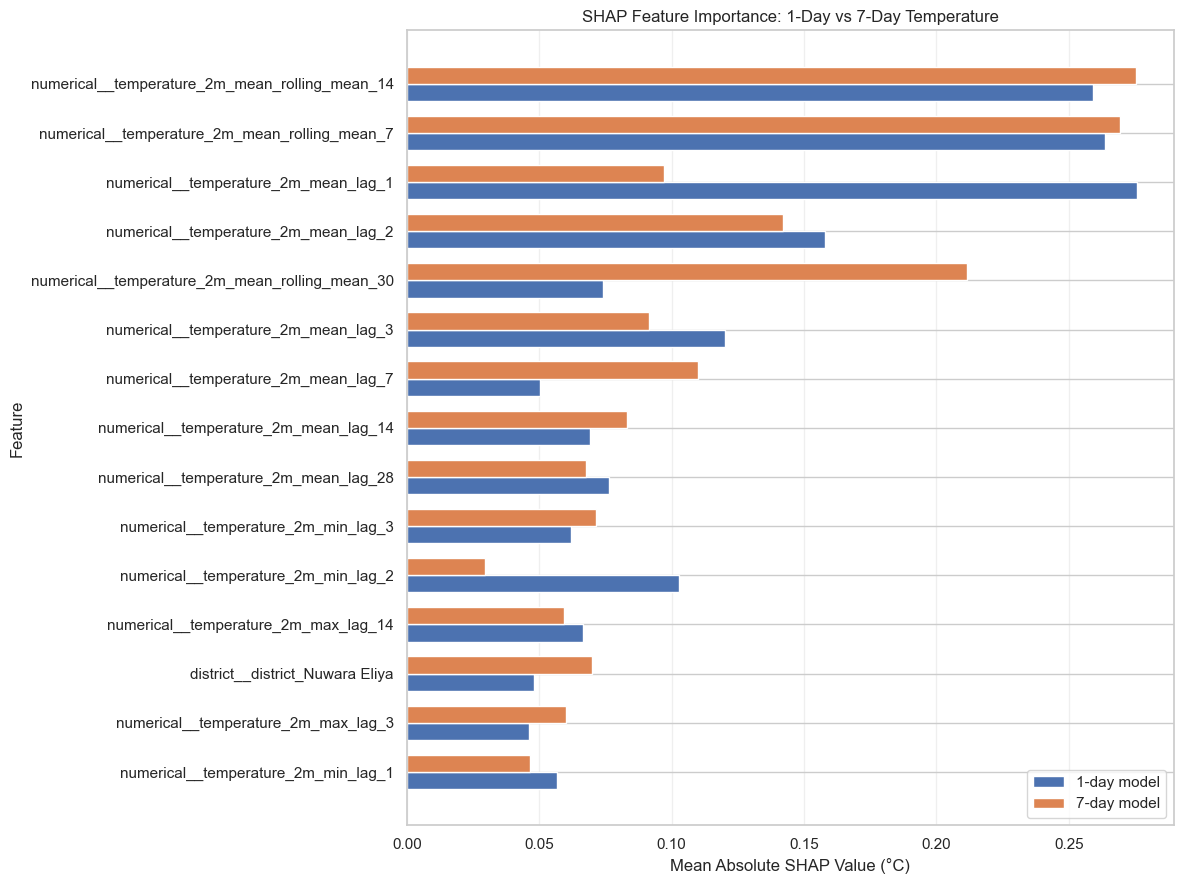

Temperature SHAP comparison saved.


In [88]:
# Cell 78: Compare temperature SHAP importance between horizons

# Combine the two importance tables
temperature_shap_comparison = pd.merge(
    temperature_shap_importance[
        ["feature", "mean_absolute_shap"]
    ].rename(columns={
        "mean_absolute_shap": "shap_1day"
    }),

    temperature_7day_shap_importance[
        ["feature", "mean_absolute_shap"]
    ].rename(columns={
        "mean_absolute_shap": "shap_7day"
    }),

    on="feature",
    how="outer"
).fillna(0)

# Select the top 15 features by combined importance
temperature_shap_comparison["combined_importance"] = (
    temperature_shap_comparison["shap_1day"]
    + temperature_shap_comparison["shap_7day"]
)

top_comparison_features = (
    temperature_shap_comparison
    .nlargest(15, "combined_importance")
    .sort_values("combined_importance")
)

# Plot comparison
y = np.arange(len(top_comparison_features))
height = 0.35

plt.figure(figsize=(12, 9))

plt.barh(
    y - height / 2,
    top_comparison_features["shap_1day"],
    height,
    label="1-day model"
)

plt.barh(
    y + height / 2,
    top_comparison_features["shap_7day"],
    height,
    label="7-day model"
)

plt.yticks(
    y,
    top_comparison_features["feature"]
)

plt.xlabel("Mean Absolute SHAP Value (°C)")
plt.ylabel("Feature")

plt.title(
    "SHAP Feature Importance: 1-Day vs 7-Day Temperature"
)

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Save comparison
temperature_shap_comparison.to_csv(
    WEATHER_FORECASTING_DIR
    / "temperature_shap_horizon_comparison.csv",
    index=False
)

print("Temperature SHAP comparison saved.")

In [89]:
# Cell 79: Prepare 1-day rainfall data for SHAP

target = "precipitation_sum"
horizon = 1

task_key = (target, horizon)

# Retrieve the fitted model and preprocessor
rainfall_1day_model = final_models[task_key]["model"]

rainfall_1day_preprocessor = (
    final_models[task_key]["preprocessor"]
)

# Retrieve test dataset
rainfall_1day_test_df = (
    final_datasets[task_key]["test"].copy()
)

# Select a reproducible sample of 200 observations
rainfall_shap_sample = rainfall_1day_test_df.sample(
    n=min(200, len(rainfall_1day_test_df)),
    random_state=42
)

# Select model features
X_rainfall_shap = rainfall_shap_sample[
    MODEL_FEATURE_COLUMNS
]

# Apply the fitted preprocessor
X_rainfall_shap_processed = (
    rainfall_1day_preprocessor.transform(
        X_rainfall_shap
    )
)

X_rainfall_shap_processed = np.asarray(
    X_rainfall_shap_processed,
    dtype=np.float32
)

# Get transformed feature names
rainfall_shap_feature_names = (
    rainfall_1day_preprocessor.get_feature_names_out()
)

# Create DataFrame for SHAP
X_rainfall_shap_processed_df = pd.DataFrame(
    X_rainfall_shap_processed,
    columns=rainfall_shap_feature_names
)

print(
    "1-day rainfall SHAP sample shape:",
    X_rainfall_shap_processed_df.shape
)

print(
    "Number of features:",
    len(rainfall_shap_feature_names)
)

print("\n1-day rainfall SHAP data prepared.")

1-day rainfall SHAP sample shape: (200, 115)
Number of features: 115

1-day rainfall SHAP data prepared.


In [90]:
# Cell 80: Calculate SHAP values for 1-day rainfall model

rainfall_1day_explainer = shap.TreeExplainer(
    rainfall_1day_model
)

rainfall_1day_shap_values = (
    rainfall_1day_explainer.shap_values(
        X_rainfall_shap_processed_df
    )
)

print("1-day rainfall SHAP calculation completed.")

print(
    "SHAP values shape:",
    np.asarray(rainfall_1day_shap_values).shape
)

# Calculate mean absolute SHAP importance
rainfall_1day_shap_importance = pd.DataFrame({
    "feature": rainfall_shap_feature_names,
    "mean_absolute_shap": np.abs(
        rainfall_1day_shap_values
    ).mean(axis=0)
})

rainfall_1day_shap_importance = (
    rainfall_1day_shap_importance
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

display(rainfall_1day_shap_importance.head(20))

1-day rainfall SHAP calculation completed.
SHAP values shape: (200, 115)


,feature,mean_absolute_shap
0,numerical__precipitation_sum_lag_1,1.362261
1,numerical__relative_humidity_2m_mean_lag_1,0.889128
2,numerical__precipitation_sum_rolling_mean_30,0.426241
3,numerical__precipitation_sum_rolling_mean_7,0.377035
4,numerical__target_month,0.348017
5,numerical__et0_fao_evapotranspiration_lag_1,0.308438
6,numerical__precipitation_sum_lag_3,0.221220
7,numerical__origin_dayofyear_sin,0.209949
8,numerical__wind_speed_10m_mean_lag_1,0.173014
9,numerical__target_dayofyear_sin,0.141896


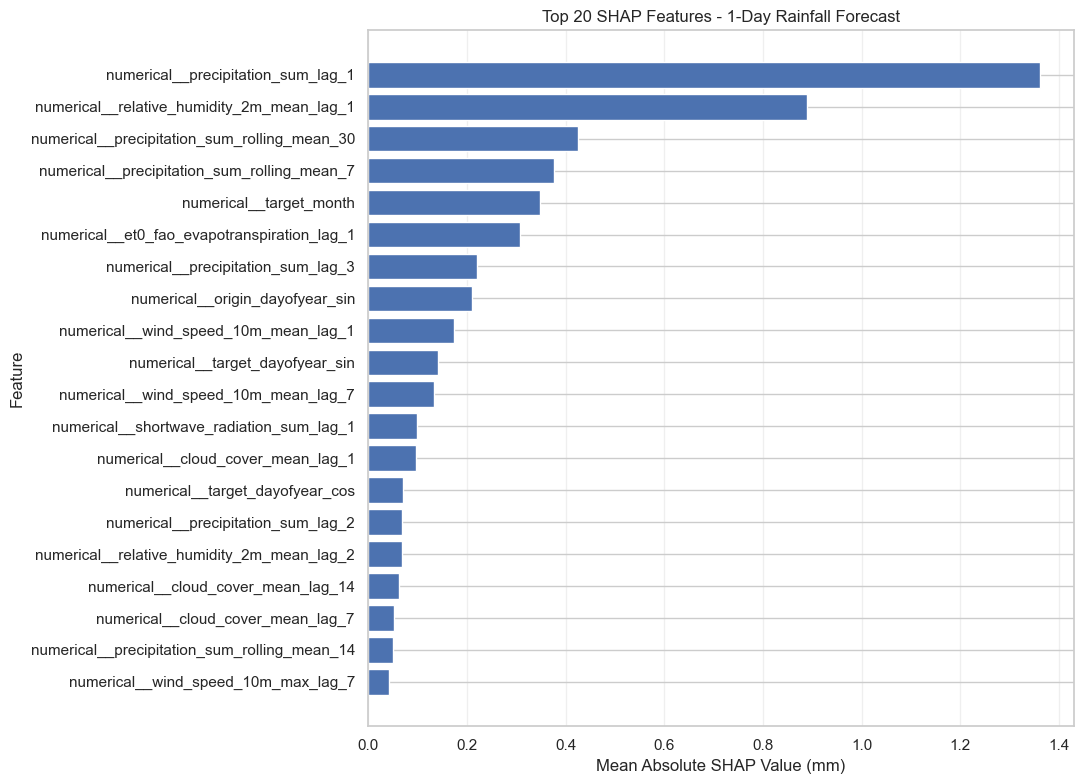

In [91]:
# Cell 81: Plot 1-day rainfall SHAP feature importance

top_rainfall_features = (
    rainfall_1day_shap_importance
    .head(20)
    .sort_values("mean_absolute_shap", ascending=True)
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_rainfall_features["feature"],
    top_rainfall_features["mean_absolute_shap"]
)

plt.xlabel("Mean Absolute SHAP Value (mm)")
plt.ylabel("Feature")

plt.title(
    "Top 20 SHAP Features - 1-Day Rainfall Forecast"
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [92]:
# Cell 82: Prepare 7-day rainfall data for SHAP

target = "precipitation_sum"
horizon = 7

task_key = (target, horizon)

# Retrieve fitted model and preprocessor
rainfall_7day_model = final_models[task_key]["model"]

rainfall_7day_preprocessor = (
    final_models[task_key]["preprocessor"]
)

# Retrieve test dataset
rainfall_7day_test_df = (
    final_datasets[task_key]["test"].copy()
)

# Select reproducible sample of 200 observations
rainfall_7day_shap_sample = (
    rainfall_7day_test_df.sample(
        n=min(200, len(rainfall_7day_test_df)),
        random_state=42
    )
)

# Select model features
X_rainfall_7day_shap = (
    rainfall_7day_shap_sample[MODEL_FEATURE_COLUMNS]
)

# Apply fitted preprocessing
X_rainfall_7day_processed = (
    rainfall_7day_preprocessor.transform(
        X_rainfall_7day_shap
    )
)

X_rainfall_7day_processed = np.asarray(
    X_rainfall_7day_processed,
    dtype=np.float32
)

# Get transformed feature names
rainfall_7day_shap_feature_names = (
    rainfall_7day_preprocessor.get_feature_names_out()
)

# Create DataFrame
X_rainfall_7day_processed_df = pd.DataFrame(
    X_rainfall_7day_processed,
    columns=rainfall_7day_shap_feature_names
)

print(
    "7-day rainfall SHAP sample shape:",
    X_rainfall_7day_processed_df.shape
)

print(
    "Number of features:",
    len(rainfall_7day_shap_feature_names)
)

print("\n7-day rainfall SHAP data prepared.")

7-day rainfall SHAP sample shape: (200, 115)
Number of features: 115

7-day rainfall SHAP data prepared.


In [93]:
# Cell 83: Calculate SHAP values for 7-day rainfall model

rainfall_7day_explainer = shap.TreeExplainer(
    rainfall_7day_model
)

rainfall_7day_shap_values = (
    rainfall_7day_explainer.shap_values(
        X_rainfall_7day_processed_df
    )
)

print("7-day rainfall SHAP calculation completed.")

print(
    "SHAP values shape:",
    np.asarray(rainfall_7day_shap_values).shape
)

# Calculate mean absolute SHAP importance
rainfall_7day_shap_importance = pd.DataFrame({
    "feature": rainfall_7day_shap_feature_names,
    "mean_absolute_shap": np.abs(
        rainfall_7day_shap_values
    ).mean(axis=0)
})

rainfall_7day_shap_importance = (
    rainfall_7day_shap_importance
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

display(rainfall_7day_shap_importance.head(20))

7-day rainfall SHAP calculation completed.
SHAP values shape: (200, 115)


,feature,mean_absolute_shap
0,numerical__target_month,0.745531
1,numerical__origin_dayofyear_sin,0.599474
2,numerical__precipitation_sum_rolling_mean_30,0.538751
3,numerical__wind_speed_10m_mean_lag_1,0.471989
4,numerical__precipitation_sum_rolling_mean_14,0.374323
5,numerical__relative_humidity_2m_mean_lag_1,0.364843
6,numerical__precipitation_sum_lag_2,0.336892
7,numerical__precipitation_sum_lag_28,0.151678
8,numerical__origin_dayofyear_cos,0.143319
9,numerical__precipitation_sum_lag_1,0.140439


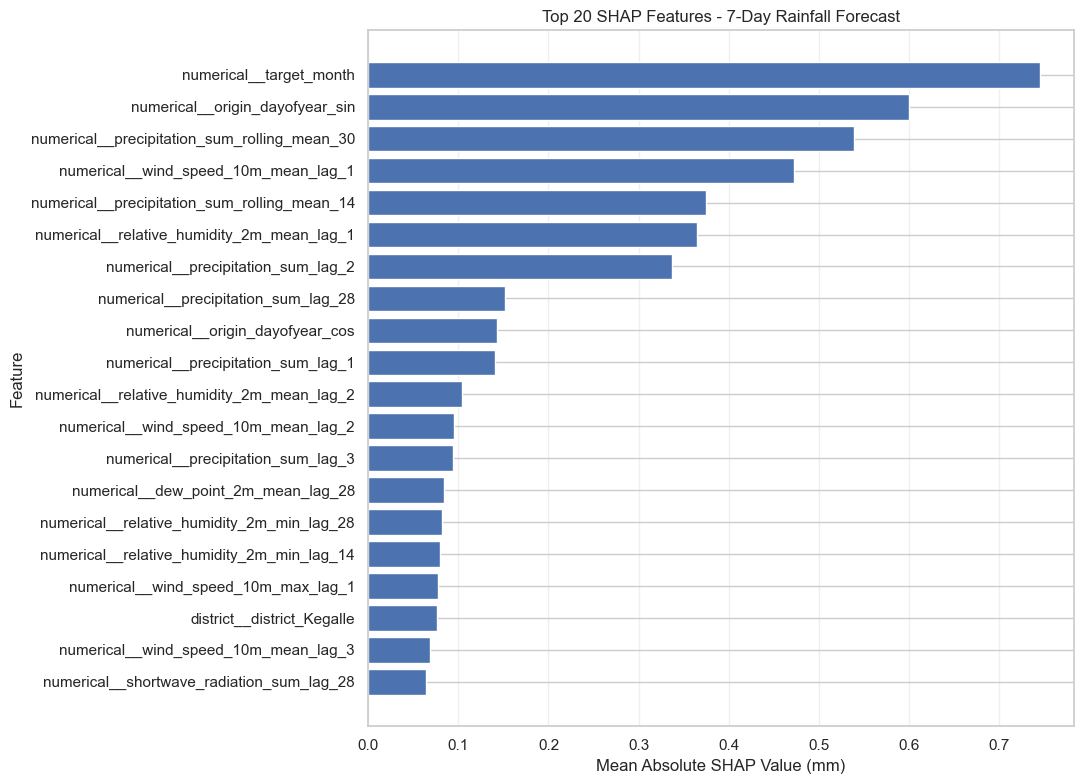

In [94]:
# Cell 84: Plot 7-day rainfall SHAP feature importance

top_rainfall_7day_features = (
    rainfall_7day_shap_importance
    .head(20)
    .sort_values(
        "mean_absolute_shap",
        ascending=True
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_rainfall_7day_features["feature"],
    top_rainfall_7day_features["mean_absolute_shap"]
)

plt.xlabel("Mean Absolute SHAP Value (mm)")
plt.ylabel("Feature")

plt.title(
    "Top 20 SHAP Features - 7-Day Rainfall Forecast"
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

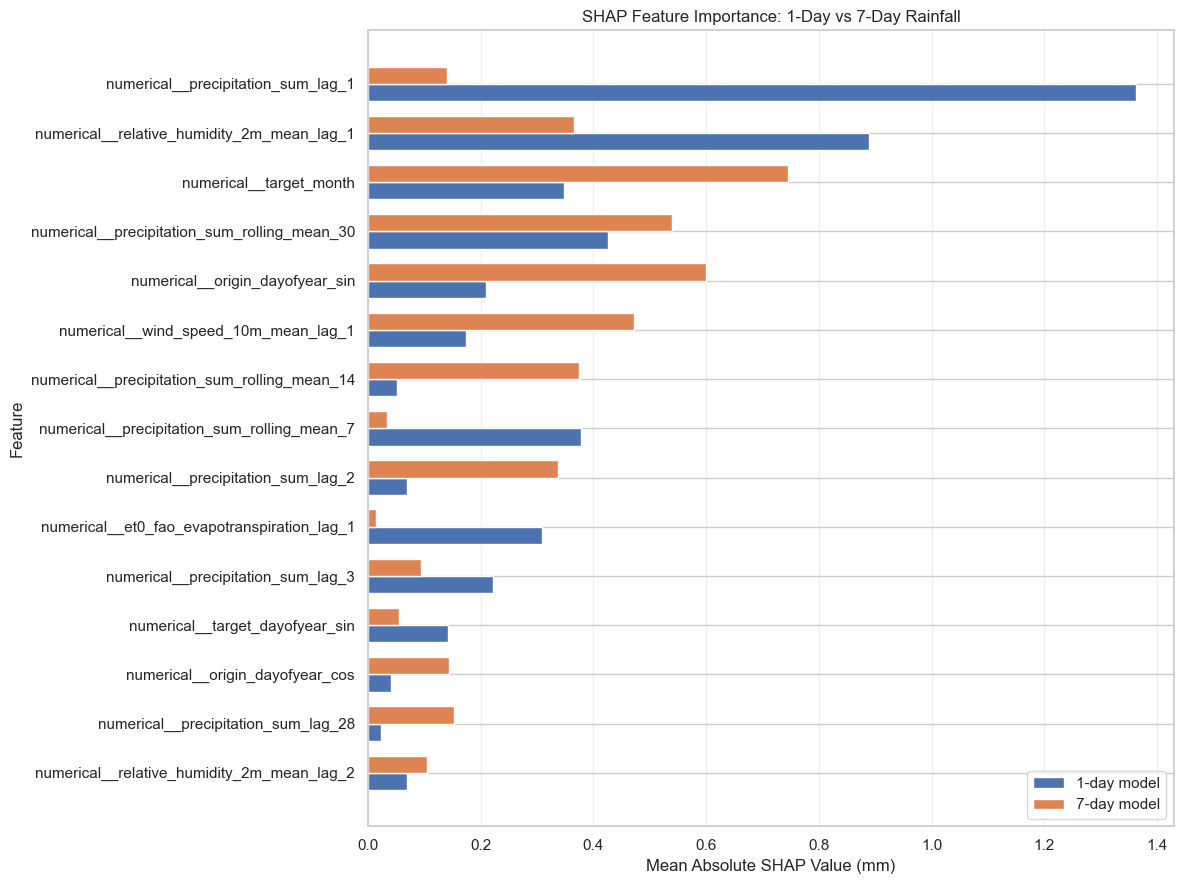

Rainfall SHAP comparison saved.


In [95]:
# Cell 85: Compare rainfall SHAP importance between horizons

rainfall_shap_comparison = pd.merge(
    rainfall_1day_shap_importance[
        ["feature", "mean_absolute_shap"]
    ].rename(columns={
        "mean_absolute_shap": "shap_1day"
    }),

    rainfall_7day_shap_importance[
        ["feature", "mean_absolute_shap"]
    ].rename(columns={
        "mean_absolute_shap": "shap_7day"
    }),

    on="feature",
    how="outer"
).fillna(0)

# Calculate combined importance
rainfall_shap_comparison["combined_importance"] = (
    rainfall_shap_comparison["shap_1day"]
    + rainfall_shap_comparison["shap_7day"]
)

# Select top 15 features
top_rainfall_comparison = (
    rainfall_shap_comparison
    .nlargest(15, "combined_importance")
    .sort_values("combined_importance")
)

# Create comparison chart
y = np.arange(len(top_rainfall_comparison))
height = 0.35

plt.figure(figsize=(12, 9))

plt.barh(
    y - height / 2,
    top_rainfall_comparison["shap_1day"],
    height,
    label="1-day model"
)

plt.barh(
    y + height / 2,
    top_rainfall_comparison["shap_7day"],
    height,
    label="7-day model"
)

plt.yticks(
    y,
    top_rainfall_comparison["feature"]
)

plt.xlabel("Mean Absolute SHAP Value (mm)")
plt.ylabel("Feature")

plt.title(
    "SHAP Feature Importance: 1-Day vs 7-Day Rainfall"
)

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Save comparison
rainfall_shap_comparison.to_csv(
    WEATHER_FORECASTING_DIR
    / "rainfall_shap_horizon_comparison.csv",
    index=False
)

print("Rainfall SHAP comparison saved.")

In [96]:
# Cell 86: Save SHAP feature importance results for all four models

SHAP_DIR = WEATHER_FORECASTING_DIR / "shap_analysis"
SHAP_DIR.mkdir(parents=True, exist_ok=True)

shap_results = {
    "temperature_1day": temperature_shap_importance,
    "temperature_7day": temperature_7day_shap_importance,
    "rainfall_1day": rainfall_1day_shap_importance,
    "rainfall_7day": rainfall_7day_shap_importance
}

saved_shap_files = []

for name, importance_df in shap_results.items():

    output_path = SHAP_DIR / f"{name}_shap_importance.csv"

    importance_df.to_csv(
        output_path,
        index=False
    )

    saved_shap_files.append({
        "filename": output_path.name,
        "number_of_features": len(importance_df),
        "file_size_kb": round(
            output_path.stat().st_size / 1024, 2
        )
    })

saved_shap_summary = pd.DataFrame(saved_shap_files)

display(saved_shap_summary)

print("\nAll four SHAP importance tables saved.")
print("Directory:", SHAP_DIR)

,filename,number_of_features,file_size_kb
0,temperature_1day_shap_importance.csv,115,6.59
1,temperature_7day_shap_importance.csv,115,6.58
2,rainfall_1day_shap_importance.csv,115,5.26
3,rainfall_7day_shap_importance.csv,115,6.12



All four SHAP importance tables saved.
Directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\shap_analysis


In [97]:
# Cell 87: Save SHAP feature importance charts

import matplotlib.pyplot as plt

shap_plot_results = {
    "temperature_1day": temperature_shap_importance,
    "temperature_7day": temperature_7day_shap_importance,
    "rainfall_1day": rainfall_1day_shap_importance,
    "rainfall_7day": rainfall_7day_shap_importance
}

saved_plot_files = []

for name, importance_df in shap_plot_results.items():

    top_features = (
        importance_df.head(20)
        .sort_values("mean_absolute_shap")
    )

    fig, ax = plt.subplots(figsize=(11, 8))

    ax.barh(
        top_features["feature"],
        top_features["mean_absolute_shap"]
    )

    if "temperature" in name:
        unit = "°C"
    else:
        unit = "mm"

    ax.set_xlabel(f"Mean Absolute SHAP Value ({unit})")
    ax.set_ylabel("Feature")
    ax.set_title(f"Top 20 SHAP Features - {name}")

    ax.grid(axis="x", alpha=0.3)

    fig.tight_layout()

    output_path = SHAP_DIR / f"{name}_shap_importance.png"

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    saved_plot_files.append(output_path.name)

print("Saved SHAP charts:")

for filename in saved_plot_files:
    print("-", filename)

print("\nTotal charts saved:", len(saved_plot_files))
print("Directory:", SHAP_DIR)

Saved SHAP charts:
- temperature_1day_shap_importance.png
- temperature_7day_shap_importance.png
- rainfall_1day_shap_importance.png
- rainfall_7day_shap_importance.png

Total charts saved: 4
Directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\shap_analysis


In [98]:
# Cell 88: Save SHAP horizon-comparison charts

comparison_plot_results = {
    "temperature_horizon_comparison": (
        temperature_shap_comparison,
        "shap_1day",
        "shap_7day",
        "SHAP Feature Importance: 1-Day vs 7-Day Temperature",
        "Mean Absolute SHAP Value (°C)"
    ),
    "rainfall_horizon_comparison": (
        rainfall_shap_comparison,
        "shap_1day",
        "shap_7day",
        "SHAP Feature Importance: 1-Day vs 7-Day Rainfall",
        "Mean Absolute SHAP Value (mm)"
    )
}

for name, (
    comparison_df,
    col_1day,
    col_7day,
    chart_title,
    x_label
) in comparison_plot_results.items():

    top_features = (
        comparison_df
        .nlargest(
            15,
            ["combined_importance"]
        )
        .sort_values("combined_importance")
    )

    y = np.arange(len(top_features))
    height = 0.35

    fig, ax = plt.subplots(figsize=(12, 9))

    ax.barh(
        y - height / 2,
        top_features[col_1day],
        height,
        label="1-day model"
    )

    ax.barh(
        y + height / 2,
        top_features[col_7day],
        height,
        label="7-day model"
    )

    ax.set_yticks(y)
    ax.set_yticklabels(top_features["feature"])

    ax.set_xlabel(x_label)
    ax.set_ylabel("Feature")
    ax.set_title(chart_title)

    ax.legend()
    ax.grid(axis="x", alpha=0.3)

    fig.tight_layout()

    output_path = SHAP_DIR / f"{name}.png"

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    print("Saved:", output_path.name)

print("\nBoth comparison charts saved successfully.")

Saved: temperature_horizon_comparison.png
Saved: rainfall_horizon_comparison.png

Both comparison charts saved successfully.


In [99]:
# Cell 89: Create consolidated SHAP summary

shap_summary_frames = []

shap_model_results = {
    "rainfall_1day": rainfall_1day_shap_importance,
    "rainfall_7day": rainfall_7day_shap_importance,
    "temperature_1day": temperature_shap_importance,
    "temperature_7day": temperature_7day_shap_importance
}

for model_name, importance_df in shap_model_results.items():

    model_summary = importance_df.head(20).copy()

    model_summary.insert(
        0,
        "model",
        model_name
    )

    model_summary.insert(
        1,
        "rank",
        range(1, len(model_summary) + 1)
    )

    shap_summary_frames.append(model_summary)

# Combine results
consolidated_shap_summary = pd.concat(
    shap_summary_frames,
    ignore_index=True
)

# Save results
shap_summary_path = (
    SHAP_DIR / "consolidated_shap_summary.csv"
)

consolidated_shap_summary.to_csv(
    shap_summary_path,
    index=False
)

display(consolidated_shap_summary)

print("\nConsolidated SHAP summary saved.")
print("Location:", shap_summary_path)
print(
    "Total records:",
    len(consolidated_shap_summary)
)

,model,rank,feature,mean_absolute_shap
0,rainfall_1day,1,numerical__precipitation_sum_lag_1,1.362261
1,rainfall_1day,2,numerical__relative_humidity_2m_mean_lag_1,0.889128
2,rainfall_1day,3,numerical__precipitation_sum_rolling_mean_30,0.426241
3,rainfall_1day,4,numerical__precipitation_sum_rolling_mean_7,0.377035
4,rainfall_1day,5,numerical__target_month,0.348017
5,rainfall_1day,6,numerical__et0_fao_evapotranspiration_lag_1,0.308438
6,rainfall_1day,7,numerical__precipitation_sum_lag_3,0.221220
7,rainfall_1day,8,numerical__origin_dayofyear_sin,0.209949
8,rainfall_1day,9,numerical__wind_speed_10m_mean_lag_1,0.173014
9,rainfall_1day,10,numerical__target_dayofyear_sin,0.141896



Consolidated SHAP summary saved.
Location: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\shap_analysis\consolidated_shap_summary.csv
Total records: 80


In [100]:
# Cell 90: Audit all weather forecasting artifacts

from pathlib import Path
import pandas as pd

# Define output directories
MODEL_DIR = PROJECT_ROOT / "models" / "weather_forecasting"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "weather_forecasting"

SHAP_DIR = OUTPUT_DIR / "shap_analysis"

# Expected important files
expected_files = [
    # Final trained models
    MODEL_DIR / "precipitation_sum_1day_model.joblib",
    MODEL_DIR / "precipitation_sum_7day_model.joblib",
    MODEL_DIR / "temperature_2m_mean_1day_model.joblib",
    MODEL_DIR / "temperature_2m_mean_7day_model.joblib",

    # Evaluation results
    OUTPUT_DIR / "all_weather_forecasting_validation_comparison.csv",
    OUTPUT_DIR / "weather_forecasting_baseline_improvement.csv",
    OUTPUT_DIR / "weather_forecasting_residual_statistics.csv",
    OUTPUT_DIR / "rainfall_error_by_intensity.csv",
    OUTPUT_DIR / "temperature_error_by_range.csv",
    OUTPUT_DIR / "weather_forecasting_district_error_analysis.csv",

    # SHAP results
    SHAP_DIR / "consolidated_shap_summary.csv",
    SHAP_DIR / "rainfall_shap_horizon_comparison.csv",
    SHAP_DIR / "temperature_shap_horizon_comparison.csv",
    SHAP_DIR / "rainfall_horizon_comparison.png",
    SHAP_DIR / "temperature_horizon_comparison.png"
]

# Check files
artifact_audit = []

for file_path in expected_files:

    artifact_audit.append({
        "filename": file_path.name,
        "category": file_path.parent.name,
        "exists": file_path.exists(),
        "file_size_kb": (
            round(file_path.stat().st_size / 1024, 2)
            if file_path.exists() else None
        )
    })

artifact_audit_df = pd.DataFrame(artifact_audit)

display(artifact_audit_df)

# Summary
total_files = len(artifact_audit_df)
existing_files = artifact_audit_df["exists"].sum()
missing_files = total_files - existing_files

print("\nWEATHER FORECASTING ARTIFACT AUDIT")
print("---------------------------------")
print("Expected files:", total_files)
print("Existing files:", existing_files)
print("Missing files:", missing_files)

# Save audit
audit_path = OUTPUT_DIR / "weather_forecasting_artifact_audit.csv"

artifact_audit_df.to_csv(audit_path, index=False)

print("\nAudit saved:", audit_path)

,filename,category,exists,file_size_kb
0,precipitation_sum_1day_model.joblib,weather_forecasting,True,98.36
1,precipitation_sum_7day_model.joblib,weather_forecasting,True,315.86
2,temperature_2m_mean_1day_model.joblib,weather_forecasting,True,5895.81
3,temperature_2m_mean_7day_model.joblib,weather_forecasting,True,5583.90
4,all_weather_forecasting_validation_comparison.csv,weather_forecasting,True,1.84
5,weather_forecasting_baseline_improvement.csv,weather_forecasting,True,0.44
6,weather_forecasting_residual_statistics.csv,weather_forecasting,True,0.68
7,rainfall_error_by_intensity.csv,weather_forecasting,True,1.02
8,temperature_error_by_range.csv,weather_forecasting,True,1.05
9,weather_forecasting_district_error_analysis.csv,weather_forecasting,True,9.10



WEATHER FORECASTING ARTIFACT AUDIT
---------------------------------
Expected files: 15
Existing files: 13
Missing files: 2

Audit saved: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\weather_forecasting_artifact_audit.csv


In [101]:
# Cell 91: Organize SHAP comparison CSV files

comparison_files = {
    "temperature_shap_horizon_comparison.csv":
        WEATHER_FORECASTING_DIR / "temperature_shap_horizon_comparison.csv",

    "rainfall_shap_horizon_comparison.csv":
        WEATHER_FORECASTING_DIR / "rainfall_shap_horizon_comparison.csv"
}

for filename, source_path in comparison_files.items():

    destination_path = SHAP_DIR / filename

    if source_path.exists():

        comparison_df = pd.read_csv(source_path)

        comparison_df.to_csv(
            destination_path,
            index=False
        )

        print("Organized:", filename)

    else:
        print("Source file not found:", source_path)

print("\nSHAP comparison file organization completed.")

Organized: temperature_shap_horizon_comparison.csv
Organized: rainfall_shap_horizon_comparison.csv

SHAP comparison file organization completed.


In [102]:
# Cell 92: Verify all weather forecasting artifacts

artifact_audit = []

for file_path in expected_files:

    artifact_audit.append({
        "filename": file_path.name,
        "category": file_path.parent.name,
        "exists": file_path.exists(),
        "file_size_kb": (
            round(file_path.stat().st_size / 1024, 2)
            if file_path.exists() else None
        )
    })

artifact_audit_df = pd.DataFrame(artifact_audit)

display(artifact_audit_df)

existing_files = artifact_audit_df["exists"].sum()
missing_files = len(artifact_audit_df) - existing_files

print("\nFINAL WEATHER FORECASTING ARTIFACT AUDIT")
print("----------------------------------------")
print("Expected files:", len(artifact_audit_df))
print("Existing files:", existing_files)
print("Missing files:", missing_files)

audit_path = OUTPUT_DIR / "weather_forecasting_artifact_audit.csv"

artifact_audit_df.to_csv(audit_path, index=False)

print("\nFinal audit saved:", audit_path)

,filename,category,exists,file_size_kb
0,precipitation_sum_1day_model.joblib,weather_forecasting,True,98.36
1,precipitation_sum_7day_model.joblib,weather_forecasting,True,315.86
2,temperature_2m_mean_1day_model.joblib,weather_forecasting,True,5895.81
3,temperature_2m_mean_7day_model.joblib,weather_forecasting,True,5583.90
4,all_weather_forecasting_validation_comparison.csv,weather_forecasting,True,1.84
5,weather_forecasting_baseline_improvement.csv,weather_forecasting,True,0.44
6,weather_forecasting_residual_statistics.csv,weather_forecasting,True,0.68
7,rainfall_error_by_intensity.csv,weather_forecasting,True,1.02
8,temperature_error_by_range.csv,weather_forecasting,True,1.05
9,weather_forecasting_district_error_analysis.csv,weather_forecasting,True,9.10



FINAL WEATHER FORECASTING ARTIFACT AUDIT
----------------------------------------
Expected files: 15
Existing files: 15
Missing files: 0

Final audit saved: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\weather_forecasting\weather_forecasting_artifact_audit.csv


In [103]:
# Cell 93: Prepare experiment documentation directory

from pathlib import Path

DOCUMENTATION_DIR = PROJECT_ROOT / "reports" / "weather_forecasting"

DOCUMENTATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Weather forecasting documentation directory:")
print(DOCUMENTATION_DIR)

print("\nDirectory exists:", DOCUMENTATION_DIR.exists())

Weather forecasting documentation directory:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\reports\weather_forecasting

Directory exists: True


In [104]:
# Cell 94: Create weather forecasting experiment report

REPORT_PATH = DOCUMENTATION_DIR / "weather_forecasting_experiment_report.md"

report_content = """# RiskWeave – Weather Forecasting Experiment Report

## 1. Project Overview

RiskWeave is a climate-informed dengue risk forecasting and inspection
planning system for Sri Lanka.

This experiment develops machine learning models to forecast daily
rainfall and daily mean temperature at district level.

The weather forecasting component investigates two forecast horizons:
- 1-day ahead
- 7-days ahead

## 2. Weather Data

### Data source
ERA5 historical/reanalysis weather data.

### Geographic coverage
25 districts in Sri Lanka.

### Temporal coverage
23 December 2006 to 19 December 2025.

### Dataset size
173,425 district-day records.

### Forecast targets
- Daily rainfall: precipitation_sum (mm)
- Daily mean temperature: temperature_2m_mean (°C)

## 3. Forecasting Methodology

The experiment uses historical weather observations to construct
forecasting features.

Feature engineering includes:
- Historical lag features.
- Rolling mean features.
- District information.
- Calendar and seasonal features.
- Target-date calendar features.

The forecasting horizons are 1 day and 7 days.

## 4. Data Splitting Strategy

Chronological splitting was used to avoid random mixing of past and
future observations.

- Training: target dates through 31 December 2023.
- Validation: 1 January 2024 to 31 December 2024.
- Testing: 1 January 2025 to 19 December 2025.

The validation period was used for model selection.
The test period was kept separate for final evaluation.

## 5. Models

Three machine learning algorithms were evaluated:

1. XGBoost
2. Histogram Gradient Boosting
3. Random Forest

A persistence baseline was also evaluated.

The persistence baseline uses the latest available observation at the
forecast origin.

## 6. Resource Considerations

The development environment has approximately 8 GB RAM.

To reduce memory usage:
- Numerical data was represented using float32 where appropriate.
- Lightweight model configurations were used.
- Training data was systematically sampled.
- Models were trained and evaluated separately.

The training sample contained approximately 51,575 records after
sampling, while validation and test datasets were evaluated using
their full available records.

## 7. Model Selection

Models were selected using validation MAE.

Selected models:

- Rainfall, 1-day: XGBoost
- Rainfall, 7-day: Histogram Gradient Boosting
- Temperature, 1-day: Random Forest
- Temperature, 7-day: Random Forest

## 8. Final Test Results

The independent test period was 1 January 2025 to 19 December 2025.

| Target | Horizon | Selected model | MAE | RMSE | R² |
|---|---:|---|---:|---:|---:|
| Rainfall | 1 day | XGBoost | 5.5991 mm | 12.5339 | 0.1296 |
| Rainfall | 7 days | Histogram Gradient Boosting | 6.0237 mm | 13.0329 | 0.0589 |
| Mean temperature | 1 day | Random Forest | 0.5598 °C | 0.7230 | 0.9522 |
| Mean temperature | 7 days | Random Forest | 0.6612 °C | 0.8380 | 0.9358 |

## 9. Persistence Baseline Comparison

All four selected models achieved lower test MAE than the persistence
baseline.

| Target | Horizon | Model MAE | Persistence MAE | MAE improvement |
|---|---:|---:|---:|---:|
| Rainfall | 1 day | 5.5991 | 6.6156 | 15.3653% |
| Rainfall | 7 days | 6.0237 | 8.0376 | 25.0556% |
| Mean temperature | 1 day | 0.5598 | 0.5985 | 6.4553% |
| Mean temperature | 7 days | 0.6612 | 0.8213 | 19.4922% |

The selected models also outperformed persistence in test RMSE and R².

## 10. Error Analysis

### Rainfall

Rainfall predictions showed limited ability to capture extreme rainfall.

The models tended to:
- Overpredict dry and light-rainfall observations.
- Underpredict moderate and heavy rainfall.
- Substantially underestimate very heavy rainfall events.

Rainfall test R² was modest, particularly for the 7-day horizon.

### Temperature

Temperature predictions showed strong agreement with observed values.

The 7-day horizon generally had higher errors than the 1-day horizon.
The warmest temperature category showed some underprediction.

### District-level performance

District-level error analysis was conducted for all 25 districts.

The results showed geographic variation in forecasting errors.
These differences should be interpreted descriptively rather than
attributed to specific geographic causes without further investigation.

## 11. SHAP Explainability

SHAP TreeExplainer was used to investigate feature importance.

The analysis used a sample of 200 test observations per model.

### Temperature

Recent temperature observations and rolling temperature averages
were among the most influential features.

The 1-day model relied more strongly on the previous day's
temperature, while the 7-day model showed greater reliance on
rolling averages.

### Rainfall

The 1-day rainfall model relied strongly on previous-day rainfall
and relative humidity.

The 7-day model showed greater influence from seasonal features,
longer-term rainfall averages and wind speed.

SHAP importance indicates model contribution, not causality.

## 12. Limitations

1. Rainfall forecasting performance is modest, especially for the
   7-day horizon.
2. Heavy and very heavy rainfall events are substantially
   underestimated.
3. Training used a systematic chronological sample because of
   hardware memory constraints.
4. The evaluation uses historical ERA5 reanalysis data.
5. ERA5 reanalysis is not itself an operational future weather
   forecast feed.
6. The models therefore demonstrate historical forecasting
   simulation performance, not verified live forecasting
   performance for future dates.

## 13. Reproducibility and Saved Outputs

The trained models are saved under:

models/weather_forecasting/

Evaluation outputs are saved under:

outputs/weather_forecasting/

SHAP outputs are saved under:

outputs/weather_forecasting/shap_analysis/

The artifact audit is saved as:

outputs/weather_forecasting/weather_forecasting_artifact_audit.csv

## 14. Conclusion

The experiment developed and evaluated district-level daily rainfall
and mean-temperature forecasting models for 1-day and 7-day horizons.

Temperature forecasting achieved strong test performance.
Rainfall forecasting improved over the persistence baseline, but
performance on extreme rainfall remains a significant limitation.

The saved models and evaluation artifacts provide a reproducible
foundation for the next stage of RiskWeave development.

Operational deployment requires an appropriate future weather
forecast input source and further evaluation using genuine forecast
inputs.
"""

with open(REPORT_PATH, "w", encoding="utf-8") as report_file:
    report_file.write(report_content)

print("Experiment report created successfully.")
print("Report path:", REPORT_PATH)
print("File exists:", REPORT_PATH.exists())
print("Report size (KB):", round(REPORT_PATH.stat().st_size / 1024, 2))

Experiment report created successfully.
Report path: c:\Users\Nethmi\Documents\GitHub\RiskWeave\reports\weather_forecasting\weather_forecasting_experiment_report.md
File exists: True
Report size (KB): 6.59


In [106]:
# Cell 95: Verify experiment report content

with open(REPORT_PATH, "r", encoding="utf-8") as file:
    report_text = file.read()

required_sections = [
    "Project Overview",
    "Weather Data",
    "Forecasting Methodology",
    "Data Splitting Strategy",
    "Models",
    "Final Test Results",
    "Persistence Baseline Comparison",
    "Error Analysis",
    "SHAP Explainability",
    "Limitations",
    "Reproducibility and Saved Outputs",
    "Conclusion"
]

print("REPORT QUALITY CHECK")
print("--------------------")

for section in required_sections:
    found = section in report_text
    print(f"{section}: {'PASS' if found else 'MISSING'}")

print("\nReport word count:", len(report_text.split()))
print("Report file size (KB):", round(REPORT_PATH.stat().st_size / 1024, 2))

REPORT QUALITY CHECK
--------------------
Project Overview: PASS
Weather Data: PASS
Forecasting Methodology: PASS
Data Splitting Strategy: PASS
Models: PASS
Final Test Results: PASS
Persistence Baseline Comparison: PASS
Error Analysis: PASS
SHAP Explainability: PASS
Limitations: PASS
Reproducibility and Saved Outputs: PASS
Conclusion: PASS

Report word count: 924
Report file size (KB): 6.59
